# **Taxis NYC — Preparación de datos, modelado y evaluación**
Actividad AIMLF1 · Módulo 2. Fuente: NYC TLC, enero de 2024.

Integrantes del Equipo:
1. Iris Carolina Elias
2. Gabriela Stefany Rodriguez
3. Astrid Ivette Alvarado

Herramientas: Python, Google Colab, XGBoost, KMeans, FastAPI y Streamlit.

**Objetivo:** desarrollar y documentar un proceso de análisis de datos y aprendizaje automático utilizando los registros de viajes de taxis de Nueva York de enero de 2024, mediante la preparación de datos, el pronóstico de demanda horaria, la segmentación de zonas y la evaluación de modelos, con el fin de generar información que apoye la toma de decisiones operativas.

**1. Instalación de librerías**

In [1]:
%pip -q install pandas pyarrow numpy matplotlib

**2. Carga y exploración inicial de datos**

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

URL_VIAJES = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
URL_ZONAS = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
viajes = pd.read_parquet(URL_VIAJES)
zonas = pd.read_csv(URL_ZONAS)
print("Viajes originales:", len(viajes))
print("Zonas catálogo:", len(zonas))
display(viajes.head(), zonas.head())

Viajes originales: 2964624
Zonas catálogo: 265


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


**3. Filtrado de viajes y selección de zonas**

Se conservan exclusivamente viajes iniciados en enero de 2024, con zona de origen reconocida y distinta de Unknown. El umbral de pronóstico es 3,000 viajes; para segmentación, 500.

In [3]:
viajes["tpep_pickup_datetime"] = pd.to_datetime(viajes["tpep_pickup_datetime"])
viajes = viajes.loc[(viajes["tpep_pickup_datetime"] >= "2024-01-01") & (viajes["tpep_pickup_datetime"] < "2024-02-01")].copy()
zonas_validas = zonas.loc[zonas["Zone"].fillna("").str.strip().str.lower().ne("unknown"), "LocationID"]
viajes = viajes.loc[viajes["PULocationID"].isin(zonas_validas)].copy()
conteos = viajes.groupby("PULocationID").size()
zonas_pronostico = sorted(conteos[conteos >= 3000].index.astype(int).tolist())
zonas_segmentacion = sorted(conteos[conteos >= 500].index.astype(int).tolist())
print("Viajes válidos:",len(viajes))
print("Zonas para pronóstico:",len(zonas_pronostico))
print("Zonas para segmentación:",len(zonas_segmentacion))

Viajes válidos: 2964606
Zonas para pronóstico: 59
Zonas para segmentación: 102


**4. Construcción de la serie temporal horaria**

Se cuentan los viajes por zona de origen y hora. Las combinaciones ausentes se rellenan con cero. Las 24 horas del 1 de febrero se reservan como futuro sin valor real.

In [4]:
viajes["hora"] = viajes["tpep_pickup_datetime"].dt.floor("h")
conteo_hora = (viajes.loc[viajes["PULocationID"].isin(zonas_pronostico)].groupby(["PULocationID","hora"]).size().rename("viajes"))
indice = pd.MultiIndex.from_product([zonas_pronostico, pd.date_range("2024-01-01", "2024-01-31 23:00", freq="h")], names=["PULocationID","hora"])
demanda = conteo_hora.reindex(indice,fill_value=0).reset_index()
futuro = pd.MultiIndex.from_product([zonas_pronostico, pd.date_range("2024-02-01", periods=24, freq="h")],names=["PULocationID","hora"]).to_frame(index=False)
futuro["viajes"] = np.nan
demanda = pd.concat([demanda,futuro],ignore_index=True).sort_values(["PULocationID","hora"]).reset_index(drop=True)
assert demanda.groupby("PULocationID").size().eq(768).all()
assert demanda.loc[demanda["hora"] >= "2024-02-01", "viajes"].isna().all()
print("Filas totales:",len(demanda))
display(demanda.head(),demanda.tail())

Filas totales: 45312


,PULocationID,hora,viajes
0,4,2024-01-01 00:00:00,25.0
1,4,2024-01-01 01:00:00,29.0
2,4,2024-01-01 02:00:00,34.0
3,4,2024-01-01 03:00:00,31.0
4,4,2024-01-01 04:00:00,32.0


,PULocationID,hora,viajes
45307,264,2024-02-01 19:00:00,NaN
45308,264,2024-02-01 20:00:00,NaN
45309,264,2024-02-01 21:00:00,NaN
45310,264,2024-02-01 22:00:00,NaN
45311,264,2024-02-01 23:00:00,NaN


**5. Ingeniería de variables temporales y división de datos**

Los lags son de al menos 24 horas porque se predice el día completo con información disponible hasta el día anterior.

In [5]:
g = demanda.groupby("PULocationID")["viajes"]
for n in [24,48,167,168,169]:
    demanda[f"lag_{n}"] = g.shift(n)
demanda["media_dia_ant"] = g.transform(lambda s: s.shift(24).rolling(24,min_periods=24).mean())
demanda["hora_dia"] = demanda["hora"].dt.hour
demanda["dia_semana"] = demanda["hora"].dt.dayofweek
demanda["feriado"] = demanda["hora"].dt.normalize().eq(pd.Timestamp("2024-01-15")).astype(int)
demanda["periodo"] = np.select([demanda["hora"] < "2024-01-25", demanda["hora"] < "2024-02-01"], ["entrenamiento","prueba"], default="futuro")
print(demanda["periodo"].value_counts())
display(demanda.loc[demanda["periodo"].eq("prueba")].head())

periodo
entrenamiento    33984
prueba            9912
futuro            1416
Name: count, dtype: int64


,PULocationID,hora,viajes,lag_24,lag_48,lag_167,lag_168,lag_169,media_dia_ant,hora_dia,dia_semana,feriado,periodo
576,4,2024-01-25 00:00:00,4.0,2.0,3.0,1.0,2.0,5.0,2.250000,0,3,0,prueba
577,4,2024-01-25 01:00:00,2.0,3.0,2.0,0.0,1.0,2.0,2.291667,1,3,0,prueba
578,4,2024-01-25 02:00:00,0.0,0.0,5.0,0.0,0.0,1.0,2.083333,2,3,0,prueba
579,4,2024-01-25 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,2.083333,3,3,0,prueba
580,4,2024-01-25 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,2.083333,4,3,0,prueba


**6. Exportación de archivos para la API y la aplicación**

In [6]:
Path("api").mkdir(exist_ok=True)
Path("app/data").mkdir(parents=True,exist_ok=True)
demanda.loc[demanda["periodo"].isin(["prueba","futuro"])].to_parquet("api/demanda.parquet",index=False)
zonas.loc[zonas["LocationID"].isin(zonas_pronostico)].to_csv("app/data/zonas_pronostico.csv",index=False)
print("Archivos iniciales guardados. Aún falta entrenar y validar el modelo.")

Archivos iniciales guardados. Aún falta entrenar y validar el modelo.


**7. Entrenamiento y evaluación del modelo de pronóstico**

El objetivo es entrenar un modelo XGBoost para pronosticar la demanda horaria de taxis, generar cuantiles de incertidumbre y evaluar su desempeño frente a una regla simple.

In [7]:

# ============================================================
# 7.1. PREPARACIÓN Y VALIDACIÓN DE DATOS PARA EL ENTRENAMIENTO
# ============================================================

# Definimos las variables que ayudarán a predecir la demanda.
# No incluimos "viajes" porque es nuestra variable objetivo.
variables = [
    "PULocationID",
    "lag_24",
    "lag_48",
    "lag_167",
    "lag_168",
    "lag_169",
    "media_dia_ant",
    "hora_dia",
    "dia_semana",
    "feriado"
]

# Identificamos la tabla creada en el apartado 5.
# Así evitamos asumir un nombre que no existe en Colab.
candidatos = [
    nombre for nombre in ["demanda", "base", "df_modelo"]
    if nombre in globals()
    and hasattr(globals()[nombre], "columns")
    and {"periodo", "viajes", *variables}.issubset(
        globals()[nombre].columns
    )
]

if not candidatos:
    raise ValueError(
        "No se encontró la tabla preparada. "
        "Revisa el nombre del DataFrame del apartado 5."
    )

datos_modelo = globals()[candidatos[0]]

# Separamos los datos respetando el orden temporal del PDF.
entrenamiento = datos_modelo[
    datos_modelo["periodo"] == "entrenamiento"
].copy()

prueba = datos_modelo[
    datos_modelo["periodo"] == "prueba"
].copy()

futuro = datos_modelo[
    datos_modelo["periodo"] == "futuro"
].copy()

# Verificamos los tamaños de cada conjunto.
print("REGISTROS POR PERÍODO")
print("Entrenamiento:", len(entrenamiento))
print("Prueba:", len(prueba))
print("Futuro:", len(futuro))

# Revisamos los valores faltantes de las variables.
# Algunos rezagos de enero estarán vacíos porque no existe
# información histórica anterior al inicio del dataset.
print("\nVALORES FALTANTES EN ENTRENAMIENTO")
print(entrenamiento[variables].isna().sum())

print("\nVALORES FALTANTES EN PRUEBA")
print(prueba[variables].isna().sum())

print("\nVALORES FALTANTES EN FUTURO")
print(futuro[variables].isna().sum())


REGISTROS POR PERÍODO
Entrenamiento: 33984
Prueba: 9912
Futuro: 1416

VALORES FALTANTES EN ENTRENAMIENTO
PULocationID        0
lag_24           1416
lag_48           2832
lag_167          9853
lag_168          9912
lag_169          9971
media_dia_ant    2773
hora_dia            0
dia_semana          0
feriado             0
dtype: int64

VALORES FALTANTES EN PRUEBA
PULocationID     0
lag_24           0
lag_48           0
lag_167          0
lag_168          0
lag_169          0
media_dia_ant    0
hora_dia         0
dia_semana       0
feriado          0
dtype: int64

VALORES FALTANTES EN FUTURO
PULocationID     0
lag_24           0
lag_48           0
lag_167          0
lag_168          0
lag_169          0
media_dia_ant    0
hora_dia         0
dia_semana       0
feriado          0
dtype: int64


In [8]:

# ============================================================
# 7.2. PREPARACIÓN FINAL PARA XGBOOST
# ============================================================

# Eliminamos del entrenamiento únicamente las filas que
# no cuentan con suficiente historial para calcular los lags.
entrenamiento_limpio = entrenamiento.dropna(
    subset=variables + ["viajes"]
).copy()

# XGBoost puede tratar las zonas como categorías.
# Usamos las mismas categorías en los tres conjuntos.
categorias_zona = sorted(
    datos_modelo["PULocationID"].unique()
)

for datos in [entrenamiento_limpio, prueba, futuro]:
    datos["PULocationID"] = pd.Categorical(
        datos["PULocationID"],
        categories=categorias_zona
    )

# Separamos las variables predictoras (X)
# de la variable que queremos pronosticar (y).
X_train = entrenamiento_limpio[variables]
y_train = entrenamiento_limpio["viajes"]

X_test = prueba[variables]
y_test = prueba["viajes"]

X_futuro = futuro[variables]

# Comprobamos los conjuntos definitivos.
print("DATOS LISTOS PARA XGBOOST")
print("Entrenamiento efectivo:", len(X_train))
print("Prueba:", len(X_test))
print("Futuro:", len(X_futuro))

print("\nTipos de variables:")
print(X_train.dtypes)

print("\nPrimer registro de entrenamiento:")
display(entrenamiento_limpio[
    ["PULocationID", "hora", "viajes", "lag_24", "lag_168"]
].head(1))


DATOS LISTOS PARA XGBOOST
Entrenamiento efectivo: 24013
Prueba: 9912
Futuro: 1416

Tipos de variables:
PULocationID     category
lag_24            float64
lag_48            float64
lag_167           float64
lag_168           float64
lag_169           float64
media_dia_ant     float64
hora_dia            int32
dia_semana          int32
feriado             int64
dtype: object

Primer registro de entrenamiento:


,PULocationID,hora,viajes,lag_24,lag_168
169,4,2024-01-08 01:00:00,0.0,26.0,29.0


In [9]:

# ============================================================
# 7.3. CONFIGURACIÓN Y ENTRENAMIENTO DEL MODELO XGBOOST
# ============================================================

# Instalamos XGBoost para asegurar que Colab tenga disponible
# una versión compatible con la regresión por cuantiles.
%pip -q install "xgboost>=2.1,<4"

import xgboost as xgb
import numpy as np
from xgboost import XGBRegressor

# ------------------------------------------------------------
# 7.3.1. Definición de cuantiles
# ------------------------------------------------------------

# Generaremos nueve niveles de demanda:
# p10, p20, p30, p40, p50, p60, p70, p80 y p90.
cuantiles = np.arange(0.1, 1.0, 0.1).round(1)

# ------------------------------------------------------------
# 7.3.2. Configuración del modelo
# ------------------------------------------------------------

modelo = XGBRegressor(
    objective="reg:quantileerror",  # Predicción por cuantiles
    quantile_alpha=cuantiles,       # Nueve cuantiles
    n_estimators=250,              # Número de rondas de árboles
    max_depth=5,                   # Profundidad máxima
    learning_rate=0.05,            # Velocidad de aprendizaje
    tree_method="hist",            # Método eficiente de entrenamiento
    enable_categorical=True,       # Reconoce la zona como categoría
    random_state=42,               # Reproducibilidad
    n_jobs=-1                      # Utiliza los núcleos disponibles
)

# ------------------------------------------------------------
# 7.3.3. Entrenamiento
# ------------------------------------------------------------

# El modelo aprende la relación entre las variables
# predictoras (X_train) y los viajes reales (y_train).
# No utilizamos datos de prueba ni del 1 de febrero.
print("Iniciando entrenamiento de XGBoost...")

modelo.fit(X_train, y_train)

print("Entrenamiento finalizado correctamente.")

# ------------------------------------------------------------
# 7.3.4. Verificación inicial
# ------------------------------------------------------------

print("\nVersión de XGBoost:", xgb.__version__)
print("Cuantiles configurados:", cuantiles)
print("Registros utilizados:", len(X_train))
print("Variables utilizadas:", len(variables))


Iniciando entrenamiento de XGBoost...
Entrenamiento finalizado correctamente.

Versión de XGBoost: 3.4.1
Cuantiles configurados: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]
Registros utilizados: 24013
Variables utilizadas: 10


In [10]:

# ============================================================
# 7.4. GENERACIÓN Y VALIDACIÓN DE PRONÓSTICOS
# ============================================================

# 7.4.1. Comprobamos que los datos estén completos.
assert X_test[variables].notna().all().all(), \
    "Existen variables faltantes en prueba."

# 7.4.2. Generamos los nueve cuantiles por registro.
# Cada fila corresponde a una zona y una hora.
predicciones = modelo.predict(X_test)

# 7.4.3. Ordenamos los cuantiles de menor a mayor.
# Esto evita que un cuantil alto quede debajo de uno bajo.
predicciones = np.sort(predicciones, axis=1)

# La demanda de viajes no puede ser negativa.
predicciones = np.maximum(predicciones, 0)

# 7.4.4. Creamos una tabla con las predicciones y
# los valores reales para evaluarlos posteriormente.
resultados_prueba = prueba[
    ["PULocationID", "hora", "viajes", "lag_168"]
].copy()

# Incorporamos los cuantiles del 10 % al 90 %.
for i, q in enumerate(cuantiles):
    nombre = f"p{int(round(q * 100))}"
    resultados_prueba[nombre] = predicciones[:, i]

# Renombramos las columnas para facilitar su lectura.
resultados_prueba = resultados_prueba.rename(
    columns={
        "viajes": "real",
        "lag_168": "hace_una_semana"
    }
)

# 7.4.5. Verificamos la estructura del resultado.
print("REGISTROS PRONOSTICADOS:", len(resultados_prueba))
print("ZONAS:", resultados_prueba["PULocationID"].nunique())
print("FECHAS:", resultados_prueba["hora"].dt.date.nunique())

print("\nEJEMPLO DE PRONÓSTICOS:")
display(resultados_prueba[
    ["PULocationID", "hora", "real",
     "hace_una_semana", "p10", "p50", "p90"]
].head(10))

# 7.4.6. Comprobamos que los cuantiles estén ordenados.
columnas_cuantiles = [
    f"p{int(round(q * 100))}" for q in cuantiles
]

cuantiles_ordenados = (
    np.diff(
        resultados_prueba[columnas_cuantiles].to_numpy(),
        axis=1
    ) >= 0
).all()

print("\n¿CUANTILES CORRECTAMENTE ORDENADOS?",
      cuantiles_ordenados)


REGISTROS PRONOSTICADOS: 9912
ZONAS: 59
FECHAS: 7

EJEMPLO DE PRONÓSTICOS:


,PULocationID,hora,real,hace_una_semana,p10,p50,p90
576,4,2024-01-25 00:00:00,4.0,2.0,0.064280,1.951946,17.760496
577,4,2024-01-25 01:00:00,2.0,1.0,0.000000,0.869062,16.903885
578,4,2024-01-25 02:00:00,0.0,0.0,0.000000,0.338535,16.834545
579,4,2024-01-25 03:00:00,0.0,0.0,0.000000,0.338535,16.834545
580,4,2024-01-25 04:00:00,0.0,0.0,0.000000,0.338535,16.834545
581,4,2024-01-25 05:00:00,1.0,0.0,0.000000,0.751233,16.987871
582,4,2024-01-25 06:00:00,3.0,5.0,0.436591,2.461187,18.497549
583,4,2024-01-25 07:00:00,4.0,5.0,1.818892,5.256443,21.574160
584,4,2024-01-25 08:00:00,7.0,8.0,1.755678,5.524066,21.263235
585,4,2024-01-25 09:00:00,11.0,6.0,2.144237,6.034538,21.532595



¿CUANTILES CORRECTAMENTE ORDENADOS? True


COMPARACIÓN DE MODELOS


,Método,MAE,RMSE
0,XGBoost (p50),11.88,22.82
1,Igual que hace una semana,11.76,21.71



Mejora de XGBoost frente a la regla simple: -0.99%


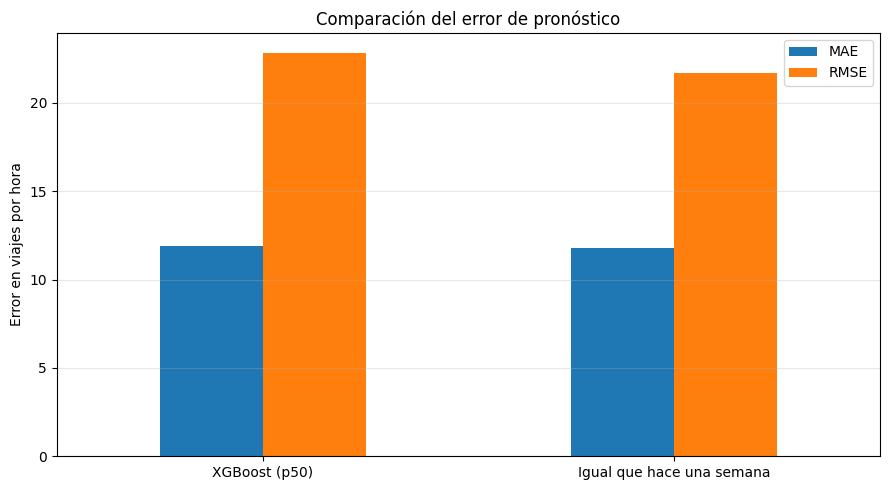

In [11]:

# ============================================================
# 7.5. EVALUACIÓN DEL MODELO FRENTE A UNA REGLA SIMPLE
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# 7.5.1. Definimos las tres series que compararemos.
# REAL: demanda observada durante el período de prueba.
# XGBOOST: pronóstico central del modelo (p50).
# REGLA SIMPLE: demanda observada a la misma hora
# de hace una semana (lag_168).

real = resultados_prueba["real"]
pronostico_xgb = resultados_prueba["p50"]
pronostico_semana = resultados_prueba["hace_una_semana"]

# 7.5.2. Calculamos el MAE.
# Cuanto menor sea, mejor es el pronóstico.
mae_xgb = mean_absolute_error(real, pronostico_xgb)
mae_semana = mean_absolute_error(real, pronostico_semana)

# 7.5.3. Calculamos el RMSE.
# Este indicador penaliza más los errores grandes.
rmse_xgb = np.sqrt(
    mean_squared_error(real, pronostico_xgb)
)

rmse_semana = np.sqrt(
    mean_squared_error(real, pronostico_semana)
)

# 7.5.4. Comparamos ambos métodos.
comparacion = pd.DataFrame({
    "Método": ["XGBoost (p50)", "Igual que hace una semana"],
    "MAE": [mae_xgb, mae_semana],
    "RMSE": [rmse_xgb, rmse_semana]
})

print("COMPARACIÓN DE MODELOS")
display(comparacion.round(2))

# 7.5.5. Calculamos la mejora porcentual en MAE.
# Un resultado positivo significa que XGBoost mejora
# la regla simple; uno negativo significa que empeora.
mejora_mae = (
    (mae_semana - mae_xgb) / mae_semana * 100
    if mae_semana > 0 else np.nan
)

print(f"\nMejora de XGBoost frente a la regla simple: {mejora_mae:.2f}%")

# 7.5.6. Visualizamos los resultados.
import matplotlib.pyplot as plt

comparacion.set_index("Método")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Comparación del error de pronóstico")
plt.ylabel("Error en viajes por hora")
plt.xlabel("")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de resultados:** Durante el período de prueba comprendido entre el 25 y el 31 de enero de 2024, el modelo XGBoost obtuvo un error absoluto medio (MAE) de 11.88 viajes por zona y hora, frente a 11.76 de la regla basada en la demanda de la semana anterior. Esto representa una diferencia desfavorable de aproximadamente 0.99 % para XGBoost.

Asimismo, el RMSE fue de 22.82 para XGBoost y 21.71 para la regla simple. Por tanto, el modelo no logró superar el desempeño de referencia en precisión puntual.

Sin embargo, XGBoost proporciona una ventaja adicional al generar pronósticos probabilísticos mediante cuantiles, cuya utilidad se evaluará a través de la cobertura de los intervalos de incertidumbre.

COBERTURA GLOBAL P10-P90: 89.86%
COBERTURA ESPERADA: 80.00%
AMPLITUD PROMEDIO: 48.88 viajes

COBERTURA POR DÍA:


,fecha,cobertura_pct,amplitud_promedio
0,2024-01-25,91.74,45.410000
1,2024-01-26,92.44,46.060001
2,2024-01-27,86.51,51.930000
3,2024-01-28,86.94,53.560001
4,2024-01-29,89.69,54.689999
5,2024-01-30,90.25,45.410000
6,2024-01-31,91.45,45.080002


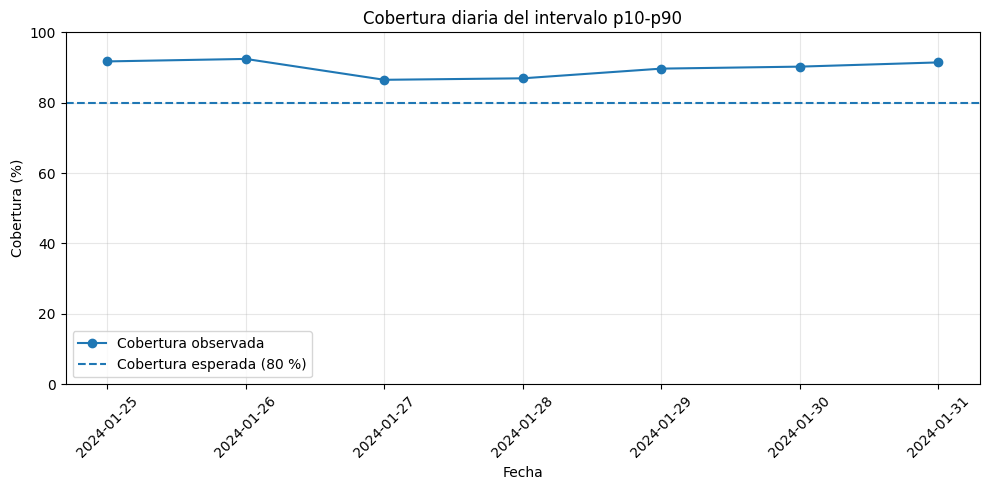

In [12]:

# ============================================================
# 7.6. EVALUACIÓN DE LA INCERTIDUMBRE DEL PRONÓSTICO
# ============================================================

# 7.6.1. Verificamos si la demanda real quedó dentro
# del intervalo definido por los cuantiles p10 y p90.
resultados_prueba["dentro_intervalo"] = (
    (resultados_prueba["real"] >= resultados_prueba["p10"]) &
    (resultados_prueba["real"] <= resultados_prueba["p90"])
)

# 7.6.2. Calculamos la cobertura del intervalo.
# Idealmente, un intervalo p10-p90 debería cubrir
# aproximadamente el 80 % de las observaciones.
cobertura = resultados_prueba["dentro_intervalo"].mean() * 100

# 7.6.3. Calculamos la amplitud del intervalo.
# Una amplitud menor implica mayor precisión del rango,
# siempre que la cobertura siga siendo adecuada.
resultados_prueba["amplitud_intervalo"] = (
    resultados_prueba["p90"] - resultados_prueba["p10"]
)

amplitud_promedio = resultados_prueba["amplitud_intervalo"].mean()

# 7.6.4. Calculamos la cobertura por día para identificar
# posibles diferencias durante la semana de prueba.
resultados_prueba["fecha"] = resultados_prueba["hora"].dt.date

cobertura_diaria = (
    resultados_prueba.groupby("fecha")
    .agg(
        cobertura_pct=("dentro_intervalo", "mean"),
        amplitud_promedio=("amplitud_intervalo", "mean")
    )
    .reset_index()
)

cobertura_diaria["cobertura_pct"] *= 100

# 7.6.5. Mostramos los resultados.
print(f"COBERTURA GLOBAL P10-P90: {cobertura:.2f}%")
print(f"COBERTURA ESPERADA: 80.00%")
print(f"AMPLITUD PROMEDIO: {amplitud_promedio:.2f} viajes")

print("\nCOBERTURA POR DÍA:")
display(cobertura_diaria.round(2))

# 7.6.6. Visualizamos la cobertura diaria.
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    cobertura_diaria["fecha"].astype(str),
    cobertura_diaria["cobertura_pct"],
    marker="o",
    label="Cobertura observada"
)

plt.axhline(
    y=80,
    linestyle="--",
    label="Cobertura esperada (80 %)"
)

plt.title("Cobertura diaria del intervalo p10-p90")
plt.xlabel("Fecha")
plt.ylabel("Cobertura (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de la incertidumbre:** El modelo XGBoost obtuvo una cobertura global del 89.86 % para el intervalo comprendido entre los cuantiles p10 y p90, superando en 9.86 puntos porcentuales la cobertura nominal del 80 %.

La amplitud promedio del intervalo fue de 48.88 viajes por zona y hora. Aunque la cobertura observada indica que la mayoría de los valores reales se encuentran dentro de los límites estimados, también sugiere que los intervalos podrían ser más amplios de lo necesario.

La cobertura diaria se mantuvo por encima del 80 % durante todo el período de prueba, con valores entre 86.51 % y 92.44 %.

En consecuencia, el modelo ofrece una estimación conservadora de la incertidumbre, pero requiere evaluar el equilibrio entre cobertura y amplitud para determinar su utilidad en la planificación operativa.

IMPORTANCIA DE VARIABLES


,Variable,Importancia,Importancia (%)
0,lag_168,0.67,66.870003
1,lag_24,0.17,16.660000
2,lag_167,0.05,4.680000
3,lag_169,0.03,3.430000
4,PULocationID,0.02,2.380000
5,hora_dia,0.02,1.740000
6,dia_semana,0.02,1.630000
7,lag_48,0.01,1.160000
8,media_dia_ant,0.01,0.870000
9,feriado,0.01,0.570000


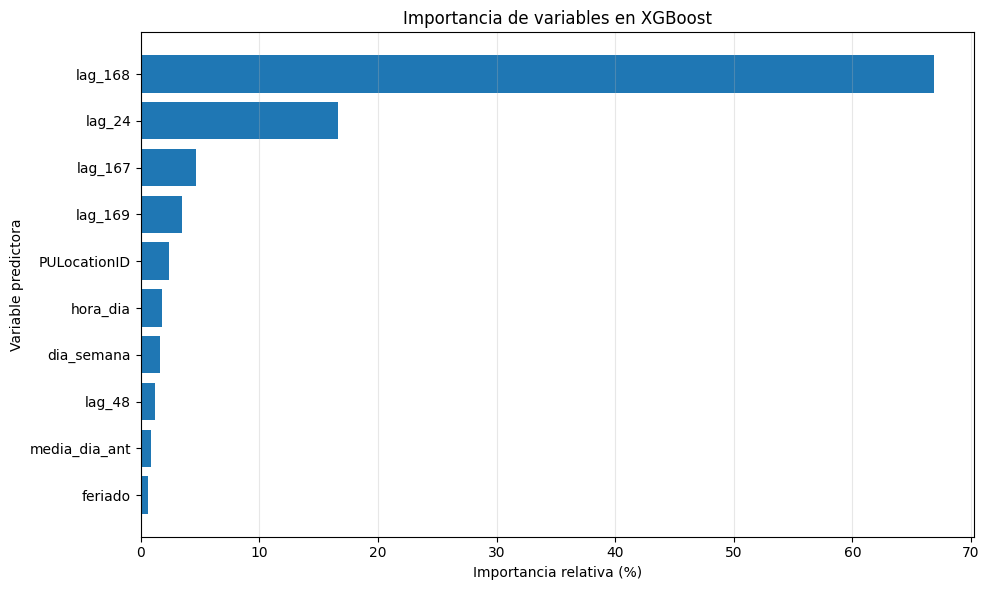

In [13]:

# ============================================================
# 7.7. IMPORTANCIA DE VARIABLES DEL MODELO XGBOOST
# ============================================================

# 7.7.1. Obtenemos la importancia de cada variable.
# XGBoost calcula cuánto contribuyen las variables
# a las divisiones de los árboles del modelo.
importancias = modelo.feature_importances_

# 7.7.2. Creamos una tabla con los resultados.
tabla_importancia = pd.DataFrame({
    "Variable": variables,
    "Importancia": importancias
})

# Ordenamos de mayor a menor importancia.
tabla_importancia = tabla_importancia.sort_values(
    "Importancia",
    ascending=False
).reset_index(drop=True)

# Convertimos la importancia relativa a porcentaje.
tabla_importancia["Importancia (%)"] = (
    tabla_importancia["Importancia"] * 100
)

print("IMPORTANCIA DE VARIABLES")
display(tabla_importancia.round(2))

# 7.7.3. Visualizamos los resultados.
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    tabla_importancia["Variable"],
    tabla_importancia["Importancia (%)"]
)

plt.gca().invert_yaxis()

plt.title("Importancia de variables en XGBoost")
plt.xlabel("Importancia relativa (%)")
plt.ylabel("Variable predictora")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de la importancia de variables:** El análisis de importancia del modelo XGBoost identificó a `lag_168` (demanda a la misma hora de la semana anterior) como la variable predominante, con una importancia relativa del 66.87 %, seguida de `lag_24` (demanda a la misma hora del día anterior), con 16.66 %.

Ambas variables concentran el 83.53 % de la importancia total, lo que evidencia el peso de los patrones históricos diarios y semanales en las predicciones del modelo.

Este resultado es consistente con la evaluación previa, donde la regla simple basada en la demanda de la semana anterior obtuvo un error ligeramente inferior al de XGBoost.

Las demás variables, como la zona de origen, la hora del día y el día de la semana, presentaron una importancia relativa menor. Estos resultados describen la importancia asignada por el modelo, pero no deben interpretarse como relaciones causales.

In [14]:

# ============================================================
# 7.8. GUARDADO DEL MODELO PARA FASTAPI
# ============================================================

from pathlib import Path
import json

# 7.8.1. Creamos la carpeta donde se almacenará el modelo.
ruta_api = Path("api")
ruta_api.mkdir(parents=True, exist_ok=True)

# 7.8.2. Guardamos el modelo entrenado en formato UBJ.
# Este archivo será utilizado por FastAPI para generar
# pronósticos sin necesidad de volver a entrenar.
ruta_modelo = ruta_api / "modelo_pronostico.ubj"
modelo.save_model(str(ruta_modelo))

# 7.8.3. Guardamos información necesaria para
# reconstruir las variables de entrada en la API.
configuracion = {
    "variables": variables,
    "cuantiles": cuantiles.tolist(),
    "categorias_zona": [int(z) for z in categorias_zona],
    "version_xgboost": xgb.__version__
}

ruta_config = ruta_api / "configuracion_modelo.json"

with open(ruta_config, "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, indent=4)

# 7.8.4. Comprobamos que los archivos se guardaron.
print("MODELO GUARDADO CORRECTAMENTE")
print("Archivo:", ruta_modelo)
print("Tamaño:", round(ruta_modelo.stat().st_size / 1024**2, 2), "MB")

print("\nCONFIGURACIÓN GUARDADA")
print("Archivo:", ruta_config)
print("Variables:", len(variables))
print("Cuantiles:", len(cuantiles))

# 7.8.5. Verificamos que el modelo pueda cargarse.
modelo_verificacion = XGBRegressor()
modelo_verificacion.load_model(str(ruta_modelo))

print("\nVerificación de carga: correcta")


MODELO GUARDADO CORRECTAMENTE
Archivo: api/modelo_pronostico.ubj
Tamaño: 9.15 MB

CONFIGURACIÓN GUARDADA
Archivo: api/configuracion_modelo.json
Variables: 10
Cuantiles: 9

Verificación de carga: correcta


In [15]:

# ============================================================
# 7.9. VALIDACIÓN FINAL DEL MODELO
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 7.9.1. Verificación del modelo guardado
# ------------------------------------------------------------

# Comparamos las predicciones del modelo original con las
# del modelo que recuperamos del archivo .ubj.
# Utilizamos 100 registros del conjunto de prueba.
muestra = X_test.head(100)

pred_original = modelo.predict(muestra)
pred_recargado = modelo_verificacion.predict(muestra)

# allclose comprueba que los resultados sean iguales,
# permitiendo diferencias numéricas muy pequeñas.
modelo_consistente = np.allclose(
    pred_original,
    pred_recargado,
    rtol=1e-6,
    atol=1e-6
)

print("VALIDACIÓN DEL MODELO GUARDADO")
print("¿Predicciones consistentes?:", modelo_consistente)

# ------------------------------------------------------------
# 7.9.2. Verificación de los rezagos históricos
# ------------------------------------------------------------

# Para pronosticar un día completo, las variables históricas
# deben referirse a horas anteriores al inicio de ese día.
#
# El rezago más corto utilizado es lag_24:
# para las 00:00 consulta las 00:00 del día anterior;
# para las 23:00 consulta las 23:00 del día anterior.

fecha_pronostico = prueba["hora"].dt.normalize()

validaciones = pd.DataFrame({
    "fecha_pronostico": fecha_pronostico,
    "lag_24": prueba["hora"] - pd.Timedelta(hours=24),
    "lag_48": prueba["hora"] - pd.Timedelta(hours=48),
    "lag_167": prueba["hora"] - pd.Timedelta(hours=167),
    "lag_168": prueba["hora"] - pd.Timedelta(hours=168),
    "lag_169": prueba["hora"] - pd.Timedelta(hours=169)
})

# Comprobamos que ningún rezago consulte el mismo día
# que se está pronosticando.
columnas_lags = [
    "lag_24", "lag_48", "lag_167",
    "lag_168", "lag_169"
]

rezagos_validos = all(
    (validaciones[col] < validaciones["fecha_pronostico"]).all()
    for col in columnas_lags
)

print("\nVALIDACIÓN TEMPORAL")
print("¿Todos los rezagos son anteriores al día pronosticado?:",
      rezagos_validos)

# ------------------------------------------------------------
# 7.9.3. Comprobación de integridad
# ------------------------------------------------------------

# Verificamos que las predicciones no tengan valores
# faltantes ni infinitos.
predicciones_validas = np.isfinite(
    resultados_prueba[columnas_cuantiles].to_numpy()
).all()

print("\nVALIDACIÓN DE PREDICCIONES")
print("¿Predicciones sin NaN ni infinitos?:",
      predicciones_validas)

# Resultado general.
validacion_general = (
    modelo_consistente
    and rezagos_validos
    and predicciones_validas
)

print("\n¿VALIDACIONES SUPERADAS?:", validacion_general)


VALIDACIÓN DEL MODELO GUARDADO
¿Predicciones consistentes?: True

VALIDACIÓN TEMPORAL
¿Todos los rezagos son anteriores al día pronosticado?: True

VALIDACIÓN DE PREDICCIONES
¿Predicciones sin NaN ni infinitos?: True

¿VALIDACIONES SUPERADAS?: True


 **8. Segmentación de zonas mediante K-Means**

**Objetivo:** identificar grupos de zonas de Nueva York con patrones similares de demanda y características de los viajes, utilizando técnicas de aprendizaje no supervisado.


In [17]:

# ============================================================
# 8.1. CONSTRUCCIÓN DEL PERFIL DE COMPORTAMIENTO POR ZONA
# ============================================================

import pandas as pd
import numpy as np

# 8.1.1. Seleccionamos las zonas con al menos 500 viajes.
# Esta lista fue construida en el apartado 3.
viajes_segmentacion = viajes[
    viajes["PULocationID"].isin(zonas_segmentacion)
].copy()

# 8.1.2. Creamos variables temporales para identificar
# cuándo se concentra la demanda.
viajes_segmentacion["hora_dia"] = (
    viajes_segmentacion["tpep_pickup_datetime"].dt.hour
)

viajes_segmentacion["dia_semana"] = (
    viajes_segmentacion["tpep_pickup_datetime"].dt.dayofweek
)

# Identificamos viajes nocturnos: 22:00 a 05:59.
viajes_segmentacion["nocturno"] = (
    (viajes_segmentacion["hora_dia"] >= 22) |
    (viajes_segmentacion["hora_dia"] < 6)
).astype(int)

# Identificamos viajes en fin de semana.
viajes_segmentacion["fin_semana"] = (
    viajes_segmentacion["dia_semana"] >= 5
).astype(int)

# 8.1.3. Calculamos indicadores por zona.
# Cada fila de esta tabla representará una zona.
perfil_zonas = (
    viajes_segmentacion.groupby("PULocationID")
    .agg(
        total_viajes=("PULocationID", "size"),
        distancia_promedio=("trip_distance", "mean"),
        tarifa_promedio=("fare_amount", "mean"),
        propina_promedio=("tip_amount", "mean"),
        proporcion_nocturna=("nocturno", "mean"),
        proporcion_fin_semana=("fin_semana", "mean")
    )
    .reset_index()
)

# 8.1.4. Agregamos los nombres y distritos del catálogo.
perfil_zonas = perfil_zonas.merge(
    zonas[["LocationID", "Borough", "Zone"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

# 8.1.5. Verificamos los resultados.
print("ZONAS ANALIZADAS:", len(perfil_zonas))

print("\nPERFIL DE ZONAS:")
display(perfil_zonas.head(10))

print("\nVALORES FALTANTES:")
print(perfil_zonas.isna().sum())

print("\nRESUMEN ESTADÍSTICO:")
display(perfil_zonas.describe().round(2))


ZONAS ANALIZADAS: 102

PERFIL DE ZONAS:


,PULocationID,total_viajes,distancia_promedio,tarifa_promedio,propina_promedio,proporcion_nocturna,proporcion_fin_semana,Borough,Zone
0,4,3568,29.954406,16.693960,2.393627,0.591648,0.549327,Manhattan,Alphabet City
1,7,1811,3.447311,20.116289,1.421568,0.205411,0.315295,Queens,Astoria
2,10,999,11.087518,54.533834,6.840320,0.181181,0.229229,Queens,Baisley Park
3,12,875,4.450263,23.255291,3.363211,0.024000,0.262857,Manhattan,Battery Park
4,13,15877,4.302839,22.182556,4.115413,0.048057,0.174655,Manhattan,Battery Park City
5,17,516,4.503159,27.266124,0.937907,0.244186,0.191860,Brooklyn,Bedford
6,24,7849,2.430535,15.207256,2.686019,0.078609,0.246273,Manhattan,Bloomingdale
7,25,1051,4.441703,24.497431,2.222103,0.256898,0.305423,Brooklyn,Boerum Hill
8,33,1257,62.022951,25.668894,3.329650,0.141607,0.190931,Brooklyn,Brooklyn Heights
9,35,546,6.005037,31.320183,0.158846,0.089744,0.144689,Brooklyn,Brownsville



VALORES FALTANTES:
PULocationID             0
total_viajes             0
distancia_promedio       0
tarifa_promedio          0
propina_promedio         0
proporcion_nocturna      0
proporcion_fin_semana    0
Borough                  1
Zone                     1
dtype: int64

RESUMEN ESTADÍSTICO:


,PULocationID,total_viajes,distancia_promedio,tarifa_promedio,propina_promedio,proporcion_nocturna,proporcion_fin_semana
count,102.00,102.00,102.00,102.00,102.00,102.00,102.00
mean,138.41,28835.50,5.81,22.58,2.85,0.20,0.26
std,78.26,38484.98,8.89,11.45,1.62,0.13,0.08
min,4.00,504.00,1.20,8.57,0.14,0.02,0.10
25%,74.25,949.25,2.40,14.96,2.25,0.12,0.22
50%,140.50,6920.00,3.50,20.07,2.74,0.17,0.25
75%,215.75,48232.50,4.89,26.16,3.06,0.23,0.29
max,265.00,145240.00,62.02,82.33,8.86,0.72,0.55


In [18]:

# ============================================================
# 8.2. DIAGNÓSTICO DE CALIDAD Y VALORES EXTREMOS
# ============================================================

# 8.2.1. Identificamos las zonas sin nombre o distrito.
# No eliminamos registros hasta conocer su origen.
print("ZONAS SIN INFORMACIÓN EN EL CATÁLOGO")

zonas_sin_nombre = perfil_zonas[
    perfil_zonas[["Borough", "Zone"]].isna().any(axis=1)
]

display(zonas_sin_nombre)

# 8.2.2. Revisamos la distribución de las distancias.
# Los percentiles altos ayudan a detectar valores extremos.
print("\nDISTRIBUCIÓN DE DISTANCIAS")

percentiles = [0.50, 0.90, 0.95, 0.99, 0.999]

display(
    viajes_segmentacion["trip_distance"]
    .describe(percentiles=percentiles)
    .to_frame(name="Distancia (millas)")
)

# 8.2.3. Identificamos los 10 viajes con mayor distancia.
# Así podemos observar si existen registros inusuales.
print("\nDIEZ VIAJES CON MAYOR DISTANCIA")

display(
    viajes_segmentacion.nlargest(
        10, "trip_distance"
    )[
        [
            "PULocationID",
            "tpep_pickup_datetime",
            "trip_distance",
            "fare_amount",
            "total_amount"
        ]
    ]
)

# 8.2.4. Contamos los viajes con distancias superiores
# a 100 millas como referencia de diagnóstico.
# Este umbral NO es todavía una regla de exclusión.
viajes_extremos = (
    viajes_segmentacion["trip_distance"] > 100
).sum()

print("\nVIAJES CON DISTANCIA MAYOR A 100 MILLAS:",
      viajes_extremos)

print(
    "Porcentaje:",
    round(
        viajes_extremos / len(viajes_segmentacion) * 100,
        4
    ),
    "%"
)


ZONAS SIN INFORMACIÓN EN EL CATÁLOGO


,PULocationID,total_viajes,distancia_promedio,tarifa_promedio,propina_promedio,proporcion_nocturna,proporcion_fin_semana,Borough,Zone
100,264,10360,3.089897,21.228285,3.427460,0.161583,0.254537,Unknown,NaN
101,265,1658,4.433842,82.331128,7.994192,0.306393,0.264174,NaN,Outside of NYC



DISTRIBUCIÓN DE DISTANCIAS


,Distancia (millas)
count,2.941221e+06
mean,3.599333e+00
std,2.212473e+02
min,0.000000e+00
50%,1.670000e+00
90%,8.280000e+00
95%,1.340000e+01
99%,1.997000e+01
99.9%,2.944000e+01
max,3.127223e+05



DIEZ VIAJES CON MAYOR DISTANCIA


,PULocationID,tpep_pickup_datetime,trip_distance,fare_amount,total_amount
2958079,151,2024-01-30 06:37:00,312722.30,14.46,22.15
2934895,4,2024-01-25 08:39:00,97793.92,29.71,36.31
2920143,209,2024-01-21 11:58:00,72975.97,12.70,20.04
2891991,33,2024-01-17 08:41:00,71752.26,41.06,49.57
2843369,74,2024-01-05 15:46:00,59282.45,32.02,33.52
2854947,141,2024-01-09 07:13:00,59076.43,13.82,23.17
2931119,151,2024-01-24 12:26:00,58298.51,12.94,18.63
2868605,238,2024-01-12 05:16:00,51619.36,16.17,24.20
2869099,233,2024-01-12 07:18:00,44018.64,32.75,52.43
2875656,238,2024-01-13 14:00:00,41123.32,14.57,18.57



VIAJES CON DISTANCIA MAYOR A 100 MILLAS: 57
Porcentaje: 0.0019 %


**Criterio metodológico para 8.3. Limpieza y reconstrucción del perfil de zonas :** se conservarán los datos originales para el pronóstico y se realizará una limpieza independiente para K-Means. Los indicadores monetarios y de distancia se calcularán mediante medianas, por su menor sensibilidad a valores atípicos.

In [19]:

# ============================================================
# 8.3. LIMPIEZA Y RECONSTRUCCIÓN DEL PERFIL DE ZONAS
# ============================================================

import pandas as pd
import numpy as np

# 8.3.1. Creamos una copia para no modificar los datos
# originales utilizados en el modelo de pronóstico.
segmentacion_limpia = viajes_segmentacion.copy()

# 8.3.2. Excluimos los identificadores especiales:
# 264 = Unknown
# 265 = Outside of NYC
segmentacion_limpia = segmentacion_limpia[
    ~segmentacion_limpia["PULocationID"].isin([264, 265])
].copy()

# 8.3.3. Identificamos distancias válidas para el análisis.
# No eliminamos viajes de la base de segmentación:
# las distancias fuera del rango se convierten en NaN
# únicamente para calcular el indicador de distancia.
segmentacion_limpia["distancia_valida"] = (
    segmentacion_limpia["trip_distance"]
    .where(
        segmentacion_limpia["trip_distance"].between(
            0.01, 100
        )
    )
)

# 8.3.4. Construimos un nuevo perfil por zona.
# Utilizamos medianas para las variables numéricas
# susceptibles a valores extremos.
perfil_zonas_limpio = (
    segmentacion_limpia.groupby("PULocationID")
    .agg(
        total_viajes=("PULocationID", "size"),
        distancia_mediana=("distancia_valida", "median"),
        tarifa_mediana=("fare_amount", "median"),
        propina_mediana=("tip_amount", "median"),
        proporcion_nocturna=("nocturno", "mean"),
        proporcion_fin_semana=("fin_semana", "mean")
    )
    .reset_index()
)

# 8.3.5. Incorporamos los nombres oficiales.
perfil_zonas_limpio = perfil_zonas_limpio.merge(
    zonas[["LocationID", "Borough", "Zone"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

# 8.3.6. Comprobamos los resultados.
print("ZONAS DESPUÉS DE LA LIMPIEZA:",
      len(perfil_zonas_limpio))

print("\nVALORES FALTANTES:")
print(perfil_zonas_limpio.isna().sum())

print("\nRESUMEN ESTADÍSTICO:")
display(perfil_zonas_limpio.describe().round(2))

print("\nEJEMPLO DE ZONAS:")
display(perfil_zonas_limpio.head(10))


ZONAS DESPUÉS DE LA LIMPIEZA: 100

VALORES FALTANTES:
PULocationID             0
total_viajes             0
distancia_mediana        0
tarifa_mediana           0
propina_mediana          0
proporcion_nocturna      0
proporcion_fin_semana    0
Borough                  0
Zone                     0
dtype: int64

RESUMEN ESTADÍSTICO:


,PULocationID,total_viajes,distancia_mediana,tarifa_mediana,propina_mediana,proporcion_nocturna,proporcion_fin_semana
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,135.89,29292.03,3.41,19.55,1.81,0.20,0.26
std,76.95,38728.49,2.77,11.88,1.96,0.13,0.09
min,4.00,504.00,1.23,3.00,0.00,0.02,0.10
25%,73.00,931.75,1.61,12.10,0.00,0.12,0.21
50%,139.00,6920.00,2.43,14.46,2.30,0.17,0.25
75%,212.00,48848.75,4.01,22.60,2.70,0.23,0.30
max,263.00,145240.00,17.41,70.00,10.00,0.72,0.55



EJEMPLO DE ZONAS:


,PULocationID,total_viajes,distancia_mediana,tarifa_mediana,propina_mediana,proporcion_nocturna,proporcion_fin_semana,Borough,Zone
0,4,3568,2.06,14.665,2.02,0.591648,0.549327,Manhattan,Alphabet City
1,7,1811,2.90,17.700,0.00,0.205411,0.315295,Queens,Astoria
2,10,999,14.10,70.000,0.00,0.181181,0.229229,Queens,Baisley Park
3,12,875,4.60,24.000,2.66,0.024000,0.262857,Manhattan,Battery Park
4,13,15877,3.50,19.230,3.57,0.048057,0.174655,Manhattan,Battery Park City
5,17,516,3.86,23.500,0.00,0.244186,0.191860,Brooklyn,Bedford
6,24,7849,1.88,12.800,2.38,0.078609,0.246273,Manhattan,Bloomingdale
7,25,1051,3.78,21.900,0.00,0.256898,0.305423,Brooklyn,Boerum Hill
8,33,1257,4.50,24.000,2.00,0.141607,0.190931,Brooklyn,Brooklyn Heights
9,35,546,5.20,26.750,0.00,0.089744,0.144689,Brooklyn,Brownsville


DIMENSIONES DE LA MATRIZ:
(100, 6)

EVALUACIÓN DE K-MEANS:


,k,silueta,inercia
0,2,0.3515,432.3449
1,3,0.3795,304.7865
2,4,0.4368,198.1668
3,5,0.4485,159.1100
4,6,0.4507,137.8989
5,7,0.3951,118.7577



K CON MAYOR COEFICIENTE DE SILUETA: 6


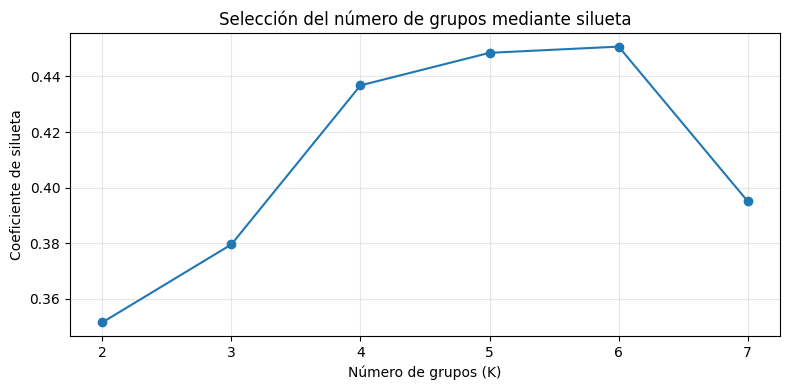

In [20]:

# ============================================================
# 8.4. ESTANDARIZACIÓN Y SELECCIÓN DEL NÚMERO DE GRUPOS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 8.4.1. Seleccionamos las variables que describen
# el comportamiento operativo de cada zona.
variables_cluster = [
    "total_viajes",
    "distancia_mediana",
    "tarifa_mediana",
    "propina_mediana",
    "proporcion_nocturna",
    "proporcion_fin_semana"
]

X_cluster = perfil_zonas_limpio[
    variables_cluster
].copy()

# 8.4.2. Aplicamos log1p al volumen de viajes.
# Esta transformación reduce la diferencia entre
# zonas con pocos y muchos viajes.
X_cluster["total_viajes"] = np.log1p(
    X_cluster["total_viajes"]
)

# 8.4.3. Estandarizamos las variables.
# Cada variable tendrá media cercana a 0
# y desviación estándar cercana a 1.
escalador = StandardScaler()

X_cluster_escalado = escalador.fit_transform(
    X_cluster
)

print("DIMENSIONES DE LA MATRIZ:")
print(X_cluster_escalado.shape)

# 8.4.4. Evaluamos distintos números de grupos.
# El coeficiente de silueta permite comparar
# la separación y cohesión de los clusters.
resultados_k = []

for k in range(2, 8):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = kmeans.fit_predict(
        X_cluster_escalado
    )

    silueta = silhouette_score(
        X_cluster_escalado,
        etiquetas
    )

    resultados_k.append({
        "k": k,
        "silueta": silueta,
        "inercia": kmeans.inertia_
    })

# 8.4.5. Organizamos los resultados.
evaluacion_k = pd.DataFrame(resultados_k)

print("\nEVALUACIÓN DE K-MEANS:")
display(evaluacion_k.round(4))

# 8.4.6. Identificamos el K con mayor silueta.
mejor_k = int(
    evaluacion_k.loc[
        evaluacion_k["silueta"].idxmax(),
        "k"
    ]
)

print("\nK CON MAYOR COEFICIENTE DE SILUETA:",
      mejor_k)

# 8.4.7. Visualizamos los resultados.
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    evaluacion_k["k"],
    evaluacion_k["silueta"],
    marker="o"
)

ax.set_title(
    "Selección del número de grupos mediante silueta"
)

ax.set_xlabel("Número de grupos (K)")
ax.set_ylabel("Coeficiente de silueta")
ax.set_xticks(range(2, 8))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [21]:

# ============================================================
# 8.5. ENTRENAMIENTO Y CARACTERIZACIÓN DE K-MEANS
# ============================================================

from sklearn.cluster import KMeans

# 8.5.1. Entrenamos K-Means con el mejor K encontrado
# en el apartado 8.4.
modelo_kmeans = KMeans(
    n_clusters=mejor_k,
    random_state=42,
    n_init=20
)

# 8.5.2. Asignamos cada zona al grupo correspondiente.
etiquetas_cluster = modelo_kmeans.fit_predict(
    X_cluster_escalado
)

# 8.5.3. Creamos una copia de los perfiles limpios
# para conservar los resultados de la segmentación.
zonas_clusterizadas = perfil_zonas_limpio.copy()

zonas_clusterizadas["cluster"] = etiquetas_cluster

# 8.5.4. Contamos cuántas zonas contiene cada grupo.
distribucion_clusters = (
    zonas_clusterizadas["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="cantidad_zonas")
)

print("CANTIDAD DE ZONAS POR GRUPO:")
display(distribucion_clusters)

# 8.5.5. Calculamos las características típicas
# de las zonas pertenecientes a cada grupo.
# Aquí usamos la mediana entre zonas de cada cluster.
perfil_clusters = (
    zonas_clusterizadas.groupby("cluster")
    [variables_cluster]
    .median()
    .round(2)
)

print("\nPERFIL OPERATIVO DE LOS GRUPOS:")
display(perfil_clusters)

# 8.5.6. Identificamos ejemplos de zonas por grupo.
print("\nEJEMPLOS DE ZONAS POR GRUPO:")

for grupo in sorted(zonas_clusterizadas["cluster"].unique()):

    zonas_grupo = zonas_clusterizadas[
        zonas_clusterizadas["cluster"] == grupo
    ]

    print(f"\nGRUPO {grupo} - {len(zonas_grupo)} zonas")

    display(
        zonas_grupo[
            ["PULocationID", "Borough", "Zone",
             "total_viajes", "distancia_mediana",
             "proporcion_nocturna"]
        ]
        .sort_values("total_viajes", ascending=False)
        .head(5)
    )


CANTIDAD DE ZONAS POR GRUPO:


,cluster,cantidad_zonas
0,0,43
1,1,37
2,2,3
3,3,8
4,4,4
5,5,5



PERFIL OPERATIVO DE LOS GRUPOS:


,total_viajes,distancia_mediana,tarifa_mediana,propina_mediana,proporcion_nocturna,proporcion_fin_semana
cluster,,,,,,
0,48279.0,1.60,12.10,2.62,0.14,0.24
1,913.0,3.82,21.90,0.00,0.18,0.23
2,89530.0,9.48,40.80,10.00,0.16,0.22
3,26790.5,1.82,13.07,2.73,0.37,0.41
4,675.0,11.52,58.75,0.00,0.22,0.23
5,912.0,3.86,22.55,0.00,0.57,0.42



EJEMPLOS DE ZONAS POR GRUPO:

GRUPO 0 - 43 zonas


...

,PULocationID,Borough,Zone,total_viajes,distancia_mediana,proporcion_nocturna
93,249,Manhattan,West Village,66227,1.61,0.392861
28,79,Manhattan,East Village,65935,1.69,0.446955
42,114,Manhattan,Greenwich Village South,40344,1.68,0.483690
57,148,Manhattan,Lower East Side,27964,2.10,0.591725
54,144,Manhattan,Little Italy/NoLiTa,25617,1.90,0.346176



GRUPO 4 - 4 zonas


,PULocationID,Borough,Zone,total_viajes,distancia_mediana,proporcion_nocturna
2,10,Queens,Baisley Park,999,14.10,0.181181
46,130,Queens,Jamaica,755,10.14,0.256954
75,215,Queens,South Jamaica,595,12.90,0.196639
35,93,Queens,Flushing Meadows-Corona Park,510,9.21,0.239216



GRUPO 5 - 5 zonas


,PULocationID,Borough,Zone,total_viajes,distancia_mediana,proporcion_nocturna
0,4,Manhattan,Alphabet City,3568,2.060,0.591648
94,255,Brooklyn,Williamsburg (North Side),1110,3.860,0.720721
95,256,Brooklyn,Williamsburg (South Side),912,3.610,0.573465
29,80,Brooklyn,East Williamsburg,676,4.405,0.556213
40,112,Brooklyn,Greenpoint,661,4.010,0.573374


In [22]:

# ============================================================
# 8.6. COMPARACIÓN DE SEGMENTACIONES K = 5 Y K = 6
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 8.6.1. Entrenamos una solución alternativa con 5 grupos.
modelo_k5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

etiquetas_k5 = modelo_k5.fit_predict(
    X_cluster_escalado
)

# 8.6.2. Conservamos las etiquetas de ambas soluciones
# para comparar qué zonas cambian de agrupación.
comparacion_clusters = perfil_zonas_limpio[
    ["PULocationID", "Borough", "Zone"]
].copy()

comparacion_clusters["cluster_k5"] = etiquetas_k5
comparacion_clusters["cluster_k6"] = etiquetas_cluster

# 8.6.3. Comparamos las siluetas y tamaños mínimos.
resumen_comparacion = pd.DataFrame({
    "K": [5, 6],
    "silueta": [
        silhouette_score(X_cluster_escalado, etiquetas_k5),
        silhouette_score(X_cluster_escalado, etiquetas_cluster)
    ],
    "grupo_mas_pequeno": [
        pd.Series(etiquetas_k5).value_counts().min(),
        pd.Series(etiquetas_cluster).value_counts().min()
    ]
})

print("COMPARACIÓN GENERAL:")
display(resumen_comparacion.round(4))

# 8.6.4. Tabla cruzada: muestra cómo se distribuyen
# los grupos de K=6 dentro de la solución K=5.
print("\nCORRESPONDENCIA ENTRE GRUPOS:")
display(
    pd.crosstab(
        comparacion_clusters["cluster_k5"],
        comparacion_clusters["cluster_k6"]
    )
)

# 8.6.5. Caracterizamos los grupos de la solución K=5.
perfil_k5 = perfil_zonas_limpio.copy()
perfil_k5["cluster_k5"] = etiquetas_k5

print("\nPERFIL OPERATIVO CON K=5:")
display(
    perfil_k5.groupby("cluster_k5")[variables_cluster]
    .median()
    .round(2)
)

print("\nEJEMPLOS DE ZONAS POR GRUPO CON K=5:")

for grupo in sorted(perfil_k5["cluster_k5"].unique()):

    zonas_grupo = perfil_k5[
        perfil_k5["cluster_k5"] == grupo
    ]

    print(f"\nGRUPO {grupo} - {len(zonas_grupo)} zonas")

    display(
        zonas_grupo[
            ["Borough", "Zone", "total_viajes",
             "distancia_mediana", "proporcion_nocturna"]
        ]
        .sort_values("total_viajes", ascending=False)
        .head(5)
    )


COMPARACIÓN GENERAL:


,K,silueta,grupo_mas_pequeno
0,5,0.4485,3
1,6,0.4507,3



CORRESPONDENCIA ENTRE GRUPOS:


cluster_k6,0,1,2,3,4,5
cluster_k5,,,,,,
0,0,36,0,0,0,0
1,43,1,0,1,0,0
2,0,0,3,0,0,0
3,0,0,0,7,0,5
4,0,0,0,0,4,0



PERFIL OPERATIVO CON K=5:


...

,Borough,Zone,total_viajes,distancia_mediana,proporcion_nocturna
47,Queens,JFK Airport,145240,17.41,0.219939
49,Queens,LaGuardia Airport,89530,9.48,0.155903
24,Queens,East Elmhurst,12285,9.33,0.145299



GRUPO 3 - 12 zonas


,Borough,Zone,total_viajes,distancia_mediana,proporcion_nocturna
93,Manhattan,West Village,66227,1.61,0.392861
28,Manhattan,East Village,65935,1.69,0.446955
42,Manhattan,Greenwich Village South,40344,1.68,0.483690
57,Manhattan,Lower East Side,27964,2.10,0.591725
54,Manhattan,Little Italy/NoLiTa,25617,1.90,0.346176



GRUPO 4 - 4 zonas


,Borough,Zone,total_viajes,distancia_mediana,proporcion_nocturna
2,Queens,Baisley Park,999,14.10,0.181181
46,Queens,Jamaica,755,10.14,0.256954
75,Queens,South Jamaica,595,12.90,0.196639
35,Queens,Flushing Meadows-Corona Park,510,9.21,0.239216


VARIANZA EXPLICADA POR PCA:
Componente 1: 38.00%
Componente 2: 30.56%
Total: 68.56%


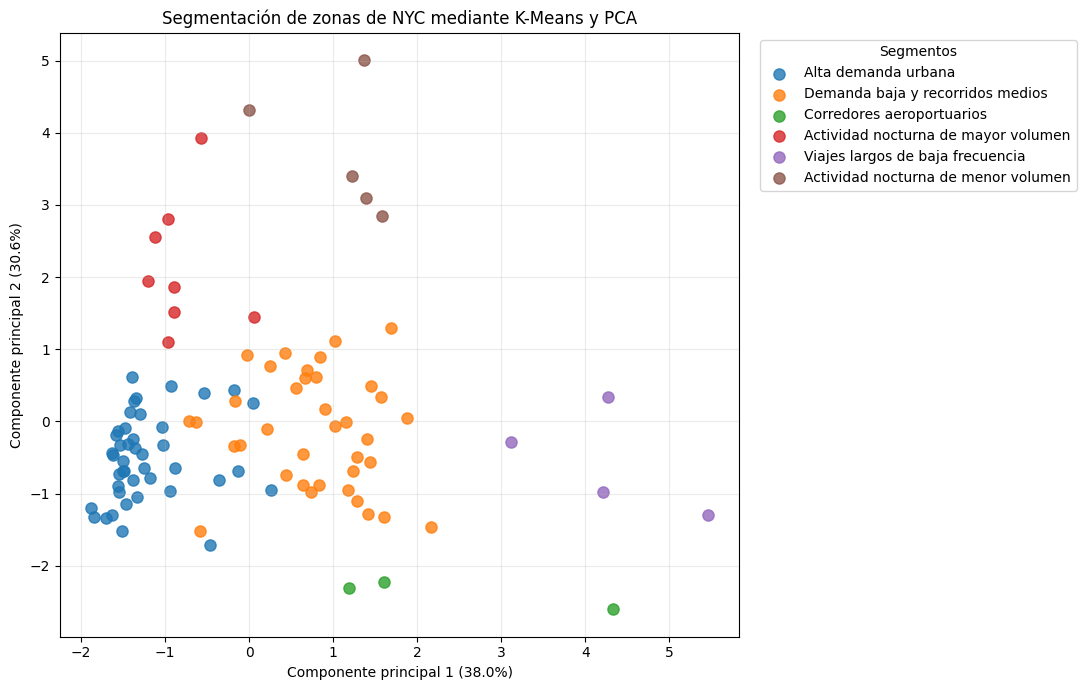


ZONAS REPRESENTADAS EN PCA:


,PULocationID,Borough,Zone,cluster,nombre_cluster,PCA_1,PCA_2
0,4,Manhattan,Alphabet City,5,Actividad nocturna de menor volumen,-0.000720,4.316145
1,7,Queens,Astoria,1,Demanda baja y recorridos medios,0.242823,0.775005
2,10,Queens,Baisley Park,4,Viajes largos de baja frecuencia,5.462671,-1.291837
3,12,Manhattan,Battery Park,1,Demanda baja y recorridos medios,0.739073,-0.974010
4,13,Manhattan,Battery Park City,0,Alta demanda urbana,-0.466300,-1.713875
5,17,Brooklyn,Bedford,1,Demanda baja y recorridos medios,1.148352,-0.012412
6,24,Manhattan,Bloomingdale,0,Alta demanda urbana,-0.876422,-0.645630
7,25,Brooklyn,Boerum Hill,1,Demanda baja y recorridos medios,0.848304,0.891902
8,33,Brooklyn,Brooklyn Heights,1,Demanda baja y recorridos medios,0.836218,-0.876864
9,35,Brooklyn,Brownsville,1,Demanda baja y recorridos medios,1.415789,-1.279729


In [23]:

# ============================================================
# 8.7. VISUALIZACIÓN DE LOS SEGMENTOS MEDIANTE PCA
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

# 8.7.1. Definimos los nombres descriptivos de los grupos.
nombres_clusters = {
    0: "Alta demanda urbana",
    1: "Demanda baja y recorridos medios",
    2: "Corredores aeroportuarios",
    3: "Actividad nocturna de mayor volumen",
    4: "Viajes largos de baja frecuencia",
    5: "Actividad nocturna de menor volumen"
}

# Incorporamos los nombres a la tabla de zonas.
zonas_clusterizadas["nombre_cluster"] = (
    zonas_clusterizadas["cluster"].map(nombres_clusters)
)

# 8.7.2. Aplicamos PCA a las seis variables estandarizadas.
# Reducimos la representación a dos componentes.
pca = PCA(n_components=2)

componentes = pca.fit_transform(
    X_cluster_escalado
)

# 8.7.3. Creamos una tabla para visualizar los resultados.
resultado_pca = zonas_clusterizadas[
    ["PULocationID", "Borough", "Zone",
     "cluster", "nombre_cluster"]
].copy()

resultado_pca["PCA_1"] = componentes[:, 0]
resultado_pca["PCA_2"] = componentes[:, 1]

# 8.7.4. Calculamos la varianza explicada.
varianza_explicada = (
    pca.explained_variance_ratio_ * 100
)

print("VARIANZA EXPLICADA POR PCA:")
print(f"Componente 1: {varianza_explicada[0]:.2f}%")
print(f"Componente 2: {varianza_explicada[1]:.2f}%")
print(f"Total: {varianza_explicada.sum():.2f}%")

# 8.7.5. Graficamos las zonas por grupo.
plt.figure(figsize=(11, 7))

for grupo in sorted(resultado_pca["cluster"].unique()):

    datos_grupo = resultado_pca[
        resultado_pca["cluster"] == grupo
    ]

    plt.scatter(
        datos_grupo["PCA_1"],
        datos_grupo["PCA_2"],
        label=nombres_clusters[grupo],
        alpha=0.8,
        s=65
    )

plt.title("Segmentación de zonas de NYC mediante K-Means y PCA")

plt.xlabel(
    f"Componente principal 1 ({varianza_explicada[0]:.1f}%)"
)

plt.ylabel(
    f"Componente principal 2 ({varianza_explicada[1]:.1f}%)"
)

plt.legend(
    title="Segmentos",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 8.7.6. Verificamos la tabla resultante.
print("\nZONAS REPRESENTADAS EN PCA:")
display(resultado_pca.head(10))


**Interpretación de resultados:** La segmentación mediante K-Means permitió identificar seis perfiles operativos entre las 100 zonas analizadas. La selección de K = 6 se fundamentó en el mayor coeficiente de silueta (0.4507) y en la diferenciación de perfiles de demanda nocturna con distintos volúmenes de viajes.

La visualización mediante PCA explicó el 68.56% de la variabilidad de las variables estandarizadas, permitiendo observar una separación apreciable entre varios segmentos, especialmente los corredores aeroportuarios, las zonas de viajes largos y los perfiles nocturnos. Se identificó cierta superposición entre zonas de alta demanda urbana y zonas de menor demanda, por lo que la visualización debe interpretarse como una aproximación bidimensional y no como una validación completa de la separación de los grupos.

In [24]:

# ============================================================
# 8.8. EXPORTACIÓN DE LOS RESULTADOS DE SEGMENTACIÓN
# ============================================================

import os
import pandas as pd

# 8.8.1. Preparamos el archivo final.
# Conservamos los indicadores originales, las etiquetas
# de K-Means y las coordenadas calculadas mediante PCA.
segmentos_exportar = zonas_clusterizadas.merge(
    resultado_pca[
        ["PULocationID", "PCA_1", "PCA_2"]
    ],
    on="PULocationID",
    how="left",
    validate="one_to_one"
)

# 8.8.2. Definimos el orden de las columnas.
columnas_exportacion = [
    "PULocationID",
    "Borough",
    "Zone",
    "total_viajes",
    "distancia_mediana",
    "tarifa_mediana",
    "propina_mediana",
    "proporcion_nocturna",
    "proporcion_fin_semana",
    "cluster",
    "nombre_cluster",
    "PCA_1",
    "PCA_2"
]

segmentos_exportar = segmentos_exportar[
    columnas_exportacion
].sort_values("PULocationID")

# 8.8.3. Creamos la carpeta de datos de la aplicación.
os.makedirs("app/data", exist_ok=True)

# 8.8.4. Guardamos los resultados en formato CSV.
ruta_segmentos = "app/data/segmentos_zonas.csv"

segmentos_exportar.to_csv(
    ruta_segmentos,
    index=False,
    encoding="utf-8"
)

# 8.8.5. Validamos el archivo exportado.
segmentos_verificacion = pd.read_csv(ruta_segmentos)

print("ARCHIVO GENERADO:", ruta_segmentos)
print("ZONAS EXPORTADAS:", len(segmentos_verificacion))

print("\nVALORES FALTANTES:")
print(segmentos_verificacion.isna().sum())

print("\nDISTRIBUCIÓN DE LOS SEGMENTOS:")
display(
    segmentos_verificacion.groupby(
        ["cluster", "nombre_cluster"]
    ).size().reset_index(name="cantidad_zonas")
)

print("\nVISTA PREVIA DEL ARCHIVO:")
display(segmentos_verificacion.head())


ARCHIVO GENERADO: app/data/segmentos_zonas.csv
ZONAS EXPORTADAS: 100

VALORES FALTANTES:
PULocationID             0
Borough                  0
Zone                     0
total_viajes             0
distancia_mediana        0
tarifa_mediana           0
propina_mediana          0
proporcion_nocturna      0
proporcion_fin_semana    0
cluster                  0
nombre_cluster           0
PCA_1                    0
PCA_2                    0
dtype: int64

DISTRIBUCIÓN DE LOS SEGMENTOS:


,cluster,nombre_cluster,cantidad_zonas
0,0,Alta demanda urbana,43
1,1,Demanda baja y recorridos medios,37
2,2,Corredores aeroportuarios,3
3,3,Actividad nocturna de mayor volumen,8
4,4,Viajes largos de baja frecuencia,4
5,5,Actividad nocturna de menor volumen,5



VISTA PREVIA DEL ARCHIVO:


,PULocationID,Borough,Zone,total_viajes,distancia_mediana,tarifa_mediana,propina_mediana,proporcion_nocturna,proporcion_fin_semana,cluster,nombre_cluster,PCA_1,PCA_2
0,4,Manhattan,Alphabet City,3568,2.06,14.665,2.02,0.591648,0.549327,5,Actividad nocturna de menor volumen,-0.000720,4.316145
1,7,Queens,Astoria,1811,2.90,17.700,0.00,0.205411,0.315295,1,Demanda baja y recorridos medios,0.242823,0.775005
2,10,Queens,Baisley Park,999,14.10,70.000,0.00,0.181181,0.229229,4,Viajes largos de baja frecuencia,5.462671,-1.291837
3,12,Manhattan,Battery Park,875,4.60,24.000,2.66,0.024000,0.262857,1,Demanda baja y recorridos medios,0.739073,-0.974010
4,13,Manhattan,Battery Park City,15877,3.50,19.230,3.57,0.048057,0.174655,0,Alta demanda urbana,-0.466300,-1.713875


**Conclusión del apartado 8. Segmentación de zonas**

Se analizaron 100 zonas de Nueva York con al menos 500 viajes durante enero de 2024, excluyendo los identificadores geográficos especiales y aplicando un tratamiento de valores extremos para construir indicadores representativos.

Mediante K-Means se identificaron seis segmentos operativos, seleccionados a partir del coeficiente de silueta (0.4507) y de su interpretación. La visualización PCA explicó el 68.56% de la variabilidad de las características utilizadas.

Los segmentos permiten distinguir zonas de alta demanda urbana, zonas de menor demanda, corredores aeroportuarios, zonas con recorridos largos y dos perfiles diferenciados de actividad nocturna.

Los resultados se exportaron a `app/data/segmentos_zonas.csv`, con 100 registros completos, para su integración en la aplicación Streamlit.

**9. Decisiones de despacho y costos operativos.**

**Objetivo general:** transformar los pronósticos probabilísticos de demanda en recomendaciones de asignación de taxis por zona y hora, considerando los costos asociados con la demanda no atendida y la capacidad ociosa

**9.1. Definición del modelo de costos de despacho**

Supuesto del modelo: para simplificar la decisión, se considera que cada taxi asignado puede atender un viaje por hora.

In [25]:

# ============================================================
# 9.1. DEFINICIÓN DEL MODELO DE COSTOS DE DESPACHO
# ============================================================

import numpy as np
import pandas as pd

# 9.1.1. Definimos los costos ilustrativos.
# No representan costos reales de operación de NYC.
#
# Costo por pasajero que no encuentra taxi.
costo_pasajero_perdido = 40.0

# Costo de mantener un taxi una hora sin pasajero.
costo_taxi_ocioso = 10.0

# 9.1.2. Calculamos el cuantil óptimo teórico.
# Esta fórmula equilibra el costo de quedarse corto
# frente al costo de asignar taxis de más.
cuantil_optimo = (
    costo_pasajero_perdido /
    (costo_pasajero_perdido + costo_taxi_ocioso)
)

# 9.1.3. Seleccionamos el cuantil disponible más cercano.
# El modelo XGBoost produce p10, p20, ..., p90.
cuantiles_disponibles = np.arange(0.1, 1.0, 0.1)

cuantil_seleccionado = min(
    cuantiles_disponibles,
    key=lambda q: abs(q - cuantil_optimo)
)

nombre_cuantil = (
    f"p{int(round(cuantil_seleccionado * 100))}"
)

# 9.1.4. Definimos la función de costo.
# Los valores pueden ser números individuales o arreglos.
def calcular_costo_despacho(
    demanda_real,
    taxis_asignados,
    costo_perdido,
    costo_ocioso
):
    # Pasajeros que no pudieron ser atendidos.
    pasajeros_perdidos = np.maximum(
        demanda_real - taxis_asignados,
        0
    )

    # Taxis asignados que quedaron sin pasajero.
    taxis_sin_pasajero = np.maximum(
        taxis_asignados - demanda_real,
        0
    )

    # Costo económico total de la decisión.
    costo_total = (
        pasajeros_perdidos * costo_perdido
        + taxis_sin_pasajero * costo_ocioso
    )

    return costo_total

# 9.1.5. Verificamos la función con un ejemplo.
demanda_ejemplo = 20
taxis_asignados_ejemplo = 17

costo_ejemplo = calcular_costo_despacho(
    demanda_real=demanda_ejemplo,
    taxis_asignados=taxis_asignados_ejemplo,
    costo_perdido=costo_pasajero_perdido,
    costo_ocioso=costo_taxi_ocioso
)

# 9.1.6. Mostramos los resultados.
print("MODELO DE COSTOS DE DESPACHO")
print("-" * 45)

print("Costo por pasajero perdido: $",
      costo_pasajero_perdido)

print("Costo por taxi ocioso: $",
      costo_taxi_ocioso)

print("\nCuantil óptimo teórico:",
      round(cuantil_optimo, 4))

print("Cuantil seleccionado:",
      nombre_cuantil)

print("\nVALIDACIÓN CON UN EJEMPLO")
print("-" * 45)

print("Demanda real:", demanda_ejemplo)
print("Taxis asignados:", taxis_asignados_ejemplo)
print("Costo total: $", costo_ejemplo)


MODELO DE COSTOS DE DESPACHO
---------------------------------------------
Costo por pasajero perdido: $ 40.0
Costo por taxi ocioso: $ 10.0

Cuantil óptimo teórico: 0.8
Cuantil seleccionado: p80

VALIDACIÓN CON UN EJEMPLO
---------------------------------------------
Demanda real: 20
Taxis asignados: 17
Costo total: $ 120.0


**9.2. Recomendación de taxis por zona y hora**: Transformar los pronósticos de demanda en cantidades enteras de taxis recomendados por zona y hora, utilizando el cuantil seleccionado según los costos operativos.

Se calcularán tres alternativas de asignación: el cuantil económicamente seleccionado (p80), el pronóstico central (p50) y la demanda observada en la misma hora de la semana anterior.

**Criterio:** las cantidades recomendadas se redondearán hacia arriba para evitar asignaciones fraccionarias de taxis y se limitarán a valores no negativos.

In [26]:

# ============================================================
# 9.2. RECOMENDACIÓN DE TAXIS POR ZONA Y HORA
# ============================================================

import numpy as np
import pandas as pd

# 9.2.1. Recuperamos las predicciones del período de prueba.
# Esta tabla fue creada durante la evaluación de XGBoost.
plan_despacho = resultados_prueba.copy()

# 9.2.2. Comprobamos que estén disponibles las columnas
# necesarias para generar las tres alternativas.
columnas_necesarias = [
    "PULocationID",
    "hora",
    "real",
    "hace_una_semana",
    "p50",
    nombre_cuantil
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in plan_despacho.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas necesarias: {faltantes}"
    )

# 9.2.3. Convertimos cada pronóstico en una cantidad
# entera de taxis, redondeando hacia arriba.
#
# Política óptima aproximada según los costos.
plan_despacho["taxis_recomendados"] = (
    np.ceil(
        plan_despacho[nombre_cuantil].clip(lower=0)
    ).astype(int)
)

# Política basada en el pronóstico central.
plan_despacho["taxis_p50"] = (
    np.ceil(
        plan_despacho["p50"].clip(lower=0)
    ).astype(int)
)

# Política basada en la misma hora de la semana anterior.
plan_despacho["taxis_semana_anterior"] = (
    np.ceil(
        plan_despacho["hace_una_semana"].clip(lower=0)
    ).astype(int)
)

# 9.2.4. Incorporamos el cuantil y los costos utilizados.
# Estos datos permitirán interpretar la recomendación.
plan_despacho["cuantil_utilizado"] = nombre_cuantil

plan_despacho["costo_pasajero_perdido"] = (
    costo_pasajero_perdido
)

plan_despacho["costo_taxi_ocioso"] = (
    costo_taxi_ocioso
)

# 9.2.5. Validamos la integridad de las recomendaciones.
columnas_taxis = [
    "taxis_recomendados",
    "taxis_p50",
    "taxis_semana_anterior"
]

recomendaciones_validas = (
    plan_despacho[columnas_taxis].notna().all().all()
    and (plan_despacho[columnas_taxis] >= 0).all().all()
)

print("VALIDACIÓN DEL PLAN DE DESPACHO")
print("-" * 45)

print("Cuantil utilizado:", nombre_cuantil)
print("Registros generados:", len(plan_despacho))
print("Zonas incluidas:",
      plan_despacho["PULocationID"].nunique())

print("¿Recomendaciones válidas?:",
      recomendaciones_validas)

# 9.2.6. Mostramos las primeras recomendaciones.
print("\nEJEMPLO DE RECOMENDACIONES:")

display(
    plan_despacho[
        [
            "PULocationID",
            "hora",
            "real",
            "p50",
            nombre_cuantil,
            "taxis_recomendados",
            "taxis_p50",
            "taxis_semana_anterior"
        ]
    ].head(10)
)

# 9.2.7. Resumen de las tres políticas.
print("\nRESUMEN DE TAXIS ASIGNADOS POR HORA Y ZONA:")

display(
    plan_despacho[columnas_taxis]
    .describe()
    .round(2)
)


VALIDACIÓN DEL PLAN DE DESPACHO
---------------------------------------------
Cuantil utilizado: p80
Registros generados: 9912
Zonas incluidas: 59
¿Recomendaciones válidas?: True

EJEMPLO DE RECOMENDACIONES:


,PULocationID,hora,real,p50,p80,taxis_recomendados,taxis_p50,taxis_semana_anterior
576,4,2024-01-25 00:00:00,4.0,1.951946,4.885394,5,2,2
577,4,2024-01-25 01:00:00,2.0,0.869062,3.118219,4,1,1
578,4,2024-01-25 02:00:00,0.0,0.338535,2.818310,3,1,0
579,4,2024-01-25 03:00:00,0.0,0.338535,2.724770,3,1,0
580,4,2024-01-25 04:00:00,0.0,0.338535,2.724770,3,1,0
581,4,2024-01-25 05:00:00,1.0,0.751233,3.175480,4,1,0
582,4,2024-01-25 06:00:00,3.0,2.461187,4.746000,5,3,5
583,4,2024-01-25 07:00:00,4.0,5.256443,9.442307,10,6,5
584,4,2024-01-25 08:00:00,7.0,5.524066,9.744751,10,6,8
585,4,2024-01-25 09:00:00,11.0,6.034538,11.596830,12,7,6



RESUMEN DE TAXIS ASIGNADOS POR HORA Y ZONA:


,taxis_recomendados,taxis_p50,taxis_semana_anterior
count,9912.00,9912.00,9912.00
mean,83.56,67.71,68.07
std,91.82,80.90,86.50
min,2.00,0.00,0.00
25%,15.00,9.00,8.00
50%,47.00,33.00,31.00
75%,126.00,103.00,100.00
max,635.00,504.00,726.00



**9.3. Evaluación económica de las estrategias de despacho**

Evaluar y comparar el desempeño económico de tres políticas de asignación de taxis: cuantil seleccionado según costos (p80), pronóstico central (p50) y demanda de la misma hora de la semana anterior.

Para cada estrategia se calcularán los pasajeros no atendidos, los taxis ociosos y el costo total durante el período de prueba.

**Criterio de evaluación:** la estrategia más conveniente será aquella que produzca el menor costo total bajo los supuestos definidos. Los resultados representan costos simulados, no costos reales de operación.

COMPARACIÓN ECONÓMICA DE ESTRATEGIAS:


,estrategia,taxis_asignados,pasajeros_no_atendidos,taxis_ociosos,costo_total,costo_promedio
0,Cuantil p80,828235,19929,155763,2354790.0,237.57
1,Semana anterior,674661,67163,49423,3180750.0,320.90
2,Pronóstico p50,671118,69596,48313,3266970.0,329.60



ESTRATEGIA CON MENOR COSTO:
Cuantil p80
Costo total simulado: $ 2354790.0

AHORRO DE P80 FRENTE A SEMANA ANTERIOR:
25.97%


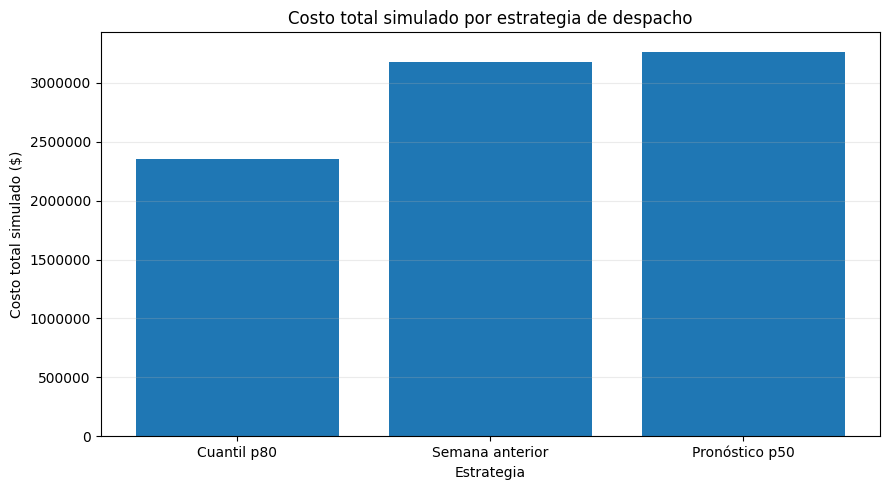

In [27]:

# ============================================================
# 9.3. EVALUACIÓN ECONÓMICA DE ESTRATEGIAS DE DESPACHO
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 9.3.1. Definimos las tres estrategias que compararemos.
estrategias = {
    "Cuantil p80": "taxis_recomendados",
    "Pronóstico p50": "taxis_p50",
    "Semana anterior": "taxis_semana_anterior"
}

# 9.3.2. Calculamos los resultados de cada estrategia.
# Usamos la demanda real del período de prueba.
resultados_estrategias = []

for nombre, columna in estrategias.items():

    # Taxis asignados según la estrategia.
    taxis = plan_despacho[columna]

    # Pasajeros que no podrían ser atendidos.
    pasajeros_perdidos = np.maximum(
        plan_despacho["real"] - taxis,
        0
    )

    # Taxis que quedarían sin pasajero.
    taxis_ociosos = np.maximum(
        taxis - plan_despacho["real"],
        0
    )

    # Costo total utilizando la función del apartado 9.1.
    costos = calcular_costo_despacho(
        demanda_real=plan_despacho["real"],
        taxis_asignados=taxis,
        costo_perdido=costo_pasajero_perdido,
        costo_ocioso=costo_taxi_ocioso
    )

    # Guardamos los costos por registro para poder
    # analizarlos posteriormente por día y zona.
    plan_despacho[f"costo_{columna}"] = costos

    resultados_estrategias.append({
        "estrategia": nombre,
        "taxis_asignados": int(taxis.sum()),
        "pasajeros_no_atendidos": int(pasajeros_perdidos.sum()),
        "taxis_ociosos": int(taxis_ociosos.sum()),
        "costo_total": float(costos.sum()),
        "costo_promedio": float(costos.mean())
    })

# 9.3.3. Construimos una tabla comparativa.
comparacion_costos = pd.DataFrame(
    resultados_estrategias
).sort_values("costo_total").reset_index(drop=True)

print("COMPARACIÓN ECONÓMICA DE ESTRATEGIAS:")
display(comparacion_costos.round(2))

# 9.3.4. Identificamos la estrategia de menor costo.
mejor_estrategia = comparacion_costos.iloc[0]

print("\nESTRATEGIA CON MENOR COSTO:")
print(mejor_estrategia["estrategia"])

print("Costo total simulado: $",
      round(mejor_estrategia["costo_total"], 2))

# 9.3.5. Calculamos el ahorro o sobrecosto de p80
# frente a la estrategia de la semana anterior.
costo_p80 = comparacion_costos.loc[
    comparacion_costos["estrategia"] == "Cuantil p80",
    "costo_total"
].iloc[0]

costo_semanal = comparacion_costos.loc[
    comparacion_costos["estrategia"] == "Semana anterior",
    "costo_total"
].iloc[0]

ahorro_porcentual = (
    (costo_semanal - costo_p80) / costo_semanal * 100
    if costo_semanal > 0 else np.nan
)

print("\nAHORRO DE P80 FRENTE A SEMANA ANTERIOR:")
print(f"{ahorro_porcentual:.2f}%")

# 9.3.6. Visualizamos los costos totales.
plt.figure(figsize=(9, 5))

plt.bar(
    comparacion_costos["estrategia"],
    comparacion_costos["costo_total"]
)

plt.title("Costo total simulado por estrategia de despacho")
plt.xlabel("Estrategia")
plt.ylabel("Costo total simulado ($)")

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


**Interpretación de resultados**

La evaluación económica de las estrategias de despacho, realizada sobre 9,912 observaciones del período de prueba, mostró que la política basada en el cuantil p80 obtuvo el menor costo total simulado ($2,354,790), frente a la asignación según la semana anterior ($3,180,750) y el pronóstico central p50 ($3,266,970).

La política p80 permitió reducir el costo simulado en un 25.97% respecto a la estrategia semanal y disminuir aproximadamente un 70.3% la demanda no atendida. Aunque incrementó la cantidad de taxis-hora ociosos, este efecto fue compensado por la reducción del costo asociado con pasajeros no atendidos.

Los resultados evidencian que un modelo puede aportar valor para la toma de decisiones operativas aun cuando no supere a una referencia sencilla en precisión puntual.

**Limitación:** los beneficios estimados dependen de los costos ilustrativos, los supuestos de capacidad y el período histórico analizado; no representan ahorros reales garantizados.

COSTOS SIMULADOS POR DÍA:


,fecha,p80,p50,semana_anterior,ahorro_p80_pct
0,2024-01-25,273510.0,394180.0,407290.0,32.85
1,2024-01-26,283120.0,499910.0,586760.0,51.75
2,2024-01-27,436760.0,643870.0,568200.0,23.13
3,2024-01-28,413480.0,538460.0,595420.0,30.56
4,2024-01-29,389170.0,493940.0,296870.0,-31.09
5,2024-01-30,292600.0,415080.0,402480.0,27.30
6,2024-01-31,266150.0,281530.0,323730.0,17.79


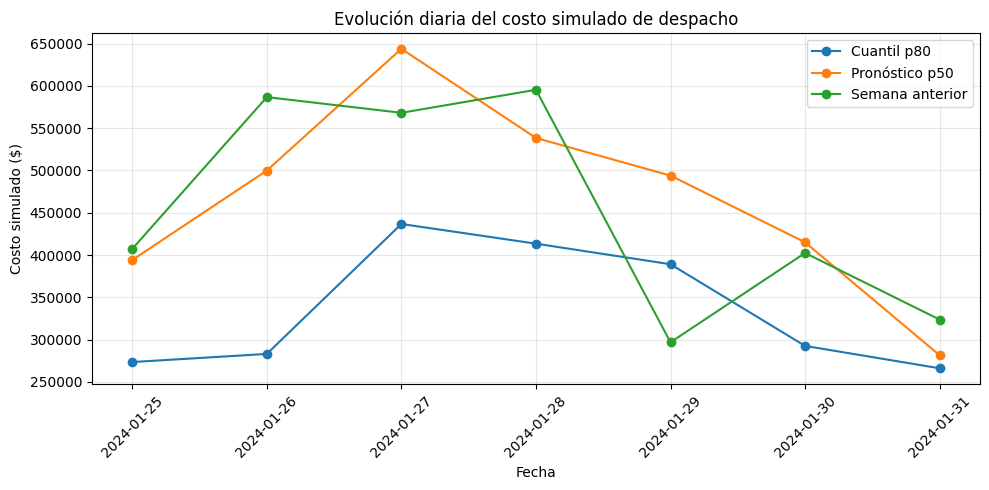


10 ZONAS CON MAYOR AHORRO ABSOLUTO:


/tmp/ipykernel_2943/3270669840.py:76: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plan_despacho.groupby("PULocationID")[


,PULocationID,Borough,Zone,ahorro_absoluto,ahorro_pct
53,246,Manhattan,West Chelsea/Hudson Yards,48310.0,32.37
9,68,Manhattan,East Chelsea,43950.0,45.48
39,186,Manhattan,Penn Station/Madison Sq West,42240.0,29.96
33,161,Manhattan,Midtown Center,36410.0,31.90
24,138,Queens,LaGuardia Airport,28340.0,26.34
7,48,Manhattan,Clinton East,27750.0,34.28
44,230,Manhattan,Times Sq/Theatre District,27090.0,29.16
35,163,Manhattan,Midtown North,26820.0,30.99
17,100,Manhattan,Garment District,25920.0,40.79
22,132,Queens,JFK Airport,24020.0,22.03



10 ZONAS CON MENOR AHORRO O MAYOR SOBRECOSTO:


,PULocationID,Borough,Zone,ahorro_absoluto,ahorro_pct
25,140,Manhattan,Lenox Hill East,-2260.0,-4.71
49,236,Manhattan,Upper East Side North,580.0,0.75
46,232,Manhattan,Two Bridges/Seward Park,1590.0,13.74
4,42,Manhattan,Central Harlem North,2650.0,25.31
0,4,Manhattan,Alphabet City,2700.0,15.80
15,88,Manhattan,Financial District South,3120.0,21.65
40,209,Manhattan,Seaport,3170.0,23.21
6,45,Manhattan,Chinatown,3340.0,28.77
3,41,Manhattan,Central Harlem,3370.0,22.30
42,224,Manhattan,Stuy Town/Peter Cooper Village,3970.0,31.19



RESUMEN POR ZONAS:
Zonas con ahorro: 58
Zonas con sobrecosto: 1
Zonas sin diferencia: 0
Total de zonas evaluadas: 59


In [28]:

# ============================================================
# 9.4. EVALUACIÓN ECONÓMICA POR DÍA Y ZONA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 9.4.1. Identificamos la fecha de cada pronóstico.
plan_despacho["fecha"] = pd.to_datetime(
    plan_despacho["hora"]
).dt.date

# 9.4.2. Recuperamos las columnas de costos calculadas
# en el apartado 9.3 para las tres estrategias.
columna_p80 = "costo_taxis_recomendados"
columna_p50 = "costo_taxis_p50"
columna_semanal = "costo_taxis_semana_anterior"

# 9.4.3. Agrupamos los costos por fecha.
costos_diarios = (
    plan_despacho.groupby("fecha")[
        [columna_p80, columna_p50, columna_semanal]
    ]
    .sum()
    .reset_index()
)

# Asignamos nombres más sencillos para el análisis.
costos_diarios = costos_diarios.rename(columns={
    columna_p80: "p80",
    columna_p50: "p50",
    columna_semanal: "semana_anterior"
})

# 9.4.4. Calculamos el ahorro porcentual diario de p80
# respecto a la estrategia de la semana anterior.
costos_diarios["ahorro_p80_pct"] = np.where(
    costos_diarios["semana_anterior"] > 0,
    (
        costos_diarios["semana_anterior"]
        - costos_diarios["p80"]
    ) / costos_diarios["semana_anterior"] * 100,
    np.nan
)

print("COSTOS SIMULADOS POR DÍA:")
display(costos_diarios.round(2))

# 9.4.5. Graficamos la evolución de los costos diarios.
plt.figure(figsize=(10, 5))

for estrategia, etiqueta in [
    ("p80", "Cuantil p80"),
    ("p50", "Pronóstico p50"),
    ("semana_anterior", "Semana anterior")
]:
    plt.plot(
        costos_diarios["fecha"],
        costos_diarios[estrategia],
        marker="o",
        label=etiqueta
    )

plt.title("Evolución diaria del costo simulado de despacho")
plt.xlabel("Fecha")
plt.ylabel("Costo simulado ($)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 9.4.6. Agrupamos los costos por zona de origen.
costos_zona = (
    plan_despacho.groupby("PULocationID")[
        [columna_p80, columna_semanal]
    ]
    .sum()
    .reset_index()
)

# 9.4.7. Calculamos el ahorro absoluto y porcentual.
# Un valor negativo significa que p80 generó sobrecosto.
costos_zona["ahorro_absoluto"] = (
    costos_zona[columna_semanal]
    - costos_zona[columna_p80]
)

costos_zona["ahorro_pct"] = np.where(
    costos_zona[columna_semanal] > 0,
    costos_zona["ahorro_absoluto"]
    / costos_zona[columna_semanal] * 100,
    np.nan
)

# 9.4.8. Incorporamos los nombres y distritos.
costos_zona = costos_zona.merge(
    zonas[["LocationID", "Borough", "Zone"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left",
    validate="many_to_one"
).drop(columns="LocationID")

# 9.4.9. Identificamos las 10 zonas con mayores ahorros.
print("\n10 ZONAS CON MAYOR AHORRO ABSOLUTO:")

display(
    costos_zona.sort_values(
        "ahorro_absoluto", ascending=False
    )[
        ["PULocationID", "Borough", "Zone",
         "ahorro_absoluto", "ahorro_pct"]
    ].head(10).round(2)
)

# 9.4.10. Identificamos las 10 zonas con menores ahorros
# o mayores sobrecostos.
print("\n10 ZONAS CON MENOR AHORRO O MAYOR SOBRECOSTO:")

display(
    costos_zona.sort_values(
        "ahorro_absoluto", ascending=True
    )[
        ["PULocationID", "Borough", "Zone",
         "ahorro_absoluto", "ahorro_pct"]
    ].head(10).round(2)
)

# 9.4.11. Resumimos el resultado por zona.
zonas_con_ahorro = (
    costos_zona["ahorro_absoluto"] > 0
).sum()

zonas_con_sobrecosto = (
    costos_zona["ahorro_absoluto"] < 0
).sum()

zonas_sin_cambio = (
    costos_zona["ahorro_absoluto"] == 0
).sum()

print("\nRESUMEN POR ZONAS:")
print("Zonas con ahorro:", zonas_con_ahorro)
print("Zonas con sobrecosto:", zonas_con_sobrecosto)
print("Zonas sin diferencia:", zonas_sin_cambio)

# Comprobamos que se hayan evaluado las 59 zonas.
print("Total de zonas evaluadas:", len(costos_zona))


**9.5. Generación y exportación del plan de despacho**
Generar un plan de asignación de taxis para el 1 de febrero de 2024, utilizando los pronósticos probabilísticos del modelo XGBoost y el cuantil seleccionado mediante el modelo de costos.

El plan incluirá las recomendaciones horarias por zona, los cuantiles de demanda y las alternativas de asignación basadas en p50 y en la misma hora de la semana anterior.

**Consideración metodológica:** las recomendaciones corresponden a un ejercicio de pronóstico futuro respecto al período de entrenamiento y prueba. No se utilizará demanda real del 1 de febrero para generar las decisiones de despacho.

In [32]:

# ============================================================
# 9.5. CORRECCIÓN DE ZONA SIN NOMBRE
# ============================================================

# Conservamos la zona 264 y la identificamos
# explícitamente como una zona desconocida.
plan_futuro["Zone"] = plan_futuro["Zone"].fillna(
    "Unknown Zone"
)

# Verificamos que no existan nombres faltantes.
print("VALORES FALTANTES DESPUÉS DE LA CORRECCIÓN:")

print(
    plan_futuro[["Borough", "Zone"]]
    .isna()
    .sum()
)

# Volvemos a calcular la validación completa.
plan_valido = (
    len(plan_futuro) == 1416
    and plan_futuro["PULocationID"].nunique() == 59
    and horas_por_zona.eq(24).all()
    and fechas_validas
    and valores_validos
    and plan_futuro[["Borough", "Zone"]]
        .notna().all().all()
)

print("\n¿PLAN COMPLETO?:", plan_valido)

# Exportamos el archivo si las validaciones se cumplen.
if plan_valido:
    os.makedirs("app/data", exist_ok=True)

    ruta_plan = "app/data/plan_despacho_2024-02-01.csv"

    plan_futuro.to_csv(
        ruta_plan,
        index=False,
        encoding="utf-8"
    )

    print("\nARCHIVO GENERADO:", ruta_plan)

    print("\nPRIMERAS RECOMENDACIONES:")

    display(
        plan_futuro[
            [
                "PULocationID",
                "Zone",
                "hora",
                "p50",
                "p80",
                "taxis_recomendados",
                "taxis_p50",
                "taxis_semana_anterior"
            ]
        ].head(10)
    )
else:
    print("El plan todavía requiere revisión.")


VALORES FALTANTES DESPUÉS DE LA CORRECCIÓN:
Borough    0
Zone       0
dtype: int64

¿PLAN COMPLETO?: True

ARCHIVO GENERADO: app/data/plan_despacho_2024-02-01.csv

PRIMERAS RECOMENDACIONES:


,PULocationID,Zone,hora,p50,p80,taxis_recomendados,taxis_p50,taxis_semana_anterior
0,4,Alphabet City,2024-02-01 00:00:00,1.206703,3.797919,4,2,4
1,4,Alphabet City,2024-02-01 01:00:00,1.220435,3.645653,4,2,2
2,4,Alphabet City,2024-02-01 02:00:00,0.338535,2.818310,3,1,0
3,4,Alphabet City,2024-02-01 03:00:00,0.338535,2.724770,3,1,0
4,4,Alphabet City,2024-02-01 04:00:00,0.338535,2.724770,3,1,0
5,4,Alphabet City,2024-02-01 05:00:00,0.347399,2.806691,3,1,1
6,4,Alphabet City,2024-02-01 06:00:00,1.454849,3.863153,4,2,3
7,4,Alphabet City,2024-02-01 07:00:00,4.220601,7.819384,8,5,4
8,4,Alphabet City,2024-02-01 08:00:00,9.118735,16.983353,17,10,7
9,4,Alphabet City,2024-02-01 09:00:00,8.499269,12.225341,13,9,11


**Interpretación y conclusión del apartado 9.5**

Se generó y validó satisfactoriamente el plan de despacho correspondiente al 1 de febrero de 2024, compuesto por 1,416 recomendaciones horarias distribuidas en 59 zonas de Nueva York.

El plan integra los nueve cuantiles pronosticados por XGBoost y compara tres alternativas de asignación: la política basada en el cuantil p80, la mediana pronosticada (p50) y la demanda observada en la misma hora de la semana anterior.

Como ejemplo, para Alphabet City a las 8:00 a. m., la política p80 recomienda 17 taxis, frente a 10 con p50 y 7 con la referencia histórica. Esta diferencia refleja la incorporación de costos asimétricos en la toma de decisiones.

Durante la validación se identificó que la zona 264 carecía de nombre geográfico. Se conservó su identificador y se clasificó como *Unknown Zone* para mantener la integridad de los pronósticos. Esta zona deberá distinguirse de las zonas geográficamente identificadas en las recomendaciones operativas.

Finalmente, el plan se exportó en formato CSV, quedando disponible como insumo para la aplicación Streamlit. Los resultados representan recomendaciones simuladas bajo los supuestos del modelo y no asignaciones reales de vehículos.

**10. Ficha del modelo (Model Card)**

**10.1. Propósito y alcance del sistema**

**Nombre del sistema:** Taxis NYC — Pronóstico probabilístico de demanda y apoyo a decisiones de despacho.

**Objetivo:** desarrollar una herramienta de apoyo a la toma de decisiones que permita anticipar la demanda horaria de taxis por zona en Nueva York, identificar patrones operativos mediante segmentación y recomendar niveles de despacho considerando costos asimétricos.

**Componentes del sistema:**

1. **Pronóstico probabilístico:** modelo XGBoost que estima nueve cuantiles de demanda horaria (p10 a p90) por zona.
2. **Segmentación de zonas:** modelo KMeans que agrupa zonas con características operativas similares.
3. **Recomendación de despacho:** modelo de costos que selecciona un cuantil de demanda según el costo relativo de pasajeros no atendidos y taxis ociosos.
4. **Aplicación de consulta:** interfaz prevista en Streamlit, respaldada por una API desarrollada con FastAPI.

**Usuarios previstos:** analistas de operaciones, responsables de planificación de flota y personas encargadas de evaluar escenarios de demanda y asignación de taxis.

**Alcance temporal:** datos históricos de enero de 2024, evaluación del 25 al 31 de enero y generación de un plan de pronóstico para el 1 de febrero de 2024.

**Alcance geográfico:** 59 zonas incluidas en el modelo de pronóstico. Los registros sin identificación geográfica válida deberán distinguirse de las recomendaciones que requieren una ubicación operativa conocida.

**Uso previsto:** análisis exploratorio, planificación operativa y comparación simulada de políticas de despacho.

**Uso no previsto:** asignación automática de vehículos reales, garantía de disponibilidad de taxis o sustitución de decisiones operativas sin supervisión humana.

**10.2. Evaluación del desempeño**

**Modelo de pronóstico:** XGBoost con objetivo de regresión cuantílica, utilizando los cuantiles p10, p20, p30, p40, p50, p60, p70, p80 y p90.

**Evaluación temporal:** entrenamiento hasta el 24 de enero de 2024 y prueba del 25 al 31 de enero de 2024.

**Resultados principales:**

- MAE del pronóstico central p50: **11.88 viajes**.
- MAE de la referencia de la semana anterior: **11.76 viajes**.
- RMSE del pronóstico central: **22.82 viajes**.
- RMSE de la referencia histórica: **21.71 viajes**.
- Cobertura empírica del intervalo p10–p90: **89.86%**, frente a una cobertura nominal del 80%.
- Amplitud media del intervalo p10–p90: **48.88 viajes**.

El pronóstico central de XGBoost no mejoró la precisión puntual de la referencia histórica. Asimismo, la cobertura superior a la nominal indica que los intervalos fueron conservadores en el período evaluado, por lo que existe oportunidad de mejorar su calibración.

**Evaluación de decisiones de despacho:**

Con un costo supuesto de 40 dolares por pasajero no atendido y 10 dolares por taxi ocioso, la política basada en p80 obtuvo un costo simulado de $2,354,790 frente a 3,180,750 dolares de la política basada en la semana anterior.

Esto representa una reducción aproximada del **25.97%** en el costo simulado. La mejora se observó en seis de los siete días evaluados y en 58 de las 59 zonas.

Estos resultados no implican que el modelo sea superior en todos los escenarios, sino que la política de decisión fue más favorable bajo los costos y condiciones de esta simulación.

10.3. Limitaciones y consideraciones de uso

**Limitaciones identificadas:**

- Los datos corresponden a un único mes, por lo que no permiten evaluar adecuadamente la estacionalidad anual.
- El desempeño puntual de XGBoost fue ligeramente inferior al de la referencia histórica.
- La cobertura de los intervalos de predicción fue superior a la nominal, lo que sugiere revisar su calibración.
- Las predicciones futuras dependen de las variables históricas disponibles y de la calidad de los datos de entrada.
- El modelo de costos supone, de forma simplificada, una unidad de capacidad por taxi durante cada hora y no considera reposicionamiento, tráfico, disponibilidad efectiva de conductores ni restricciones de flota.
- La zona 264 carece de identificación geográfica específica y no debe tratarse como un destino operativo conocido.
- Los costos utilizados son supuestos ilustrativos y no representan necesariamente los costos reales de una empresa de taxis.

**Supervisión y uso responsable:**

Las recomendaciones deben utilizarse como apoyo a la planificación y no como instrucciones automáticas de despacho. Antes de una implementación real sería necesario validar los costos operativos, ampliar el período de evaluación, revisar el desempeño por zona y establecer mecanismos de seguimiento y actualización del modelo.

In [33]:

# ============================================================
# 10.4. EXPORTACIÓN DE LA FICHA DEL MODELO
# ============================================================

from pathlib import Path

# Creamos la carpeta de documentación.
Path("app/data").mkdir(parents=True, exist_ok=True)

ficha_modelo = """
# Model Card — Taxis NYC

## 1. Propósito

Sistema de apoyo a decisiones para pronosticar demanda
horaria de taxis por zona, segmentar zonas y comparar
políticas simuladas de despacho.

## 2. Datos

- Fuente: NYC Taxi & Limousine Commission (TLC).
- Período: enero de 2024.
- Entrenamiento: hasta el 24 de enero de 2024.
- Prueba: del 25 al 31 de enero de 2024.
- Pronóstico futuro: 1 de febrero de 2024.
- Zonas del pronóstico: 59.

## 3. Modelos

### Pronóstico
- Algoritmo: XGBoost.
- Enfoque: regresión cuantílica.
- Cuantiles: p10, p20, p30, p40, p50,
  p60, p70, p80 y p90.
- Variables: rezagos históricos, media móvil
  del día anterior, calendario y zona.

### Segmentación
- Algoritmo: KMeans.
- Número de grupos: 6.
- Zonas segmentadas: 100.
- Silhouette score: 0.4507.

## 4. Evaluación del pronóstico

- MAE XGBoost p50: 11.88 viajes.
- MAE referencia semanal: 11.76 viajes.
- RMSE XGBoost p50: 22.82 viajes.
- RMSE referencia semanal: 21.71 viajes.
- Cobertura p10-p90: 89.86%.
- Cobertura nominal p10-p90: 80%.
- Amplitud media del intervalo: 48.88 viajes.

El modelo XGBoost no superó a la referencia
semanal en precisión puntual.

## 5. Evaluación de despacho

Supuestos:
- Costo por pasajero no atendido: $40.
- Costo por taxi ocioso: $10.
- Cuantil seleccionado: p80.

Resultados:
- Costo simulado p80: $2,354,790.
- Costo simulado referencia semanal: $3,180,750.
- Ahorro simulado: 25.97%.

La reducción de costos corresponde a la
simulación y depende de los supuestos utilizados.

## 6. Limitaciones

- Datos de un solo mes.
- Precisión puntual inferior a la referencia.
- Intervalos con cobertura superior a la nominal.
- Costos operativos ilustrativos.
- No se modela reposicionamiento de vehículos.
- No se considera disponibilidad real de conductores.
- Zona 264 sin ubicación geográfica identificada.
- El sistema no ejecuta despachos reales.

## 7. Uso previsto

Apoyo al análisis de demanda, planificación
operativa y comparación de escenarios.

No debe utilizarse como sistema autónomo
de asignación de vehículos sin validación
y supervisión humana.
"""

ruta_ficha = Path("app/data/model_card.md")

ruta_ficha.write_text(
    ficha_modelo.strip() + "\n",
    encoding="utf-8"
)

print("FICHA DEL MODELO GENERADA")
print("-" * 45)
print("Archivo:", ruta_ficha)
print("¿Existe?:", ruta_ficha.exists())
print("Tamaño (bytes):", ruta_ficha.stat().st_size)

print("\nVISTA PREVIA:")
print(
    "\n".join(
        ruta_ficha.read_text(
            encoding="utf-8"
        ).splitlines()[:18]
    )
)


FICHA DEL MODELO GENERADA
---------------------------------------------
Archivo: app/data/model_card.md
¿Existe?: True
Tamaño (bytes): 2112

VISTA PREVIA:
# Model Card — Taxis NYC

## 1. Propósito

Sistema de apoyo a decisiones para pronosticar demanda
horaria de taxis por zona, segmentar zonas y comparar
políticas simuladas de despacho.

## 2. Datos

- Fuente: NYC Taxi & Limousine Commission (TLC).
- Período: enero de 2024.
- Entrenamiento: hasta el 24 de enero de 2024.
- Prueba: del 25 al 31 de enero de 2024.
- Pronóstico futuro: 1 de febrero de 2024.
- Zonas del pronóstico: 59.

## 3. Modelos


**11. Desarrollo de la API con FastAPI**

**11.1. Verificación de los archivos del modelo**

Comprobar que los archivos generados durante el entrenamiento y la preparación de datos estén disponibles para construir una API de consulta de pronósticos.

La API utilizará el modelo XGBoost previamente entrenado, su configuración y los datos necesarios para generar las predicciones.

Esta validación permitirá identificar archivos faltantes antes de implementar los endpoints y preparar el despliegue.

In [34]:

# ============================================================
# 11.1. VERIFICACIÓN DE ARCHIVOS PARA FASTAPI
# ============================================================

from pathlib import Path
import json
import pandas as pd

# Archivos necesarios para la API y la aplicación.
archivos_proyecto = {
    "Modelo XGBoost": "api/modelo_pronostico.ubj",
    "Configuración del modelo": "api/configuracion_modelo.json",
    "Datos para pronóstico": "api/demanda.parquet",
    "Zonas de pronóstico": "app/data/zonas_pronostico.csv",
    "Segmentación de zonas": "app/data/segmentos_zonas.csv",
    "Plan de despacho": "app/data/plan_despacho_2024-02-01.csv",
    "Ficha del modelo": "app/data/model_card.md"
}

print("VERIFICACIÓN DE ARCHIVOS DEL PROYECTO")
print("-" * 55)

archivos_faltantes = []

for nombre, ruta in archivos_proyecto.items():
    archivo = Path(ruta)

    if archivo.exists():
        tamano_mb = archivo.stat().st_size / (1024 ** 2)

        print(
            f"OK | {nombre}: {ruta} "
            f"({tamano_mb:.2f} MB)"
        )
    else:
        print(f"FALTA | {nombre}: {ruta}")
        archivos_faltantes.append(ruta)

# Verificamos la configuración guardada.
ruta_configuracion = Path(
    "api/configuracion_modelo.json"
)

if ruta_configuracion.exists():
    with open(
        ruta_configuracion,
        "r",
        encoding="utf-8"
    ) as archivo:
        configuracion = json.load(archivo)

    print("\nCLAVES DE CONFIGURACIÓN:")
    print(list(configuracion.keys()))

# Verificamos los datos disponibles para la API.
ruta_demanda = Path("api/demanda.parquet")

if ruta_demanda.exists():
    datos_api = pd.read_parquet(ruta_demanda)

    print("\nDATOS DISPONIBLES PARA LA API:")
    print("Registros:", len(datos_api))
    print("Columnas:", datos_api.columns.tolist())

    if "periodo" in datos_api.columns:
        print("\nREGISTROS POR PERÍODO:")
        print(datos_api["periodo"].value_counts())

# Resumen final.
print("\nRESULTADO FINAL")
print("-" * 55)

if not archivos_faltantes:
    print("Todos los archivos están disponibles.")
    print("Podemos continuar con FastAPI.")
else:
    print(
        "Hay archivos faltantes:",
        len(archivos_faltantes)
    )
    print("Debemos recuperarlos antes de continuar.")


VERIFICACIÓN DE ARCHIVOS DEL PROYECTO
-------------------------------------------------------
OK | Modelo XGBoost: api/modelo_pronostico.ubj (9.15 MB)
OK | Configuración del modelo: api/configuracion_modelo.json (0.00 MB)
OK | Datos para pronóstico: api/demanda.parquet (0.12 MB)
OK | Zonas de pronóstico: app/data/zonas_pronostico.csv (0.00 MB)
OK | Segmentación de zonas: app/data/segmentos_zonas.csv (0.02 MB)
OK | Plan de despacho: app/data/plan_despacho_2024-02-01.csv (0.22 MB)
OK | Ficha del modelo: app/data/model_card.md (0.00 MB)

CLAVES DE CONFIGURACIÓN:
['variables', 'cuantiles', 'categorias_zona', 'version_xgboost']

DATOS DISPONIBLES PARA LA API:
Registros: 11328
Columnas: ['PULocationID', 'hora', 'viajes', 'lag_24', 'lag_48', 'lag_167', 'lag_168', 'lag_169', 'media_dia_ant', 'hora_dia', 'dia_semana', 'feriado', 'periodo']

REGISTROS POR PERÍODO:
periodo
prueba    9912
futuro    1416
Name: count, dtype: int64

RESULTADO FINAL
----------------------------------------------------

**11.2. Construcción de la API con FastAPI**

**Objetivo:** implementar una API que permita consultar los pronósticos probabilísticos de demanda de taxis mediante solicitudes HTTP.

La API utilizará el modelo XGBoost entrenado y sus archivos de configuración para generar los cuantiles p10 a p90.

Se implementarán tres endpoints:

- `/`: estado general del servicio.
- `/info`: información del modelo y períodos disponibles.
- `/pronostico`: pronóstico horario para una zona y fecha.

**Consideración metodológica:** la API estará limitada a los períodos y variables preparados previamente. Para las fechas de prueba, los rezagos históricos pueden incorporar observaciones reales de días anteriores, por lo que no representan un pronóstico estático realizado al inicio de toda la semana.

In [35]:

# ============================================================
# 11.2. CREACIÓN DE LA API CON FASTAPI
# ============================================================

import subprocess
import sys
from pathlib import Path

# Instalamos FastAPI y las dependencias del servidor.
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "-q", "fastapi", "uvicorn", "httpx"
])

# Creamos la carpeta de la API.
Path("api").mkdir(parents=True, exist_ok=True)

# Código fuente de la API.
codigo_api = r'''
from pathlib import Path
from datetime import date

import json
import numpy as np
import pandas as pd
import xgboost as xgb

from fastapi import FastAPI, HTTPException, Query


# ------------------------------------------------------------
# 1. CONFIGURACIÓN GENERAL
# ------------------------------------------------------------

BASE_DIR = Path(__file__).resolve().parent

RUTA_MODELO = BASE_DIR / "modelo_pronostico.ubj"
RUTA_CONFIG = BASE_DIR / "configuracion_modelo.json"
RUTA_DATOS = BASE_DIR / "demanda.parquet"

app = FastAPI(
    title="Taxis NYC — API de Pronósticos",
    description=(
        "Servicio de pronóstico probabilístico "
        "de demanda horaria de taxis por zona."
    ),
    version="1.0.0"
)


# ------------------------------------------------------------
# 2. CARGA DEL MODELO Y DATOS
# ------------------------------------------------------------

with open(RUTA_CONFIG, "r", encoding="utf-8") as archivo:
    configuracion = json.load(archivo)

variables = configuracion["variables"]
cuantiles = configuracion["cuantiles"]
categorias_zona = configuracion["categorias_zona"]

modelo = xgb.XGBRegressor()
modelo.load_model(str(RUTA_MODELO))

datos = pd.read_parquet(RUTA_DATOS)

datos["hora"] = pd.to_datetime(datos["hora"])

# Restauramos el tipo categórico usado en el entrenamiento.
datos["PULocationID"] = pd.Categorical(
    datos["PULocationID"],
    categories=categorias_zona
)

# Columnas de los cuantiles.
columnas_cuantiles = [
    f"p{q}" for q in range(10, 100, 10)
]


# ------------------------------------------------------------
# 3. ENDPOINT PRINCIPAL
# ------------------------------------------------------------

@app.get("/")
def inicio():
    return {
        "mensaje": "API Taxis NYC funcionando",
        "version": "1.0.0",
        "endpoints": [
            "/",
            "/info",
            "/pronostico"
        ]
    }


# ------------------------------------------------------------
# 4. INFORMACIÓN DEL MODELO
# ------------------------------------------------------------

@app.get("/info")
def informacion():
    return {
        "modelo": "XGBoost probabilístico",
        "cuantiles": cuantiles,
        "numero_zonas": int(
            datos["PULocationID"].nunique()
        ),
        "periodos": {
            "prueba": "2024-01-25 a 2024-01-31",
            "futuro": "2024-02-01"
        },
        "registros_disponibles": len(datos),
        "version_xgboost_entrenamiento": (
            configuracion["version_xgboost"]
        ),
        "limitacion": (
            "Solo se admiten fechas y zonas "
            "incluidas en los datos preparados."
        )
    }


# ------------------------------------------------------------
# 5. CONSULTA DE PRONÓSTICOS
# ------------------------------------------------------------

@app.get("/pronostico")
def pronostico(
    zona_id: int = Query(
        ...,
        description="Identificador de zona TLC"
    ),
    fecha: date = Query(
        ...,
        description="Fecha en formato AAAA-MM-DD"
    )
):

    # Seleccionamos la zona y fecha solicitadas.
    mascara = (
        (datos["PULocationID"] == zona_id)
        & (datos["hora"].dt.date == fecha)
    )

    seleccion = (
        datos.loc[mascara]
        .sort_values("hora")
        .copy()
    )

    if seleccion.empty:
        raise HTTPException(
            status_code=404,
            detail=(
                "No hay datos preparados para "
                "esa zona y fecha."
            )
        )

    # Recuperamos las variables en el orden del modelo.
    X = seleccion[variables].copy()

    # Generamos los nueve cuantiles.
    predicciones = modelo.predict(X)

    # Evitamos cruces de cuantiles y valores negativos.
    predicciones = np.maximum(
        np.sort(predicciones, axis=1),
        0
    )

    # Construimos la respuesta horaria.
    registros = []

    for i, (_, fila) in enumerate(seleccion.iterrows()):

        valores = {
            nombre: round(float(predicciones[i, j]), 3)
            for j, nombre in enumerate(columnas_cuantiles)
        }

        registros.append({
            "hora": fila["hora"].isoformat(),
            "cuantiles": valores
        })

    return {
        "zona_id": zona_id,
        "fecha": fecha.isoformat(),
        "numero_horas": len(registros),
        "pronosticos": registros
    }
'''

# Guardamos el código en un archivo Python.
ruta_api = Path("api/main.py")

ruta_api.write_text(
    codigo_api.strip() + "\n",
    encoding="utf-8"
)

# Verificamos que el archivo se creó correctamente.
print("API CREADA CORRECTAMENTE")
print("-" * 45)
print("Archivo:", ruta_api)
print("¿Existe?:", ruta_api.exists())
print("Tamaño (bytes):", ruta_api.stat().st_size)

# Verificamos la sintaxis sin ejecutar el servidor.
import ast

ast.parse(ruta_api.read_text(encoding="utf-8"))

print("¿Sintaxis Python válida?: True")


API CREADA CORRECTAMENTE
---------------------------------------------
Archivo: api/main.py
¿Existe?: True
Tamaño (bytes): 4367
¿Sintaxis Python válida?: True


**11.3. Pruebas funcionales de la API**

**Objetivo:** comprobar el funcionamiento de los endpoints `/`, `/info` y `/pronostico`, verificando que el modelo XGBoost pueda cargarse y generar predicciones correctamente.

Las pruebas incluirán una consulta de pronóstico para Alphabet City (`PULocationID = 4`) correspondiente al 1 de febrero de 2024, así como una solicitud para una fecha no disponible.

**Criterios de aceptación:** respuestas HTTP correctas, 24 pronósticos horarios para una fecha válida, nueve cuantiles por hora y manejo adecuado de solicitudes sin datos disponibles.

In [36]:

# ============================================================
# 11.3. PRUEBAS FUNCIONALES DE LA API FASTAPI
# ============================================================

import importlib
import sys
import numpy as np
from fastapi.testclient import TestClient

# ------------------------------------------------------------
# 11.3.1. IMPORTACIÓN DE LA API
# ------------------------------------------------------------

# Actualizamos los módulos por si modificamos el código
# de la API durante el desarrollo.
importlib.invalidate_caches()

if "api.main" in sys.modules:
    del sys.modules["api.main"]

from api.main import app

# Creamos un cliente de pruebas local.
cliente = TestClient(app)

print("API IMPORTADA CORRECTAMENTE")
print("-" * 50)

# ------------------------------------------------------------
# 11.3.2. PRUEBA DEL ENDPOINT PRINCIPAL
# ------------------------------------------------------------

respuesta_inicio = cliente.get("/")

print("\nPRUEBA 1: ENDPOINT /")
print("Código HTTP:", respuesta_inicio.status_code)
print("Respuesta:", respuesta_inicio.json())

assert respuesta_inicio.status_code == 200, (
    "El endpoint principal no respondió correctamente."
)

# ------------------------------------------------------------
# 11.3.3. PRUEBA DEL ENDPOINT DE INFORMACIÓN
# ------------------------------------------------------------

respuesta_info = cliente.get("/info")

print("\nPRUEBA 2: ENDPOINT /info")
print("Código HTTP:", respuesta_info.status_code)
print("Respuesta:", respuesta_info.json())

assert respuesta_info.status_code == 200, (
    "El endpoint de información presentó un error."
)

# ------------------------------------------------------------
# 11.3.4. PRUEBA DE PRONÓSTICO FUTURO
# ------------------------------------------------------------

# Consultamos Alphabet City para el 1 de febrero.
respuesta_pronostico = cliente.get(
    "/pronostico",
    params={
        "zona_id": 4,
        "fecha": "2024-02-01"
    }
)

print("\nPRUEBA 3: PRONÓSTICO DE ALPHABET CITY")
print("Código HTTP:", respuesta_pronostico.status_code)

assert respuesta_pronostico.status_code == 200, (
    f"Error de pronóstico: {respuesta_pronostico.text}"
)

resultado = respuesta_pronostico.json()

print("Zona:", resultado["zona_id"])
print("Fecha:", resultado["fecha"])
print("Horas pronosticadas:", resultado["numero_horas"])

# Verificamos que haya 24 horas.
assert resultado["numero_horas"] == 24, (
    "La API no devolvió las 24 horas esperadas."
)

# Verificamos que cada hora tenga nueve cuantiles.
cuantiles_esperados = [
    f"p{q}" for q in range(10, 100, 10)
]

for registro in resultado["pronosticos"]:
    cuantiles = registro["cuantiles"]

    assert list(cuantiles.keys()) == cuantiles_esperados, (
        "Los cuantiles devueltos no son correctos."
    )

    valores = list(cuantiles.values())

    assert np.isfinite(valores).all(), (
        "Se encontraron predicciones no finitas."
    )

    assert all(valor >= 0 for valor in valores), (
        "Se encontraron predicciones negativas."
    )

    assert valores == sorted(valores), (
        "Se encontraron cruces entre cuantiles."
    )

print("\nPRIMERAS 3 HORAS PRONOSTICADAS:")

for registro in resultado["pronosticos"][:3]:
    print(
        registro["hora"],
        "| p50:",
        registro["cuantiles"]["p50"],
        "| p80:",
        registro["cuantiles"]["p80"]
    )

# ------------------------------------------------------------
# 11.3.5. PRUEBA DE FECHA NO DISPONIBLE
# ------------------------------------------------------------

respuesta_invalida = cliente.get(
    "/pronostico",
    params={
        "zona_id": 4,
        "fecha": "2024-03-01"
    }
)

print("\nPRUEBA 4: FECHA NO DISPONIBLE")
print("Código HTTP:", respuesta_invalida.status_code)
print("Respuesta:", respuesta_invalida.json())

assert respuesta_invalida.status_code == 404, (
    "La API debería devolver HTTP 404."
)

# ------------------------------------------------------------
# 11.3.6. RESUMEN DE VALIDACIÓN
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("RESULTADO FINAL")
print("=" * 50)

print("Endpoint /: OK")
print("Endpoint /info: OK")
print("Endpoint /pronostico: OK")
print("Validación de cuantiles: OK")
print("Manejo de fecha no disponible: OK")

print("\nTODAS LAS PRUEBAS FUNCIONALES SUPERADAS")


API IMPORTADA CORRECTAMENTE
--------------------------------------------------

PRUEBA 1: ENDPOINT /
Código HTTP: 200
Respuesta: {'mensaje': 'API Taxis NYC funcionando', 'version': '1.0.0', 'endpoints': ['/', '/info', '/pronostico']}

PRUEBA 2: ENDPOINT /info
Código HTTP: 200
Respuesta: {'modelo': 'XGBoost probabilístico', 'cuantiles': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], 'numero_zonas': 59, 'periodos': {'prueba': '2024-01-25 a 2024-01-31', 'futuro': '2024-02-01'}, 'registros_disponibles': 11328, 'version_xgboost_entrenamiento': '3.4.1', 'limitacion': 'Solo se admiten fechas y zonas incluidas en los datos preparados.'}

PRUEBA 3: PRONÓSTICO DE ALPHABET CITY
Código HTTP: 200
Zona: 4
Fecha: 2024-02-01
Horas pronosticadas: 24

PRIMERAS 3 HORAS PRONOSTICADAS:
2024-02-01T00:00:00 | p50: 1.207 | p80: 3.798
2024-02-01T01:00:00 | p50: 1.22 | p80: 3.646
2024-02-01T02:00:00 | p50: 0.339 | p80: 2.818

PRUEBA 4: FECHA NO DISPONIBLE
Código HTTP: 404
Respuesta: {'detail': 'No hay datos pre

**11.4. Preparación de la API para despliegue**

**Objetivo:** preparar los archivos de dependencias y configuración necesarios para desplegar la API FastAPI en Render.

Adicionalmente, se verificará la consistencia entre las predicciones obtenidas mediante la API y las generadas previamente en el notebook, utilizando como referencia las 24 horas de Alphabet City para el 1 de febrero de 2024.

Esta etapa prepara la publicación del servicio, pero no constituye todavía un despliegue en internet.

In [37]:

# ============================================================
# 11.4. PREPARACIÓN DE LA API PARA DESPLIEGUE
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import xgboost
import fastapi
import uvicorn

# ------------------------------------------------------------
# 11.4.1. ARCHIVO DE DEPENDENCIAS
# ------------------------------------------------------------

# Registramos las versiones utilizadas en Colab
# para facilitar la reproducción del entorno.
dependencias = f"""fastapi=={fastapi.__version__}
uvicorn=={uvicorn.__version__}
xgboost=={xgboost.__version__}
pandas=={pd.__version__}
numpy=={np.__version__}
pyarrow
"""

ruta_requirements = Path("api/requirements.txt")

ruta_requirements.write_text(
    dependencias,
    encoding="utf-8"
)

print("DEPENDENCIAS GUARDADAS:")
print(ruta_requirements.read_text())

# ------------------------------------------------------------
# 11.4.2. CONFIGURACIÓN DE RENDER
# ------------------------------------------------------------

# Render instalará las dependencias y ejecutará
# el servidor FastAPI desde la carpeta api.
configuracion_render = """services:
  - type: web
    name: taxis-nyc-api
    runtime: python
    rootDir: api
    buildCommand: pip install -r requirements.txt
    startCommand: uvicorn main:app --host 0.0.0.0 --port $PORT
"""

ruta_render = Path("render.yaml")

ruta_render.write_text(
    configuracion_render,
    encoding="utf-8"
)

print("\nCONFIGURACIÓN DE RENDER:")
print(ruta_render.read_text())

# ------------------------------------------------------------
# 11.4.3. CONSISTENCIA ENTRE API Y NOTEBOOK
# ------------------------------------------------------------

# Consultamos nuevamente la API para Alphabet City.
respuesta = cliente.get(
    "/pronostico",
    params={
        "zona_id": 4,
        "fecha": "2024-02-01"
    }
)

assert respuesta.status_code == 200

pronosticos_api = pd.DataFrame([
    {
        "hora": pd.to_datetime(registro["hora"]),
        **registro["cuantiles"]
    }
    for registro in respuesta.json()["pronosticos"]
])

# Recuperamos las predicciones originales exportadas.
plan_guardado = pd.read_csv(
    "app/data/plan_despacho_2024-02-01.csv",
    parse_dates=["hora"]
)

plan_alphabet = plan_guardado[
    plan_guardado["PULocationID"] == 4
].copy()

# Comparamos los cuantiles de ambas fuentes.
comparacion = plan_alphabet.merge(
    pronosticos_api,
    on="hora",
    suffixes=("_notebook", "_api"),
    validate="one_to_one"
)

columnas_cuantiles = [
    f"p{q}" for q in range(10, 100, 10)
]

diferencias = []

for columna in columnas_cuantiles:
    diferencia = np.abs(
        comparacion[f"{columna}_notebook"]
        - comparacion[f"{columna}_api"]
    )

    diferencias.extend(diferencia.tolist())

diferencia_maxima = max(diferencias)

print("\nVALIDACIÓN DE CONSISTENCIA")
print("-" * 45)
print("Horas comparadas:", len(comparacion))
print("Diferencia máxima:", round(diferencia_maxima, 6))

# La API redondea a tres decimales.
consistencia_valida = (
    len(comparacion) == 24
    and diferencia_maxima <= 0.00051
)

print("¿Predicciones consistentes?:", consistencia_valida)

assert consistencia_valida, (
    "Las predicciones de la API no coinciden "
    "con las del notebook."
)

# ------------------------------------------------------------
# 11.4.4. RESULTADO FINAL
# ------------------------------------------------------------

print("\nARCHIVOS PREPARADOS:")
print("API:", Path("api/main.py").exists())
print("Dependencias:", ruta_requirements.exists())
print("Render:", ruta_render.exists())

print("\nAPARTADO 11.4 COMPLETADO")


DEPENDENCIAS GUARDADAS:
fastapi==0.141.1
uvicorn==0.54.0
xgboost==3.4.1
pandas==2.2.3
numpy==2.1.3
pyarrow


CONFIGURACIÓN DE RENDER:
services:
  - type: web
    name: taxis-nyc-api
    runtime: python
    rootDir: api
    buildCommand: pip install -r requirements.txt
    startCommand: uvicorn main:app --host 0.0.0.0 --port $PORT


VALIDACIÓN DE CONSISTENCIA
---------------------------------------------
Horas comparadas: 24
Diferencia máxima: 0.000499
¿Predicciones consistentes?: True

ARCHIVOS PREPARADOS:
API: True
Dependencias: True
Render: True

APARTADO 11.4 COMPLETADO


**12. Desarrollo de la aplicación con Streamlit**

**12.1. Preparación del entorno y estructura de la aplicación**

**Objetivo:** preparar el entorno de desarrollo y los archivos necesarios para construir una aplicación interactiva de apoyo a decisiones sobre demanda y despacho de taxis en Nueva York.

La aplicación estará organizada en cuatro secciones: pronóstico de demanda, segmentación de zonas, decisiones de despacho y ficha del modelo.

Se utilizarán los archivos generados durante el análisis y la API FastAPI desarrollada en el apartado anterior.

**Consideración:** la aplicación permitirá explorar los resultados históricos y las recomendaciones simuladas. No realizará despachos reales de vehículos.

In [38]:

# ============================================================
# 12.1. PREPARACIÓN DEL ENTORNO STREAMLIT
# ============================================================

import subprocess
import sys
from pathlib import Path

# ------------------------------------------------------------
# 12.1.1. INSTALACIÓN DE STREAMLIT
# ------------------------------------------------------------

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "-q", "streamlit", "requests", "plotly"
])

import streamlit
import requests
import plotly
import pandas as pd

print("DEPENDENCIAS INSTALADAS")
print("-" * 50)
print("Streamlit:", streamlit.__version__)
print("Requests:", requests.__version__)
print("Plotly:", plotly.__version__)

# ------------------------------------------------------------
# 12.1.2. ESTRUCTURA DE CARPETAS
# ------------------------------------------------------------

Path("app").mkdir(exist_ok=True)
Path("app/data").mkdir(parents=True, exist_ok=True)

print("\nCARPETAS DEL PROYECTO")
print("-" * 50)
print("app/:", Path("app").exists())
print("app/data/:", Path("app/data").exists())

# ------------------------------------------------------------
# 12.1.3. VALIDACIÓN DE DATOS PARA LA INTERFAZ
# ------------------------------------------------------------

archivos_streamlit = {
    "Zonas": "app/data/zonas_pronostico.csv",
    "Segmentación": "app/data/segmentos_zonas.csv",
    "Plan de despacho": (
        "app/data/plan_despacho_2024-02-01.csv"
    ),
    "Model Card": "app/data/model_card.md"
}

print("\nARCHIVOS DE STREAMLIT")
print("-" * 50)

for nombre, ruta in archivos_streamlit.items():
    archivo = Path(ruta)

    print(
        nombre,
        "| Disponible:",
        archivo.exists()
    )

    assert archivo.exists(), (
        f"Falta el archivo: {ruta}"
    )

# ------------------------------------------------------------
# 12.1.4. VALIDACIÓN DE ESTRUCTURA DE DATOS
# ------------------------------------------------------------

zonas_app = pd.read_csv(
    "app/data/zonas_pronostico.csv"
)

segmentos_app = pd.read_csv(
    "app/data/segmentos_zonas.csv"
)

despacho_app = pd.read_csv(
    "app/data/plan_despacho_2024-02-01.csv"
)

print("\nESTRUCTURA DE LOS DATOS")
print("-" * 50)

print("Zonas:", zonas_app.shape)
print("Columnas de zonas:", zonas_app.columns.tolist())

print("\nSegmentación:", segmentos_app.shape)
print(
    "Columnas de segmentación:",
    segmentos_app.columns.tolist()
)

print("\nPlan de despacho:", despacho_app.shape)
print(
    "Columnas del plan:",
    despacho_app.columns.tolist()
)

# ------------------------------------------------------------
# 12.1.5. DEPENDENCIAS DE STREAMLIT
# ------------------------------------------------------------

requirements_app = f"""streamlit=={streamlit.__version__}
pandas=={pd.__version__}
numpy
plotly=={plotly.__version__}
requests=={requests.__version__}
"""

ruta_requirements_app = Path(
    "app/requirements.txt"
)

ruta_requirements_app.write_text(
    requirements_app,
    encoding="utf-8"
)

print("\nARCHIVO DE DEPENDENCIAS CREADO:")
print(ruta_requirements_app)

# ------------------------------------------------------------
# 12.1.6. RESULTADO FINAL
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("RESULTADO FINAL")
print("=" * 50)

print("Streamlit instalado correctamente.")
print("Archivos de datos disponibles.")
print("Dependencias registradas.")

print("\nAPARTADO 12.1 COMPLETADO")


DEPENDENCIAS INSTALADAS
--------------------------------------------------
Streamlit: 1.66.0
Requests: 2.32.4
Plotly: 5.24.1

CARPETAS DEL PROYECTO
--------------------------------------------------
app/: True
app/data/: True

ARCHIVOS DE STREAMLIT
--------------------------------------------------
Zonas | Disponible: True
Segmentación | Disponible: True
Plan de despacho | Disponible: True
Model Card | Disponible: True

ESTRUCTURA DE LOS DATOS
--------------------------------------------------
Zonas: (59, 4)
Columnas de zonas: ['LocationID', 'Borough', 'Zone', 'service_zone']

Segmentación: (100, 13)
Columnas de segmentación: ['PULocationID', 'Borough', 'Zone', 'total_viajes', 'distancia_mediana', 'tarifa_mediana', 'propina_mediana', 'proporcion_nocturna', 'proporcion_fin_semana', 'cluster', 'nombre_cluster', 'PCA_1', 'PCA_2']

Plan de despacho: (1416, 19)
Columnas del plan: ['PULocationID', 'Borough', 'Zone', 'hora', 'p10', 'p20', 'p30', 'p40', 'p50', 'p60', 'p70', 'p80', 'p90', 'taxi

**12.2. Construcción de la interfaz principal**

**Objetivo:** crear la estructura inicial de la aplicación Streamlit, incorporando navegación entre sus cuatro módulos y una presentación ejecutiva de las capacidades del sistema.

La interfaz estará orientada a facilitar la interpretación de los resultados analíticos y apoyar decisiones operativas. Se utilizará un diseño claro, con indicadores principales, navegación lateral y una organización modular de las funcionalidades.

En esta etapa se construirá la estructura general. Las visualizaciones y los controles específicos de cada módulo se incorporarán en los siguientes apartados.

In [39]:

# ============================================================
# 12.2. CREACIÓN DE LA INTERFAZ PRINCIPAL STREAMLIT
# ============================================================

from pathlib import Path
import ast

# Código fuente de la aplicación.
codigo_streamlit = r'''
from pathlib import Path

import pandas as pd
import streamlit as st

# ------------------------------------------------------------
# 1. CONFIGURACIÓN GENERAL
# ------------------------------------------------------------

st.set_page_config(
    page_title="Taxis NYC | Decisiones basadas en datos",
    page_icon="🚕",
    layout="wide",
    initial_sidebar_state="expanded"
)

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"

# ------------------------------------------------------------
# 2. CARGA DE DATOS
# ------------------------------------------------------------

@st.cache_data
def cargar_datos():

    zonas = pd.read_csv(
        DATA_DIR / "zonas_pronostico.csv"
    )

    segmentos = pd.read_csv(
        DATA_DIR / "segmentos_zonas.csv"
    )

    despacho = pd.read_csv(
        DATA_DIR / "plan_despacho_2024-02-01.csv",
        parse_dates=["hora"]
    )

    ficha = (
        DATA_DIR / "model_card.md"
    ).read_text(encoding="utf-8")

    return zonas, segmentos, despacho, ficha


zonas, segmentos, despacho, ficha = cargar_datos()

# ------------------------------------------------------------
# 3. BARRA LATERAL
# ------------------------------------------------------------

with st.sidebar:

    st.title("🚕 Taxis NYC")

    st.caption(
        "Una app para quien toma decisiones"
    )

    st.divider()

    pagina = st.radio(
        "Explorar módulos",
        [
            "Inicio",
            "Pronóstico de demanda",
            "Segmentación de zonas",
            "Decisiones de despacho",
            "Ficha del modelo"
        ]
    )

    st.divider()

    st.caption(
        "Datos históricos: enero de 2024"
    )

    st.caption(
        "Pronóstico futuro: 1 de febrero de 2024"
    )

# ------------------------------------------------------------
# 4. PÁGINA DE INICIO
# ------------------------------------------------------------

if pagina == "Inicio":

    st.title("Taxis NYC")
    st.subheader(
        "Inteligencia de datos para decisiones de despacho"
    )

    st.write(
        "Esta aplicación integra pronósticos "
        "probabilísticos, segmentación de zonas "
        "y análisis de costos operativos para "
        "apoyar la planificación de taxis "
        "en Nueva York."
    )

    st.divider()

    # Indicadores principales.
    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Zonas pronosticadas",
        despacho["PULocationID"].nunique()
    )

    col2.metric(
        "Zonas segmentadas",
        segmentos["PULocationID"].nunique()
    )

    col3.metric(
        "Segmentos operativos",
        segmentos["cluster"].nunique()
    )

    col4.metric(
        "Pronósticos futuros",
        len(despacho)
    )

    st.divider()

    st.subheader("¿Qué puedes explorar?")

    col_a, col_b = st.columns(2)

    with col_a:

        st.markdown(
            "#### 📈 Pronóstico de demanda"
        )

        st.write(
            "Consulta los cuantiles de demanda "
            "por zona y hora."
        )

        st.markdown(
            "#### 🗺️ Segmentación de zonas"
        )

        st.write(
            "Explora los perfiles operativos "
            "identificados mediante KMeans."
        )

    with col_b:

        st.markdown(
            "#### 🚖 Decisiones de despacho"
        )

        st.write(
            "Compara recomendaciones de taxis "
            "según diferentes costos operativos."
        )

        st.markdown(
            "#### 📄 Ficha del modelo"
        )

        st.write(
            "Revisa métricas, supuestos "
            "y limitaciones del sistema."
        )

    st.info(
        "Los resultados son simulaciones "
        "de apoyo a decisiones y no representan "
        "asignaciones reales de vehículos."
    )

# ------------------------------------------------------------
# 5. MÓDULO DE PRONÓSTICO
# ------------------------------------------------------------

elif pagina == "Pronóstico de demanda":

    st.title("📈 Pronóstico de demanda")

    st.write(
        "Aquí podrás consultar la demanda "
        "pronosticada por zona y hora."
    )

    st.info(
        "Las visualizaciones y consultas "
        "se incorporarán en el apartado 12.3."
    )

# ------------------------------------------------------------
# 6. MÓDULO DE SEGMENTACIÓN
# ------------------------------------------------------------

elif pagina == "Segmentación de zonas":

    st.title("🗺️ Segmentación de zonas")

    st.write(
        "Explora los grupos de zonas "
        "identificados mediante KMeans."
    )

    st.info(
        "Las visualizaciones se incorporarán "
        "en el apartado 12.4."
    )

# ------------------------------------------------------------
# 7. MÓDULO DE DESPACHO
# ------------------------------------------------------------

elif pagina == "Decisiones de despacho":

    st.title("🚖 Decisiones de despacho")

    st.write(
        "Analiza recomendaciones de asignación "
        "de taxis considerando costos asimétricos."
    )

    st.info(
        "La calculadora de costos se incorporará "
        "en el apartado 12.5."
    )

# ------------------------------------------------------------
# 8. FICHA DEL MODELO
# ------------------------------------------------------------

elif pagina == "Ficha del modelo":

    st.title("📄 Ficha del modelo")

    st.markdown(ficha)
'''

# Guardamos el archivo principal.
ruta_app = Path("app/streamlit_app.py")

ruta_app.write_text(
    codigo_streamlit.strip() + "\n",
    encoding="utf-8"
)

# Verificamos la sintaxis.
ast.parse(
    ruta_app.read_text(encoding="utf-8")
)

print("INTERFAZ PRINCIPAL CREADA")
print("-" * 50)

print("Archivo:", ruta_app)
print("¿Existe?:", ruta_app.exists())
print("Tamaño (bytes):", ruta_app.stat().st_size)
print("¿Sintaxis Python válida?: True")

# Comprobamos que se incluyeron las páginas.
contenido = ruta_app.read_text(encoding="utf-8")

paginas = [
    "Inicio",
    "Pronóstico de demanda",
    "Segmentación de zonas",
    "Decisiones de despacho",
    "Ficha del modelo"
]

print("\nVERIFICACIÓN DE NAVEGACIÓN")

for pagina in paginas:
    print(
        pagina,
        "| Incluida:",
        pagina in contenido
    )

print("\nAPARTADO 12.2 COMPLETADO")


INTERFAZ PRINCIPAL CREADA
--------------------------------------------------
Archivo: app/streamlit_app.py
¿Existe?: True
Tamaño (bytes): 5456
¿Sintaxis Python válida?: True

VERIFICACIÓN DE NAVEGACIÓN
Inicio | Incluida: True
Pronóstico de demanda | Incluida: True
Segmentación de zonas | Incluida: True
Decisiones de despacho | Incluida: True
Ficha del modelo | Incluida: True

APARTADO 12.2 COMPLETADO


**12.3. Visualización interactiva del pronóstico de demanda**

**Objetivo:** desarrollar un módulo que permita consultar y visualizar los pronósticos probabilísticos de demanda horaria para las zonas incluidas en el modelo.

La interfaz permitirá seleccionar una zona, visualizar la mediana pronosticada (p50), interpretar el intervalo de incertidumbre p10–p90 y consultar los nueve cuantiles disponibles.

Se utilizarán los pronósticos correspondientes al 1 de febrero de 2024, previamente generados por XGBoost.

**Consideración metodológica:** los valores representan viajes esperados por hora y zona. El intervalo p10–p90 refleja incertidumbre predictiva y no constituye una garantía de demanda real.

In [40]:

# ============================================================
# 12.3. MÓDULO INTERACTIVO DE PRONÓSTICO
# ============================================================

from pathlib import Path
import ast

ruta_app = Path("app/streamlit_app.py")

# Leemos el archivo principal existente.
codigo_actual = ruta_app.read_text(encoding="utf-8")

# ------------------------------------------------------------
# 12.3.1. INCORPORAR PLOTLY
# ------------------------------------------------------------

# Agregamos la librería de gráficos solo si todavía
# no está importada.
if "import plotly.graph_objects as go" not in codigo_actual:
    codigo_actual = codigo_actual.replace(
        "import streamlit as st",
        "import streamlit as st\n"
        "import plotly.graph_objects as go"
    )

# ------------------------------------------------------------
# 12.3.2. IDENTIFICAR EL MÓDULO A REEMPLAZAR
# ------------------------------------------------------------

inicio = codigo_actual.index(
    'elif pagina == "Pronóstico de demanda":'
)

fin = codigo_actual.index(
    'elif pagina == "Segmentación de zonas":'
)

# ------------------------------------------------------------
# 12.3.3. CREAR EL NUEVO MÓDULO
# ------------------------------------------------------------

modulo_pronostico = '''
elif pagina == "Pronóstico de demanda":

    st.title("📈 Pronóstico de demanda")

    st.write(
        "Explora la demanda horaria pronosticada "
        "para el 1 de febrero de 2024."
    )

    # --------------------------------------------------------
    # A. SELECCIÓN DE ZONA
    # --------------------------------------------------------

    zonas_disponibles = (
        despacho[
            ["PULocationID", "Borough", "Zone"]
        ]
        .drop_duplicates()
        .sort_values(["Borough", "Zone"])
        .copy()
    )

    # Identificamos las zonas sin ubicación conocida.
    zonas_disponibles["Zona_consulta"] = (
        zonas_disponibles["Zone"].astype(str)
        + " — "
        + zonas_disponibles["Borough"].astype(str)
        + " (ID "
        + zonas_disponibles["PULocationID"].astype(str)
        + ")"
    )

    opciones_zona = dict(
        zip(
            zonas_disponibles["Zona_consulta"],
            zonas_disponibles["PULocationID"]
        )
    )

    zona_seleccionada = st.selectbox(
        "Selecciona una zona",
        options=list(opciones_zona.keys())
    )

    zona_id = int(opciones_zona[zona_seleccionada])

    datos_zona = (
        despacho[
            despacho["PULocationID"] == zona_id
        ]
        .sort_values("hora")
        .copy()
    )

    # --------------------------------------------------------
    # B. INDICADORES PRINCIPALES
    # --------------------------------------------------------

    demanda_p50 = datos_zona["p50"].sum()
    demanda_p80 = datos_zona["p80"].sum()

    hora_pico = datos_zona.loc[
        datos_zona["p50"].idxmax(),
        "hora"
    ]

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Suma de medianas horarias (p50)",
        f"{demanda_p50:,.1f}"
    )

    col2.metric(
        "Suma de cuantiles horarios (p80)",
        f"{demanda_p80:,.1f}"
    )

    col3.metric(
        "Hora de mayor demanda p50",
        hora_pico.strftime("%H:%M")
    )

    st.caption(
        "Las sumas de cuantiles horarios son "
        "indicadores descriptivos; no representan "
        "cuantiles probabilísticos del total diario."
    )

    # --------------------------------------------------------
    # C. GRÁFICO DE PRONÓSTICO PROBABILÍSTICO
    # --------------------------------------------------------

    st.subheader(
        "Demanda pronosticada por hora"
    )

    fig = go.Figure()

    # Límite inferior del intervalo.
    fig.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["p10"],
            mode="lines",
            name="p10",
            line=dict(
                color="rgba(65,105,225,0.25)"
            )
        )
    )

    # Límite superior y área de incertidumbre.
    fig.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["p90"],
            mode="lines",
            name="p90",
            fill="tonexty",
            fillcolor="rgba(65,105,225,0.15)",
            line=dict(
                color="rgba(65,105,225,0.25)"
            )
        )
    )

    # Pronóstico central.
    fig.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["p50"],
            mode="lines+markers",
            name="Mediana (p50)",
            line=dict(
                color="#17365D",
                width=3
            )
        )
    )

    fig.update_layout(
        xaxis_title="Hora del día",
        yaxis_title="Viajes pronosticados",
        hovermode="x unified",
        height=450,
        legend_title="Cuantiles",
        margin=dict(
            l=20, r=20, t=30, b=20
        )
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

    st.info(
        "La línea central representa la mediana "
        "pronosticada. El área sombreada corresponde "
        "al intervalo p10–p90."
    )

    # --------------------------------------------------------
    # D. CONSULTA DE LOS NUEVE CUANTILES
    # --------------------------------------------------------

    st.subheader(
        "Detalle de pronósticos horarios"
    )

    columnas_cuantiles = [
        f"p{q}" for q in range(10, 100, 10)
    ]

    tabla_pronosticos = datos_zona[
        ["hora"] + columnas_cuantiles
    ].copy()

    tabla_pronosticos["hora"] = (
        tabla_pronosticos["hora"]
        .dt.strftime("%H:%M")
    )

    st.dataframe(
        tabla_pronosticos.round(2),
        use_container_width=True,
        hide_index=True
    )

    # --------------------------------------------------------
    # E. ADVERTENCIA DE ZONA DESCONOCIDA
    # --------------------------------------------------------

    if zona_id == 264:

        st.warning(
            "La zona 264 no tiene ubicación "
            "geográfica identificada. Sus "
            "pronósticos pueden consultarse, "
            "pero no deben interpretarse como "
            "una recomendación de despacho "
            "hacia una ubicación conocida."
        )

    # --------------------------------------------------------
    # F. DESCARGA DE RESULTADOS
    # --------------------------------------------------------

    st.download_button(
        label="Descargar pronóstico de la zona (CSV)",
        data=datos_zona.to_csv(
            index=False
        ).encode("utf-8"),
        file_name=(
            f"pronostico_zona_{zona_id}_"
            "2024-02-01.csv"
        ),
        mime="text/csv"
    )

# ------------------------------------------------------------
# 6. MÓDULO DE SEGMENTACIÓN
# ------------------------------------------------------------

'''

# ------------------------------------------------------------
# 12.3.4. ACTUALIZAR EL ARCHIVO
# ------------------------------------------------------------

codigo_actualizado = (
    codigo_actual[:inicio]
    + modulo_pronostico
    + codigo_actual[fin:]
)

# Verificamos la sintaxis antes de guardar.
ast.parse(codigo_actualizado)

ruta_app.write_text(
    codigo_actualizado,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 12.3.5. VALIDACIÓN FINAL
# ------------------------------------------------------------

print("MÓDULO DE PRONÓSTICO INCORPORADO")
print("-" * 50)

print("Archivo:", ruta_app)
print("¿Existe?:", ruta_app.exists())
print("¿Sintaxis válida?: True")

print("\nFUNCIONALIDADES INCLUIDAS:")

funcionalidades = {
    "Selector de zonas": "Selecciona una zona",
    "Indicadores principales": "col1.metric(",
    "Gráfico probabilístico": "go.Figure()",
    "Intervalo p10-p90": 'name="p90"',
    "Tabla de cuantiles": "tabla_pronosticos",
    "Descarga CSV": "st.download_button(",
    "Advertencia zona 264": "if zona_id == 264:"
}

for nombre, fragmento in funcionalidades.items():
    print(
        nombre,
        "| Incluida:",
        fragmento in codigo_actualizado
    )

print("\nAPARTADO 12.3 GENERADO CORRECTAMENTE")


MÓDULO DE PRONÓSTICO INCORPORADO
--------------------------------------------------
Archivo: app/streamlit_app.py
¿Existe?: True
¿Sintaxis válida?: True

FUNCIONALIDADES INCLUIDAS:
Selector de zonas | Incluida: True
Indicadores principales | Incluida: True
Gráfico probabilístico | Incluida: True
Intervalo p10-p90 | Incluida: True
Tabla de cuantiles | Incluida: True
Descarga CSV | Incluida: True
Advertencia zona 264 | Incluida: True

APARTADO 12.3 GENERADO CORRECTAMENTE


**12.4. Visualización interactiva de la segmentación de zonas**

**Objetivo:** desarrollar un módulo interactivo para explorar los seis segmentos operativos identificados mediante KMeans.

La aplicación permitirá filtrar zonas por segmento, comparar sus características de demanda, distancia, tarifa, propina y actividad nocturna, así como visualizar su distribución en el espacio reducido mediante PCA.

El análisis comprende 100 zonas clasificadas en seis grupos. Las dos primeras componentes principales explican conjuntamente el 68.56% de la variabilidad de las variables estandarizadas.

**Consideración metodológica:** los segmentos representan similitudes estadísticas entre zonas y no categorías oficiales de la NYC TLC. La visualización PCA es una representación bidimensional aproximada de las diferencias entre los perfiles.

In [41]:

# ============================================================
# 12.4. MÓDULO INTERACTIVO DE SEGMENTACIÓN DE ZONAS
# ============================================================

from pathlib import Path
import ast

ruta_app = Path("app/streamlit_app.py")

# 12.4.1. Leemos el archivo existente.
codigo_actual = ruta_app.read_text(encoding="utf-8")

# 12.4.2. Identificamos los límites del módulo.
inicio = codigo_actual.index(
    'elif pagina == "Segmentación de zonas":'
)

fin = codigo_actual.index(
    'elif pagina == "Decisiones de despacho":'
)

# 12.4.3. Construimos el módulo interactivo.
modulo_segmentacion = '''
elif pagina == "Segmentación de zonas":

    st.title("🗺️ Segmentación de zonas")

    st.write(
        "Explora los seis perfiles operativos "
        "identificados mediante KMeans en "
        "100 zonas de Nueva York."
    )

    # --------------------------------------------------------
    # A. SELECTOR DE SEGMENTOS
    # --------------------------------------------------------

    nombres_segmentos = sorted(
        segmentos["nombre_cluster"].dropna().unique()
    )

    seleccion_segmentos = st.multiselect(
        "Selecciona los segmentos que deseas analizar",
        options=nombres_segmentos,
        default=nombres_segmentos
    )

    datos_filtrados = segmentos[
        segmentos["nombre_cluster"].isin(
            seleccion_segmentos
        )
    ].copy()

    if datos_filtrados.empty:
        st.warning(
            "Selecciona al menos un segmento "
            "para visualizar los resultados."
        )
        st.stop()

    # --------------------------------------------------------
    # B. INDICADORES GENERALES
    # --------------------------------------------------------

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Zonas seleccionadas",
        datos_filtrados["PULocationID"].nunique()
    )

    col2.metric(
        "Segmentos seleccionados",
        datos_filtrados["cluster"].nunique()
    )

    col3.metric(
        "Viajes registrados",
        f'{datos_filtrados["total_viajes"].sum():,.0f}'
    )

    col4.metric(
        "Proporción nocturna media",
        f'{datos_filtrados["proporcion_nocturna"].mean():.1%}'
    )

    st.caption(
        "Los viajes corresponden al período histórico "
        "analizado. La proporción nocturna media "
        "es el promedio simple entre zonas."
    )

    st.divider()

    # --------------------------------------------------------
    # C. VISUALIZACIÓN PCA
    # --------------------------------------------------------

    st.subheader(
        "Distribución de zonas en el espacio PCA"
    )

    import plotly.express as px

    fig_pca = px.scatter(
        datos_filtrados,
        x="PCA_1",
        y="PCA_2",
        color="nombre_cluster",
        hover_name="Zone",
        hover_data={
            "Borough": True,
            "total_viajes": ":,.0f",
            "distancia_mediana": ":.2f",
            "tarifa_mediana": ":.2f",
            "PCA_1": ":.2f",
            "PCA_2": ":.2f",
            "nombre_cluster": False
        },
        labels={
            "PCA_1": "Componente principal 1 (38.00%)",
            "PCA_2": "Componente principal 2 (30.56%)",
            "nombre_cluster": "Segmento"
        }
    )

    fig_pca.update_traces(
        marker=dict(size=10, opacity=0.8)
    )

    fig_pca.update_layout(
        height=520,
        legend_title="Segmentos",
        margin=dict(l=20, r=20, t=20, b=20)
    )

    st.plotly_chart(
        fig_pca,
        use_container_width=True
    )

    st.caption(
        "Las dos primeras componentes principales "
        "explican conjuntamente el 68.56% "
        "de la variabilidad."
    )

    # --------------------------------------------------------
    # D. COMPARACIÓN DE PERFILES OPERATIVOS
    # --------------------------------------------------------

    st.subheader(
        "Comparación de perfiles operativos"
    )

    resumen_segmentos = (
        datos_filtrados.groupby(
            ["cluster", "nombre_cluster"],
            observed=True
        )
        .agg(
            zonas=("PULocationID", "nunique"),
            viajes_totales=("total_viajes", "sum"),
            distancia_mediana_promedio=(
                "distancia_mediana", "mean"
            ),
            tarifa_mediana_promedio=(
                "tarifa_mediana", "mean"
            ),
            propina_mediana_promedio=(
                "propina_mediana", "mean"
            ),
            proporcion_nocturna_promedio=(
                "proporcion_nocturna", "mean"
            ),
            proporcion_fin_semana_promedio=(
                "proporcion_fin_semana", "mean"
            )
        )
        .reset_index()
        .sort_values("cluster")
    )

    st.dataframe(
        resumen_segmentos.round(3),
        use_container_width=True,
        hide_index=True
    )

    st.caption(
        "Los promedios de distancia, tarifa y propina "
        "son promedios de las medianas de cada zona; "
        "no son medianas calculadas sobre todos "
        "los viajes de cada segmento."
    )

    # --------------------------------------------------------
    # E. GRÁFICO COMPARATIVO DE ACTIVIDAD
    # --------------------------------------------------------

    st.subheader(
        "Actividad nocturna y de fin de semana"
    )

    comparacion_actividad = resumen_segmentos.melt(
        id_vars=["nombre_cluster"],
        value_vars=[
            "proporcion_nocturna_promedio",
            "proporcion_fin_semana_promedio"
        ],
        var_name="Indicador",
        value_name="Proporción"
    )

    comparacion_actividad["Indicador"] = (
        comparacion_actividad["Indicador"].replace({
            "proporcion_nocturna_promedio":
                "Actividad nocturna",
            "proporcion_fin_semana_promedio":
                "Actividad de fin de semana"
        })
    )

    fig_actividad = px.bar(
        comparacion_actividad,
        x="nombre_cluster",
        y="Proporción",
        color="Indicador",
        barmode="group",
        labels={
            "nombre_cluster": "Segmento"
        }
    )

    fig_actividad.update_layout(
        height=420,
        xaxis_tickangle=-25,
        yaxis_tickformat=".0%",
        margin=dict(l=20, r=20, t=20, b=20)
    )

    st.plotly_chart(
        fig_actividad,
        use_container_width=True
    )

    # --------------------------------------------------------
    # F. CONSULTA DE ZONAS POR SEGMENTO
    # --------------------------------------------------------

    st.subheader(
        "Detalle de las zonas seleccionadas"
    )

    columnas_detalle = [
        "PULocationID",
        "Borough",
        "Zone",
        "nombre_cluster",
        "total_viajes",
        "distancia_mediana",
        "tarifa_mediana",
        "propina_mediana",
        "proporcion_nocturna",
        "proporcion_fin_semana"
    ]

    tabla_zonas = datos_filtrados[
        columnas_detalle
    ].sort_values(
        ["nombre_cluster", "total_viajes"],
        ascending=[True, False]
    )

    st.dataframe(
        tabla_zonas.round(3),
        use_container_width=True,
        hide_index=True
    )

    # --------------------------------------------------------
    # G. DESCARGA DE RESULTADOS
    # --------------------------------------------------------

    st.download_button(
        label="Descargar zonas seleccionadas (CSV)",
        data=tabla_zonas.to_csv(
            index=False
        ).encode("utf-8"),
        file_name="segmentacion_zonas_nyc.csv",
        mime="text/csv"
    )

    st.info(
        "La segmentación identifica perfiles "
        "operativos similares. No debe interpretarse "
        "como una clasificación geográfica oficial "
        "ni como una recomendación automática "
        "de asignación de vehículos."
    )

# ------------------------------------------------------------
# 7. MÓDULO DE DESPACHO
# ------------------------------------------------------------

'''

# 12.4.4. Reemplazamos únicamente el módulo seleccionado.
codigo_actualizado = (
    codigo_actual[:inicio]
    + modulo_segmentacion
    + codigo_actual[fin:]
)

# Verificamos sintaxis antes de guardar.
ast.parse(codigo_actualizado)

ruta_app.write_text(
    codigo_actualizado,
    encoding="utf-8"
)

# 12.4.5. Verificamos funcionalidades incorporadas.
print("MÓDULO DE SEGMENTACIÓN INCORPORADO")
print("-" * 50)

print("Archivo:", ruta_app)
print("¿Existe?:", ruta_app.exists())
print("¿Sintaxis válida?: True")

funcionalidades = {
    "Selector de segmentos": "st.multiselect(",
    "Indicadores operativos": "col1.metric(",
    "Gráfico PCA": "fig_pca = px.scatter(",
    "Resumen por segmento": "resumen_segmentos =",
    "Comparación de actividad": "fig_actividad = px.bar(",
    "Detalle de zonas": "tabla_zonas =",
    "Descarga CSV": "segmentacion_zonas_nyc.csv"
}

print("\nFUNCIONALIDADES INCLUIDAS:")

for nombre, fragmento in funcionalidades.items():
    print(
        nombre,
        "| Incluida:",
        fragmento in modulo_segmentacion
    )

print("\nAPARTADO 12.4 GENERADO CORRECTAMENTE")


MÓDULO DE SEGMENTACIÓN INCORPORADO
--------------------------------------------------
Archivo: app/streamlit_app.py
¿Existe?: True
¿Sintaxis válida?: True

FUNCIONALIDADES INCLUIDAS:
Selector de segmentos | Incluida: True
Indicadores operativos | Incluida: True
Gráfico PCA | Incluida: True
Resumen por segmento | Incluida: True
Comparación de actividad | Incluida: True
Detalle de zonas | Incluida: True
Descarga CSV | Incluida: True

APARTADO 12.4 GENERADO CORRECTAMENTE


**12.5. Calculadora interactiva de decisiones de despacho**

**Objetivo:** desarrollar una herramienta para apoyar decisiones de despacho mediante la modificación de los costos de pasajeros no atendidos y taxis ociosos.

La calculadora utilizará el enfoque de costos asimétricos para determinar un cuantil objetivo y seleccionar, entre los nueve cuantiles pronosticados por XGBoost, el más cercano a dicho objetivo.

El usuario podrá seleccionar una zona, modificar los costos operativos y comparar la cantidad de taxis recomendados frente a las alternativas p50 y semana anterior.

**Consideración metodológica:** las recomendaciones son simulaciones basadas en demanda pronosticada. No representan asignaciones reales ni permiten calcular costos efectivamente incurridos el 1 de febrero de 2024, ya que no se dispone de demanda observada para esa fecha.

In [42]:

# ============================================================
# 12.5. CALCULADORA INTERACTIVA DE DESPACHO
# ============================================================

from pathlib import Path
import ast

ruta_app = Path("app/streamlit_app.py")
codigo_actual = ruta_app.read_text(encoding="utf-8")

# ------------------------------------------------------------
# 12.5.1. LOCALIZAR EL MÓDULO DE DESPACHO
# ------------------------------------------------------------

inicio = codigo_actual.index(
    'elif pagina == "Decisiones de despacho":'
)

fin = codigo_actual.index(
    'elif pagina == "Ficha del modelo":'
)

# ------------------------------------------------------------
# 12.5.2. CONSTRUIR LA CALCULADORA
# ------------------------------------------------------------

modulo_despacho = '''
elif pagina == "Decisiones de despacho":

    st.title("🚖 Decisiones de despacho")

    st.write(
        "Simula cómo cambian las recomendaciones "
        "de taxis al modificar los costos de "
        "pasajeros no atendidos y taxis ociosos."
    )

    # --------------------------------------------------------
    # A. CONFIGURACIÓN DE COSTOS
    # --------------------------------------------------------

    st.subheader("1. Configuración de costos")

    col_costo1, col_costo2 = st.columns(2)

    with col_costo1:

        costo_perdido = st.number_input(
            "Costo por pasajero no atendido ($)",
            min_value=0.0,
            max_value=1000.0,
            value=40.0,
            step=5.0
        )

    with col_costo2:

        costo_ocioso = st.number_input(
            "Costo por taxi ocioso ($)",
            min_value=0.0,
            max_value=1000.0,
            value=10.0,
            step=5.0
        )

    if costo_perdido + costo_ocioso == 0:

        st.warning(
            "Ingresa al menos un costo mayor que cero."
        )

        st.stop()

    # Cuantil óptimo teórico según costos asimétricos.
    cuantil_objetivo = (
        costo_perdido /
        (costo_perdido + costo_ocioso)
    )

    cuantiles_disponibles = [
        q / 100 for q in range(10, 100, 10)
    ]

    # Seleccionamos el cuantil disponible más cercano.
    cuantil_elegido = min(
        cuantiles_disponibles,
        key=lambda q: abs(q - cuantil_objetivo)
    )

    columna_cuantil = (
        f"p{int(round(cuantil_elegido * 100))}"
    )

    col1, col2 = st.columns(2)

    col1.metric(
        "Cuantil objetivo teórico",
        f"{cuantil_objetivo:.0%}"
    )

    col2.metric(
        "Cuantil disponible seleccionado",
        columna_cuantil
    )

    st.caption(
        "El cuantil seleccionado es el más cercano "
        "al objetivo teórico entre p10 y p90. "
        "No se extrapolan cuantiles fuera "
        "de ese intervalo."
    )

    st.divider()

    # --------------------------------------------------------
    # B. SELECCIÓN DE ZONA
    # --------------------------------------------------------

    st.subheader("2. Selección de zona")

    opciones_zonas = (
        despacho[
            ["PULocationID", "Borough", "Zone"]
        ]
        .drop_duplicates()
        .sort_values(["Borough", "Zone"])
        .copy()
    )

    opciones_zonas["etiqueta"] = (
        opciones_zonas["Zone"].astype(str)
        + " — "
        + opciones_zonas["Borough"].astype(str)
        + " (ID "
        + opciones_zonas["PULocationID"].astype(str)
        + ")"
    )

    mapa_zonas = dict(
        zip(
            opciones_zonas["etiqueta"],
            opciones_zonas["PULocationID"]
        )
    )

    zona_elegida = st.selectbox(
        "Selecciona una zona",
        options=list(mapa_zonas.keys()),
        key="zona_despacho"
    )

    zona_id = int(mapa_zonas[zona_elegida])

    datos_zona = (
        despacho[
            despacho["PULocationID"] == zona_id
        ]
        .sort_values("hora")
        .copy()
    )

    # --------------------------------------------------------
    # C. CÁLCULO DE TAXIS RECOMENDADOS
    # --------------------------------------------------------

    # Redondeamos hacia arriba porque la cantidad
    # de taxis debe ser un número entero.
    import numpy as np

    datos_zona["taxis_simulados"] = np.ceil(
        datos_zona[columna_cuantil]
    ).astype(int)

    # Las alternativas de comparación ya fueron
    # preparadas durante el análisis.
    datos_zona["taxis_referencia_p50"] = (
        datos_zona["taxis_p50"]
    )

    datos_zona["taxis_referencia_semana"] = (
        datos_zona["taxis_semana_anterior"]
    )

    # --------------------------------------------------------
    # D. INDICADORES DEL PLAN
    # --------------------------------------------------------

    st.subheader("3. Resultados de la simulación")

    total_simulado = int(
        datos_zona["taxis_simulados"].sum()
    )

    total_p50 = int(
        datos_zona["taxis_referencia_p50"].sum()
    )

    total_semana = int(
        datos_zona["taxis_referencia_semana"].sum()
    )

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Taxis-hora recomendados",
        f"{total_simulado:,}"
    )

    col2.metric(
        "Referencia p50",
        f"{total_p50:,}"
    )

    col3.metric(
        "Referencia semana anterior",
        f"{total_semana:,}"
    )

    st.caption(
        "Los totales representan taxis-hora "
        "sumados durante 24 horas, no el número "
        "de vehículos únicos necesarios."
    )

    # --------------------------------------------------------
    # E. GRÁFICO COMPARATIVO
    # --------------------------------------------------------

    st.subheader(
        "Comparación horaria de alternativas"
    )

    import plotly.graph_objects as go

    fig_despacho = go.Figure()

    fig_despacho.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["taxis_simulados"],
            mode="lines+markers",
            name=f"Recomendación {columna_cuantil}",
            line=dict(width=3)
        )
    )

    fig_despacho.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["taxis_referencia_p50"],
            mode="lines",
            name="Referencia p50"
        )
    )

    fig_despacho.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["taxis_referencia_semana"],
            mode="lines",
            name="Semana anterior"
        )
    )

    fig_despacho.update_layout(
        xaxis_title="Hora",
        yaxis_title="Taxis recomendados",
        hovermode="x unified",
        height=450,
        margin=dict(l=20, r=20, t=20, b=20)
    )

    st.plotly_chart(
        fig_despacho,
        use_container_width=True
    )

    # --------------------------------------------------------
    # F. TABLA OPERATIVA
    # --------------------------------------------------------

    st.subheader("4. Plan horario de despacho")

    tabla_plan = datos_zona[
        [
            "hora",
            columna_cuantil,
            "taxis_simulados",
            "taxis_referencia_p50",
            "taxis_referencia_semana"
        ]
    ].copy()

    tabla_plan["hora"] = (
        tabla_plan["hora"].dt.strftime("%H:%M")
    )

    tabla_plan = tabla_plan.rename(
        columns={
            columna_cuantil:
                "Demanda pronosticada",
            "taxis_simulados":
                "Taxis recomendados",
            "taxis_referencia_p50":
                "Taxis p50",
            "taxis_referencia_semana":
                "Taxis semana anterior"
        }
    )

    st.dataframe(
        tabla_plan.round(2),
        use_container_width=True,
        hide_index=True
    )

    # --------------------------------------------------------
    # G. DESCARGA DEL PLAN
    # --------------------------------------------------------

    st.download_button(
        label="Descargar plan simulado (CSV)",
        data=tabla_plan.to_csv(
            index=False
        ).encode("utf-8"),
        file_name=(
            f"plan_despacho_zona_{zona_id}_"
            f"{columna_cuantil}.csv"
        ),
        mime="text/csv"
    )

    # --------------------------------------------------------
    # H. LIMITACIONES OPERATIVAS
    # --------------------------------------------------------

    if zona_id == 264:

        st.warning(
            "La zona 264 carece de una ubicación "
            "geográfica identificada. Este cálculo "
            "es únicamente ilustrativo y no debe "
            "utilizarse para asignar taxis reales."
        )

    st.info(
        "La calculadora modifica el cuantil de "
        "decisión, pero no vuelve a entrenar el "
        "modelo. Los resultados son recomendaciones "
        "simuladas para el 1 de febrero de 2024. "
        "Sin demanda observada de esa fecha, "
        "no es posible calcular costos reales "
        "ni ahorros efectivamente obtenidos."
    )

# ------------------------------------------------------------
# 8. FICHA DEL MODELO
# ------------------------------------------------------------

'''

# ------------------------------------------------------------
# 12.5.3. ACTUALIZAR EL ARCHIVO
# ------------------------------------------------------------

codigo_actualizado = (
    codigo_actual[:inicio]
    + modulo_despacho
    + codigo_actual[fin:]
)

ast.parse(codigo_actualizado)

ruta_app.write_text(
    codigo_actualizado,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 12.5.4. VALIDAR FUNCIONALIDADES
# ------------------------------------------------------------

print("CALCULADORA DE DESPACHO INCORPORADA")
print("-" * 50)

print("Archivo:", ruta_app)
print("¿Sintaxis válida?: True")

funcionalidades = {
    "Costos modificables": "st.number_input(",
    "Cuantil objetivo": "cuantil_objetivo =",
    "Selección de cuantil": "cuantil_elegido =",
    "Selector de zona": 'key="zona_despacho"',
    "Taxis enteros": "np.ceil(",
    "Comparación de alternativas": "fig_despacho",
    "Tabla operativa": "tabla_plan =",
    "Descarga del plan": "st.download_button(",
    "Advertencia zona 264": "if zona_id == 264:"
}

print("\nFUNCIONALIDADES INCLUIDAS:")

for nombre, fragmento in funcionalidades.items():
    print(
        nombre,
        "| Incluida:",
        fragmento in modulo_despacho
    )

print("\nAPARTADO 12.5 GENERADO CORRECTAMENTE")


CALCULADORA DE DESPACHO INCORPORADA
--------------------------------------------------
Archivo: app/streamlit_app.py
¿Sintaxis válida?: True

FUNCIONALIDADES INCLUIDAS:
Costos modificables | Incluida: True
Cuantil objetivo | Incluida: True
Selección de cuantil | Incluida: True
Selector de zona | Incluida: True
Taxis enteros | Incluida: True
Comparación de alternativas | Incluida: True
Tabla operativa | Incluida: True
Descarga del plan | Incluida: True
Advertencia zona 264 | Incluida: True

APARTADO 12.5 GENERADO CORRECTAMENTE


**12.6. Validación integral de la aplicación Streamlit**

**Objetivo:** comprobar que los cuatro módulos de la aplicación estén correctamente integrados, que los archivos requeridos estén disponibles y que las funcionalidades principales sean consistentes con los resultados del análisis.

Se verificará la estructura del código, la integridad de los datos, la cobertura de las zonas pronosticadas y la correcta aplicación de la regla de decisión basada en costos asimétricos.

Esta validación constituye una revisión técnica previa a la ejecución visual de la aplicación en Streamlit.

In [43]:

# ============================================================
# 12.6. VALIDACIÓN INTEGRAL DE STREAMLIT
# ============================================================

from pathlib import Path
import ast
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. VALIDACIÓN DEL ARCHIVO PRINCIPAL
# ------------------------------------------------------------

ruta_app = Path("app/streamlit_app.py")
codigo = ruta_app.read_text(encoding="utf-8")

ast.parse(codigo)

print("VALIDACIÓN DEL CÓDIGO")
print("-" * 50)
print("Archivo principal:", ruta_app)
print("Sintaxis Python válida: True")

# ------------------------------------------------------------
# 2. VALIDACIÓN DE MÓDULOS
# ------------------------------------------------------------

modulos = {
    "Inicio": 'if pagina == "Inicio":',
    "Pronóstico": 'elif pagina == "Pronóstico de demanda":',
    "Segmentación": 'elif pagina == "Segmentación de zonas":',
    "Despacho": 'elif pagina == "Decisiones de despacho":',
    "Ficha del modelo": 'elif pagina == "Ficha del modelo":'
}

print("\nVALIDACIÓN DE MÓDULOS")
print("-" * 50)

for nombre, fragmento in modulos.items():
    disponible = fragmento in codigo
    print(nombre, ":", disponible)
    assert disponible, f"Falta el módulo: {nombre}"

# ------------------------------------------------------------
# 3. VALIDACIÓN DE ARCHIVOS Y DATOS
# ------------------------------------------------------------

base = Path("app/data")

zonas = pd.read_csv(
    base / "zonas_pronostico.csv"
)

segmentos = pd.read_csv(
    base / "segmentos_zonas.csv"
)

despacho = pd.read_csv(
    base / "plan_despacho_2024-02-01.csv",
    parse_dates=["hora"]
)

ficha = (
    base / "model_card.md"
).read_text(encoding="utf-8")

assert zonas["LocationID"].nunique() == 59
assert segmentos["PULocationID"].nunique() == 100
assert segmentos["cluster"].nunique() == 6
assert despacho["PULocationID"].nunique() == 59
assert len(despacho) == 1416
assert len(ficha.strip()) > 0

print("\nVALIDACIÓN DE DATOS")
print("-" * 50)
print("Zonas pronosticadas:", zonas["LocationID"].nunique())
print("Zonas segmentadas:", segmentos["PULocationID"].nunique())
print("Segmentos:", segmentos["cluster"].nunique())
print("Registros de despacho:", len(despacho))
print("Ficha del modelo disponible:", bool(ficha.strip()))

# ------------------------------------------------------------
# 4. VALIDACIÓN DE PRONÓSTICOS
# ------------------------------------------------------------

columnas_cuantiles = [
    f"p{q}" for q in range(10, 100, 10)
]

assert despacho[columnas_cuantiles].notna().all().all()

valores = despacho[columnas_cuantiles].to_numpy()

assert (valores >= 0).all()
assert (np.diff(valores, axis=1) >= -1e-8).all()

conteo_horas = despacho.groupby(
    "PULocationID"
)["hora"].nunique()

assert (conteo_horas == 24).all()

print("\nVALIDACIÓN DE PRONÓSTICOS")
print("-" * 50)
print("Nueve cuantiles disponibles: True")
print("Cuantiles no negativos: True")
print("Cuantiles ordenados: True")
print("24 horas por zona: True")

# ------------------------------------------------------------
# 5. VALIDACIÓN DE LA REGLA DE DESPACHO
# ------------------------------------------------------------

escenarios = [
    (40, 10, 0.8),
    (10, 10, 0.5),
    (90, 10, 0.9),
    (20, 80, 0.2)
]

print("\nVALIDACIÓN DE COSTOS ASIMÉTRICOS")
print("-" * 50)

for costo_perdido, costo_ocioso, esperado in escenarios:

    objetivo = (
        costo_perdido /
        (costo_perdido + costo_ocioso)
    )

    assert np.isclose(objetivo, esperado)

    print(
        f"Costos ${costo_perdido}/${costo_ocioso}"
        f" -> cuantil {objetivo:.0%}: OK"
    )

# ------------------------------------------------------------
# 6. VALIDACIÓN DE LA FICHA DEL MODELO
# ------------------------------------------------------------

assert 'st.markdown(ficha)' in codigo

print("\nVALIDACIÓN DE FICHA DEL MODELO")
print("-" * 50)
print("Ficha integrada en Streamlit: True")

# ------------------------------------------------------------
# 7. RESULTADO FINAL
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("RESULTADO FINAL")
print("=" * 50)

print("Estructura de la aplicación: OK")
print("Integridad de datos: OK")
print("Pronósticos: OK")
print("Regla de despacho: OK")
print("Ficha del modelo: OK")

print("\nAPARTADO 12.6 COMPLETADO")


VALIDACIÓN DEL CÓDIGO
--------------------------------------------------
Archivo principal: app/streamlit_app.py
Sintaxis Python válida: True

VALIDACIÓN DE MÓDULOS
--------------------------------------------------
Inicio : True
Pronóstico : True
Segmentación : True
Despacho : True
Ficha del modelo : True

VALIDACIÓN DE DATOS
--------------------------------------------------
Zonas pronosticadas: 59
Zonas segmentadas: 100
Segmentos: 6
Registros de despacho: 1416
Ficha del modelo disponible: True

VALIDACIÓN DE PRONÓSTICOS
--------------------------------------------------
Nueve cuantiles disponibles: True
Cuantiles no negativos: True
Cuantiles ordenados: True
24 horas por zona: True

VALIDACIÓN DE COSTOS ASIMÉTRICOS
--------------------------------------------------
Costos $40/$10 -> cuantil 80%: OK
Costos $10/$10 -> cuantil 50%: OK
Costos $90/$10 -> cuantil 90%: OK
Costos $20/$80 -> cuantil 20%: OK

VALIDACIÓN DE FICHA DEL MODELO
--------------------------------------------------
Fic

**12.7. Ejecución y prueba visual de la aplicación**

**Objetivo:** iniciar la aplicación Streamlit desde Google Colab y acceder a su interfaz mediante un enlace temporal.

Se verificará que las páginas de inicio, pronóstico de demanda, segmentación de zonas, decisiones de despacho y ficha del modelo se visualicen correctamente.

La prueba permitirá identificar posibles errores de ejecución que no pueden detectarse únicamente mediante validaciones de sintaxis y estructura.

**Consideración:** el enlace generado será temporal y estará disponible mientras permanezcan activos el entorno de Google Colab y el servidor Streamlit.

In [44]:

# ============================================================
# 12.7. EJECUCIÓN DE STREAMLIT EN GOOGLE COLAB
# ============================================================

import subprocess
import time
import re
import shutil
import urllib.request
from pathlib import Path

# ------------------------------------------------------------
# 1. VERIFICAR LA APLICACIÓN
# ------------------------------------------------------------

ruta_app = Path("app/streamlit_app.py")

assert ruta_app.exists(), (
    "No se encontró el archivo principal de Streamlit."
)

# ------------------------------------------------------------
# 2. DESCARGAR CLOUDFLARED SI ES NECESARIO
# ------------------------------------------------------------

ruta_cloudflared = Path("/tmp/cloudflared")

if not ruta_cloudflared.exists():

    url_descarga = (
        "https://github.com/cloudflare/cloudflared/"
        "releases/latest/download/"
        "cloudflared-linux-amd64"
    )

    urllib.request.urlretrieve(
        url_descarga,
        str(ruta_cloudflared)
    )

    ruta_cloudflared.chmod(0o755)

print("Cloudflared disponible:", ruta_cloudflared.exists())

# ------------------------------------------------------------
# 3. INICIAR STREAMLIT
# ------------------------------------------------------------

# Cerramos procesos anteriores de esta prueba,
# si existieran, para evitar conflictos de puerto.
subprocess.run(
    ["pkill", "-f", "streamlit run app/streamlit_app.py"],
    check=False
)

archivo_log_streamlit = open(
    "/tmp/taxis_streamlit.log",
    "w"
)

proceso_streamlit = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app/streamlit_app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=archivo_log_streamlit,
    stderr=subprocess.STDOUT
)

time.sleep(8)

print("Servidor Streamlit iniciado.")
print("PID:", proceso_streamlit.pid)

# ------------------------------------------------------------
# 4. INICIAR TÚNEL TEMPORAL
# ------------------------------------------------------------

archivo_log_tunel = open(
    "/tmp/taxis_tunel.log",
    "w"
)

proceso_tunel = subprocess.Popen(
    [
        str(ruta_cloudflared),
        "tunnel",
        "--url",
        "http://localhost:8501",
        "--no-autoupdate"
    ],
    stdout=archivo_log_tunel,
    stderr=subprocess.STDOUT
)

# ------------------------------------------------------------
# 5. RECUPERAR ENLACE PÚBLICO TEMPORAL
# ------------------------------------------------------------

enlace = None

for intento in range(30):

    time.sleep(2)

    contenido_log = Path(
        "/tmp/taxis_tunel.log"
    ).read_text(
        encoding="utf-8",
        errors="ignore"
    )

    coincidencia = re.search(
        r"https://[a-zA-Z0-9-]+\\.trycloudflare\\.com",
        contenido_log
    )

    if coincidencia:
        enlace = coincidencia.group(0)
        break

print("\n" + "=" * 55)

if enlace:

    print("APLICACIÓN STREAMLIT DISPONIBLE")
    print("=" * 55)
    print("\nAbre este enlace en tu navegador:")
    print(enlace)

else:

    print("No se pudo obtener el enlace temporal.")
    print("Revisa el registro del túnel:")
    print(contenido_log[-1500:])

print("\nEstado de Streamlit:", proceso_streamlit.poll())
print("Estado del túnel:", proceso_tunel.poll())


Cloudflared disponible: True
Servidor Streamlit iniciado.
PID: 34290

No se pudo obtener el enlace temporal.
Revisa el registro del túnel:
-----------------------------------------------------------------+
2026-10-19T01:26:16Z INF precheck component="DNS Resolution" details="DNS Resolved successfully" run_id=d3e9aa94-0294-4d2e-8a24-f393255e794a status=pass target=region1.v2.argotunnel.com
2026-10-19T01:26:16Z INF precheck component="DNS Resolution" details="DNS Resolved successfully" run_id=d3e9aa94-0294-4d2e-8a24-f393255e794a status=pass target=region2.v2.argotunnel.com
2026-10-19T01:26:16Z INF precheck component="UDP Connectivity" details="QUIC connection successful" run_id=d3e9aa94-0294-4d2e-8a24-f393255e794a status=pass target=region1.v2.argotunnel.com
2026-10-19T01:26:16Z INF precheck component="UDP Connectivity" details="QUIC connection successful" run_id=d3e9aa94-0294-4d2e-8a24-f393255e794a status=pass target=region2.v2.argotunnel.com
2026-10-19T01:26:16Z INF precheck component=

In [45]:

# ============================================================
# 12.7.1. RECUPERAR ENLACE TEMPORAL DE STREAMLIT
# ============================================================

from pathlib import Path
import re
import time
import urllib.request

ruta_log = Path("/tmp/taxis_tunel.log")

print("DIAGNÓSTICO DEL TÚNEL")
print("-" * 55)

# Comprobamos que Streamlit responda localmente.
try:
    with urllib.request.urlopen(
        "http://localhost:8501/_stcore/health",
        timeout=10
    ) as respuesta:
        print("Streamlit local:", respuesta.status)
except Exception as error:
    print("Error al consultar Streamlit:", error)

# Esperamos un poco más por si Cloudflare
# todavía está terminando de generar el enlace.
enlace = None

for intento in range(15):

    contenido = ruta_log.read_text(
        encoding="utf-8",
        errors="ignore"
    )

    # Buscamos cualquier URL de trycloudflare.com.
    coincidencias = re.findall(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        contenido
    )

    if coincidencias:
        enlace = coincidencias[0]
        break

    time.sleep(2)

print("\nRESULTADO")
print("-" * 55)

if enlace:
    print("¡ENLACE ENCONTRADO!")
    print(enlace)
    print("\nÁbrelo en una nueva pestaña del navegador.")
else:
    print("Todavía no se encontró el enlace.")
    print("\nÚltimas líneas del registro de Cloudflare:")
    print(contenido[-3000:])

print("\nEstado de los procesos:")
print("Streamlit:", proceso_streamlit.poll())
print("Cloudflare:", proceso_tunel.poll())


DIAGNÓSTICO DEL TÚNEL
-------------------------------------------------------
Streamlit local: 200

RESULTADO
-------------------------------------------------------
¡ENLACE ENCONTRADO!
https://handle-subscriptions-quilt-certificate.trycloudflare.com

Ábrelo en una nueva pestaña del navegador.

Estado de los procesos:
Streamlit: None
Cloudflare: None


**13. preparación y publicación del proyecto**

**13.1 Auditoría de archivos y requisitos**

**Objetivo:** verificar la estructura de archivos y detectar requisitos pendientes antes de publicar Taxis NYC en GitHub, Render y Streamlit Community Cloud.

La revisión incluye el notebook de preparación, los artefactos del modelo, los datos de la aplicación, las dependencias y las funciones de Streamlit. Los resultados permitirán identificar ajustes necesarios sin alterar los modelos entrenados ni las métricas obtenidas.

In [47]:

# ============================================================
# 13.1. AUDITORÍA DE ARCHIVOS Y REQUISITOS
# ============================================================

from pathlib import Path
import re

print("=" * 65)
print("13.1 — AUDITORÍA DE ARCHIVOS Y REQUISITOS")
print("=" * 65)

# ------------------------------------------------------------
# 1. ARCHIVOS REQUERIDOS PARA LA ENTREGA
# ------------------------------------------------------------

archivos = {
    "Notebook de preparación": "preparacion.ipynb",
    "API FastAPI": "api/main.py",
    "Modelo XGBoost": "api/modelo_pronostico.ubj",
    "Datos de pronóstico": "api/demanda.parquet",
    "Configuración del modelo": "api/configuracion_modelo.json",
    "Dependencias API": "api/requirements.txt",
    "Aplicación Streamlit": "app/streamlit_app.py",
    "Dependencias Streamlit": "app/requirements.txt",
    "Zonas": "app/data/zonas_pronostico.csv",
    "Segmentación": "app/data/segmentos_zonas.csv",
    "Plan de despacho": "app/data/plan_despacho_2024-02-01.csv",
    "Ficha del modelo": "app/data/model_card.md",
    "README": "README.md",
    "Tema Streamlit": "app/.streamlit/config.toml",
}

print("\n1. ARCHIVOS DEL PROYECTO")
print("-" * 65)

for nombre, ruta in archivos.items():

    existe = Path(ruta).is_file()

    estado = "OK" if existe else "PENDIENTE"

    print(f"{estado:10} | {nombre}: {ruta}")

# ------------------------------------------------------------
# 2. FUNCIONES AVANZADAS DE STREAMLIT
# ------------------------------------------------------------

ruta_app = Path("app/streamlit_app.py")

if ruta_app.exists():
    codigo_app = ruta_app.read_text(encoding="utf-8")
else:
    codigo_app = ""

funciones = {
    "st.navigation / st.Page":
        r"st\.navigation|st\.Page",

    "@st.fragment":
        r"@st\.fragment",

    "@st.dialog":
        r"@st\.dialog",

    "Selección interactiva Plotly":
        r"on_select\s*=",

    "st.column_config":
        r"st\.column_config",

    "@st.cache_data":
        r"@st\.cache_data",

    "st.secrets":
        r"st\.secrets",

    "st.query_params":
        r"st\.query_params",

    "st.status / st.toast":
        r"st\.status|st\.toast",

    "st.pills / st.segmented_control":
        r"st\.pills|st\.segmented_control",

    "st.badge / st.popover":
        r"st\.badge|st\.popover",

    "st.metric con mini gráfico":
        r"chart_data\s*=",
}

print("\n2. FUNCIONES AVANZADAS DE STREAMLIT")
print("-" * 65)

total = 0

for nombre, patron in funciones.items():

    encontrado = bool(
        re.search(patron, codigo_app)
    )

    if encontrado:
        total += 1

    estado = (
        "DETECTADA"
        if encontrado
        else "NO DETECTADA"
    )

    print(f"{estado:13} | {nombre}")

print(f"\nFunciones detectadas: {total}")
print("Mínimo solicitado por la guía: 5")

# ------------------------------------------------------------
# 3. CONTRATO DE LA API Y CONEXIONES
# ------------------------------------------------------------

ruta_api = Path("api/main.py")

if ruta_api.exists():
    codigo_api = ruta_api.read_text(encoding="utf-8")
else:
    codigo_api = ""

print("\n3. REVISIÓN PRELIMINAR DE LA API")
print("-" * 65)

verificaciones = {
    "Endpoint /info":
        '"/info"' in codigo_api,

    "Endpoint /pronostico":
        '"/pronostico"' in codigo_api,

    "Referencia semana anterior":
        "hace_una_semana" in codigo_api,

    # Corrección del error de sintaxis:
    "Valor real en respuesta":
        '"real"' in codigo_api
        or "'real'" in codigo_api,

    "Manejo de error 404":
        "404" in codigo_api,

    "Llamada HTTP desde Streamlit":
        "requests.get" in codigo_app,
}

for nombre, resultado in verificaciones.items():

    estado = (
        "DETECTADO"
        if resultado
        else "REVISAR"
    )

    print(f"{estado:10} | {nombre}")

# ------------------------------------------------------------
# 4. RESUMEN DE AUDITORÍA
# ------------------------------------------------------------

archivos_presentes = sum(
    Path(ruta).is_file()
    for ruta in archivos.values()
)

archivos_pendientes = (
    len(archivos) - archivos_presentes
)

print("\n4. RESUMEN")
print("-" * 65)

print(
    "Archivos presentes:",
    archivos_presentes,
    "de",
    len(archivos)
)

print(
    "Archivos pendientes:",
    archivos_pendientes
)

print(
    "Funciones avanzadas detectadas:",
    total
)

print(
    "Verificaciones API detectadas:",
    sum(verificaciones.values()),
    "de",
    len(verificaciones)
)

print("\n" + "=" * 65)
print("AUDITORÍA PRELIMINAR COMPLETADA")
print("=" * 65)

print(
    "\nNota: esta auditoría detecta archivos y "
    "patrones de código. Los elementos marcados "
    "como REVISAR requieren comprobación adicional."
)


13.1 — AUDITORÍA DE ARCHIVOS Y REQUISITOS

1. ARCHIVOS DEL PROYECTO
-----------------------------------------------------------------
PENDIENTE  | Notebook de preparación: preparacion.ipynb
OK         | API FastAPI: api/main.py
OK         | Modelo XGBoost: api/modelo_pronostico.ubj
OK         | Datos de pronóstico: api/demanda.parquet
OK         | Configuración del modelo: api/configuracion_modelo.json
OK         | Dependencias API: api/requirements.txt
OK         | Aplicación Streamlit: app/streamlit_app.py
OK         | Dependencias Streamlit: app/requirements.txt
OK         | Zonas: app/data/zonas_pronostico.csv
OK         | Segmentación: app/data/segmentos_zonas.csv
OK         | Plan de despacho: app/data/plan_despacho_2024-02-01.csv
OK         | Ficha del modelo: app/data/model_card.md
PENDIENTE  | README: README.md
PENDIENTE  | Tema Streamlit: app/.streamlit/config.toml

2. FUNCIONES AVANZADAS DE STREAMLIT
-----------------------------------------------------------------
NO DETECT

In [48]:

# ============================================================
# 13.2. INSPECCIÓN DE LA APLICACIÓN STREAMLIT
# ============================================================

from pathlib import Path
import ast

ruta = Path("app/streamlit_app.py")

assert ruta.exists(), (
    "No se encontró app/streamlit_app.py"
)

codigo = ruta.read_text(encoding="utf-8")

# Validación de sintaxis
ast.parse(codigo)

lineas = codigo.splitlines()

print("=" * 65)
print("13.2 — INSPECCIÓN DEL CÓDIGO STREAMLIT")
print("=" * 65)

print("\nArchivo:", ruta)
print("Líneas de código:", len(lineas))
print("Tamaño en bytes:", ruta.stat().st_size)
print("Sintaxis válida: SÍ")

print("\nCONTENIDO COMPLETO DEL ARCHIVO")
print("-" * 65)

for numero, linea in enumerate(lineas, start=1):
    print(f"{numero:04d} | {linea}")

print("\n" + "=" * 65)
print("INSPECCIÓN COMPLETADA")
print("=" * 65)


13.2 — INSPECCIÓN DEL CÓDIGO STREAMLIT

Archivo: app/streamlit_app.py
Líneas de código: 1031
Tamaño en bytes: 25512
Sintaxis válida: SÍ

CONTENIDO COMPLETO DEL ARCHIVO
-----------------------------------------------------------------
0001 | from pathlib import Path
0002 | 
0003 | import pandas as pd
0004 | import streamlit as st
0005 | import plotly.graph_objects as go
0006 | 
0007 | # ------------------------------------------------------------
0008 | # 1. CONFIGURACIÓN GENERAL
0009 | # ------------------------------------------------------------
0010 | 
0011 | st.set_page_config(
0012 |     page_title="Taxis NYC | Decisiones basadas en datos",
0013 |     page_icon="🚕",
0014 |     layout="wide",
0015 |     initial_sidebar_state="expanded"
0016 | )
0017 | 
0018 | BASE_DIR = Path(__file__).resolve().parent
0019 | DATA_DIR = BASE_DIR / "data"
0020 | 
0021 | # ------------------------------------------------------------
0022 | # 2. CARGA DE DATOS
0023 | # ---------------------------------

In [49]:

# ============================================================
# 13.3 — INCORPORACIÓN DE FUNCIONES AVANZADAS DE STREAMLIT
# ============================================================

from pathlib import Path
import ast
import shutil

ruta = Path("app/streamlit_app.py")
respaldo = Path("app/streamlit_app_respaldo_13_3.py")

assert ruta.exists(), "No se encontró app/streamlit_app.py"

original = ruta.read_text(encoding="utf-8")
codigo = original

# Evitar ejecutar la modificación dos veces.
marca = "# MEJORA 13.3 — STREAMLIT AVANZADO"
assert marca not in codigo, (
    "La mejora 13.3 ya parece estar aplicada. "
    "No se realizarán cambios duplicados."
)

def reemplazar_unico(anterior, nuevo, descripcion):
    global codigo

    coincidencias = codigo.count(anterior)

    if coincidencias != 1:
        raise ValueError(
            f"{descripcion}: se esperaban 1 coincidencia "
            f"y se encontraron {coincidencias}. "
            "No se guardó ningún cambio."
        )

    codigo = codigo.replace(anterior, nuevo, 1)
    print(f"OK — {descripcion}")


# ------------------------------------------------------------
# 1. st.toast — Confirmación al consultar estado de datos
# ------------------------------------------------------------

anterior = '''    st.divider()

    st.caption(
        "Datos históricos: enero de 2024"
    )'''

nuevo = '''    st.divider()

    # MEJORA 13.3 — STREAMLIT AVANZADO
    if st.button("Verificar datos cargados"):
        st.toast(
            f"Datos disponibles: "
            f"{despacho['PULocationID'].nunique()} zonas "
            f"y {len(despacho):,} pronósticos.",
            icon="✅"
        )

    st.caption(
        "Datos históricos: enero de 2024"
    )'''

reemplazar_unico(
    anterior, nuevo,
    "st.toast: confirmación del estado de datos"
)


# ------------------------------------------------------------
# 2. st.popover — Explicación metodológica en Inicio
# ------------------------------------------------------------

anterior = '''    st.info(
        "Los resultados son simulaciones "
        "de apoyo a decisiones y no representan "
        "asignaciones reales de vehículos."
    )'''

nuevo = '''    st.info(
        "Los resultados son simulaciones "
        "de apoyo a decisiones y no representan "
        "asignaciones reales de vehículos."
    )

    with st.popover("¿Cómo interpretar los resultados?"):
        st.markdown(
            "**Pronóstico:** demanda estimada por hora y zona.\\n\\n"
            "**Segmentación:** perfiles operativos similares "
            "identificados con KMeans.\\n\\n"
            "**Despacho:** recomendaciones simuladas según "
            "los costos definidos por el usuario.\\n\\n"
            "La herramienta apoya decisiones; "
            "no ejecuta asignaciones reales."
        )'''

reemplazar_unico(
    anterior, nuevo,
    "st.popover: ayuda metodológica"
)


# ------------------------------------------------------------
# 3. st.segmented_control — Vista de cuantiles
# ------------------------------------------------------------

anterior = '''    tabla_pronosticos = datos_zona[
        ["hora"] + columnas_cuantiles
    ].copy()'''

nuevo = '''    vista_cuantiles = st.segmented_control(
        "Nivel de detalle",
        options=["Todos los cuantiles", "Cuantiles principales"],
        default="Todos los cuantiles",
        key="vista_cuantiles"
    )

    if vista_cuantiles == "Cuantiles principales":
        columnas_visibles = ["p10", "p50", "p90"]
    else:
        columnas_visibles = columnas_cuantiles

    tabla_pronosticos = datos_zona[
        ["hora"] + columnas_visibles
    ].copy()'''

reemplazar_unico(
    anterior, nuevo,
    "st.segmented_control: detalle de pronósticos"
)


# ------------------------------------------------------------
# 4. st.column_config — Formato de tabla de pronósticos
# ------------------------------------------------------------

anterior = '''    st.dataframe(
        tabla_pronosticos.round(2),
        use_container_width=True,
        hide_index=True
    )'''

nuevo = '''    configuracion_columnas = {
        "hora": st.column_config.TextColumn(
            "Hora",
            help="Hora local de Nueva York."
        )
    }

    for nombre_cuantil in columnas_visibles:
        configuracion_columnas[nombre_cuantil] = (
            st.column_config.NumberColumn(
                nombre_cuantil,
                help=f"Pronóstico horario del cuantil {nombre_cuantil}.",
                format="%.2f"
            )
        )

    st.dataframe(
        tabla_pronosticos.round(2),
        column_config=configuracion_columnas,
        use_container_width=True,
        hide_index=True
    )'''

reemplazar_unico(
    anterior, nuevo,
    "st.column_config: presentación de cuantiles"
)


# ------------------------------------------------------------
# 5. st.pills — Filtro de segmentos operativos
# ------------------------------------------------------------

anterior = '''    seleccion_segmentos = st.multiselect(
        "Selecciona los segmentos que deseas analizar",
        options=nombres_segmentos,
        default=nombres_segmentos
    )'''

nuevo = '''    seleccion_segmentos = st.pills(
        "Selecciona los segmentos que deseas analizar",
        options=nombres_segmentos,
        default=nombres_segmentos,
        selection_mode="multi",
        key="filtro_segmentos"
    )'''

reemplazar_unico(
    anterior, nuevo,
    "st.pills: filtro de segmentos"
)


# ------------------------------------------------------------
# 6. VERIFICACIÓN ANTES DE GUARDAR
# ------------------------------------------------------------

ast.parse(codigo)

funciones = [
    "@st.cache_data",
    "st.toast(",
    "st.popover(",
    "st.segmented_control(",
    "st.column_config.",
    "st.pills("
]

print("\n" + "=" * 65)
print("VERIFICACIÓN DE FUNCIONES")
print("=" * 65)

for funcion in funciones:
    assert funcion in codigo, (
        f"No se encontró la función: {funcion}"
    )
    print(f"DETECTADA — {funcion}")

# Guardamos respaldo solo después de validar todo.
shutil.copy2(ruta, respaldo)
ruta.write_text(codigo, encoding="utf-8")

# Comprobación final del archivo escrito.
ast.parse(ruta.read_text(encoding="utf-8"))

print("\n" + "=" * 65)
print("RESULTADO FINAL")
print("=" * 65)
print("Archivo actualizado:", ruta)
print("Respaldo:", respaldo)
print("Sintaxis Python: VÁLIDA")
print("Funciones avanzadas detectadas:", len(funciones))
print("Cinco páginas originales: CONSERVADAS")
print("Modificación completada correctamente.")


OK — st.toast: confirmación del estado de datos
OK — st.popover: ayuda metodológica
OK — st.segmented_control: detalle de pronósticos
OK — st.column_config: presentación de cuantiles
OK — st.pills: filtro de segmentos

VERIFICACIÓN DE FUNCIONES
DETECTADA — @st.cache_data
DETECTADA — st.toast(
DETECTADA — st.popover(
DETECTADA — st.segmented_control(
DETECTADA — st.column_config.
DETECTADA — st.pills(

RESULTADO FINAL
Archivo actualizado: app/streamlit_app.py
Respaldo: app/streamlit_app_respaldo_13_3.py
Sintaxis Python: VÁLIDA
Funciones avanzadas detectadas: 6
Cinco páginas originales: CONSERVADAS
Modificación completada correctamente.


In [50]:

# ============================================================
# 13.4 — VALIDACIÓN DE COMPATIBILIDAD STREAMLIT
# ============================================================

import streamlit as st
import ast
from pathlib import Path

ruta = Path("app/streamlit_app.py")

print("=" * 65)
print("13.4 — VALIDACIÓN DE COMPATIBILIDAD")
print("=" * 65)

print("\nVersión instalada de Streamlit:", st.__version__)

funciones = {
    "cache_data": hasattr(st, "cache_data"),
    "toast": hasattr(st, "toast"),
    "popover": hasattr(st, "popover"),
    "segmented_control": hasattr(st, "segmented_control"),
    "pills": hasattr(st, "pills"),
    "column_config": hasattr(st, "column_config"),
}

print("\nDisponibilidad de funcionalidades:")
for nombre, disponible in funciones.items():
    print(
        f"{'OK' if disponible else 'NO DISPONIBLE':15}"
        f" | st.{nombre}"
    )

codigo = ruta.read_text(encoding="utf-8")
ast.parse(codigo)

print("\nSintaxis de la aplicación: VÁLIDA")

faltantes = [
    nombre
    for nombre, disponible in funciones.items()
    if not disponible
]

print("\n" + "=" * 65)

if not faltantes:
    print("RESULTADO: COMPATIBILIDAD ESTÁTICA SATISFACTORIA")
    print("Siguiente paso: prueba visual de la aplicación.")
else:
    print("RESULTADO: REQUIERE AJUSTES")
    print("Funciones no disponibles:", faltantes)

print("=" * 65)


13.4 — VALIDACIÓN DE COMPATIBILIDAD

Versión instalada de Streamlit: 1.66.0

Disponibilidad de funcionalidades:
OK              | st.cache_data
OK              | st.toast
OK              | st.popover
OK              | st.segmented_control
OK              | st.pills
OK              | st.column_config

Sintaxis de la aplicación: VÁLIDA

RESULTADO: COMPATIBILIDAD ESTÁTICA SATISFACTORIA
Siguiente paso: prueba visual de la aplicación.


In [51]:

# ============================================================
# 13.5 — PRUEBA VISUAL DE LA APLICACIÓN STREAMLIT
# ============================================================

import subprocess
import time
import requests
from pathlib import Path

print("=" * 65)
print("13.5 — PRUEBA VISUAL DE STREAMLIT")
print("=" * 65)

# Verificar que la aplicación existe.
ruta_app = Path("app/streamlit_app.py")

assert ruta_app.exists(), (
    "No se encontró la aplicación Streamlit."
)

# Cerrar procesos anteriores de Streamlit y del túnel.
subprocess.run(
    ["pkill", "-f", "streamlit run"],
    capture_output=True
)

subprocess.run(
    ["pkill", "-f", "cloudflared tunnel"],
    capture_output=True
)

# Iniciar Streamlit en segundo plano.
archivo_log = open("/tmp/streamlit_nyc.log", "w")

proceso = subprocess.Popen(
    [
        "streamlit",
        "run",
        str(ruta_app),
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=archivo_log,
    stderr=subprocess.STDOUT
)

# Esperar hasta que Streamlit esté disponible.
disponible = False

for intento in range(20):
    try:
        respuesta = requests.get(
            "http://localhost:8501/_stcore/health",
            timeout=3
        )

        if respuesta.status_code == 200:
            disponible = True
            break

    except requests.RequestException:
        pass

    time.sleep(2)

print("\nEstado del servidor:")

if disponible:
    print("OK — Streamlit está funcionando.")
    print("Puerto local: 8501")
else:
    print("ERROR — Streamlit no respondió.")
    print("\nÚltimas líneas del registro:")
    print(
        Path("/tmp/streamlit_nyc.log")
        .read_text(encoding="utf-8")[-3000:]
    )
    raise RuntimeError(
        "No se pudo iniciar Streamlit."
    )

# Verificar que cloudflared esté disponible.
cloudflared = Path("/usr/local/bin/cloudflared")

if not cloudflared.exists():
    raise FileNotFoundError(
        "No se encontró cloudflared en "
        "/usr/local/bin/cloudflared. "
        "Necesitamos reinstalarlo para abrir "
        "el enlace público temporal."
    )

# Crear túnel temporal.
log_tunel = open("/tmp/cloudflared_nyc.log", "w")

tunel = subprocess.Popen(
    [
        str(cloudflared),
        "tunnel",
        "--url",
        "http://localhost:8501",
        "--no-autoupdate"
    ],
    stdout=log_tunel,
    stderr=subprocess.STDOUT
)

# Recuperar el enlace público.
import re

enlace = None

for intento in range(30):

    contenido = Path(
        "/tmp/cloudflared_nyc.log"
    ).read_text(encoding="utf-8")

    coincidencia = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        contenido
    )

    if coincidencia:
        enlace = coincidencia.group(0)
        break

    time.sleep(2)

print("\n" + "=" * 65)

if enlace:
    print("ENLACE TEMPORAL DE LA APLICACIÓN:")
    print(enlace)
else:
    print("No se pudo obtener el enlace del túnel.")
    print(
        Path("/tmp/cloudflared_nyc.log")
        .read_text(encoding="utf-8")[-2000:]
    )

print("=" * 65)


13.5 — PRUEBA VISUAL DE STREAMLIT

Estado del servidor:
OK — Streamlit está funcionando.
Puerto local: 8501


FileNotFoundError: No se encontró cloudflared en /usr/local/bin/cloudflared. Necesitamos reinstalarlo para abrir el enlace público temporal.

In [52]:

# ============================================================
# 13.5 — CORRECCIÓN: INSTALAR CLOUDFLARED Y ABRIR STREAMLIT
# ============================================================

from pathlib import Path
import subprocess
import requests
import platform
import shutil
import time
import re
import os

print("=" * 65)
print("13.5 — RECUPERACIÓN DEL ENLACE TEMPORAL")
print("=" * 65)

# 1. Verificar que Streamlit sigue activo.
respuesta = requests.get(
    "http://localhost:8501/_stcore/health",
    timeout=10
)

assert respuesta.status_code == 200, (
    "Streamlit ya no está activo. "
    "En ese caso necesitaremos reiniciarlo."
)

print("OK — Streamlit continúa funcionando.")

# 2. Buscar cloudflared antes de instalarlo.
ruta_existente = shutil.which("cloudflared")

if ruta_existente:
    ejecutable = Path(ruta_existente)
    print("OK — cloudflared encontrado:", ejecutable)

else:
    arquitectura = platform.machine().lower()

    if arquitectura in ("x86_64", "amd64"):
        nombre_binario = "cloudflared-linux-amd64"
    elif arquitectura in ("aarch64", "arm64"):
        nombre_binario = "cloudflared-linux-arm64"
    else:
        raise RuntimeError(
            f"Arquitectura no compatible: {arquitectura}"
        )

    url = (
        "https://github.com/cloudflare/cloudflared/"
        f"releases/latest/download/{nombre_binario}"
    )

    ejecutable = Path("/tmp/cloudflared_nyc")

    print("Descargando cloudflared oficial...")

    with requests.get(
        url,
        stream=True,
        timeout=120
    ) as descarga:

        descarga.raise_for_status()

        with open(ejecutable, "wb") as archivo:
            for bloque in descarga.iter_content(
                chunk_size=1024 * 1024
            ):
                if bloque:
                    archivo.write(bloque)

    os.chmod(ejecutable, 0o755)

    print("OK — cloudflared instalado.")

# 3. Comprobar instalación.
version = subprocess.run(
    [str(ejecutable), "--version"],
    capture_output=True,
    text=True,
    timeout=15
)

assert version.returncode == 0, (
    "No se pudo ejecutar cloudflared."
)

print(version.stdout.strip())

# 4. Crear el túnel temporal.
log = Path("/tmp/cloudflared_nyc.log")

archivo_log = open(log, "w")

proceso_tunel = subprocess.Popen(
    [
        str(ejecutable),
        "tunnel",
        "--url",
        "http://localhost:8501",
        "--no-autoupdate"
    ],
    stdout=archivo_log,
    stderr=subprocess.STDOUT
)

print("\nGenerando enlace público temporal...")

enlace = None

for intento in range(40):

    contenido = log.read_text(
        encoding="utf-8",
        errors="replace"
    )

    coincidencia = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        contenido
    )

    if coincidencia:
        enlace = coincidencia.group(0)
        break

    if proceso_tunel.poll() is not None:
        break

    time.sleep(2)

print("\n" + "=" * 65)

if enlace:
    print("APLICACIÓN DISPONIBLE EN:")
    print(enlace)
    print("\nAbre este enlace en tu navegador.")
else:
    print("No fue posible generar el enlace.")
    print("\nRegistro del túnel:")
    print(
        log.read_text(
            encoding="utf-8",
            errors="replace"
        )[-3000:]
    )

print("=" * 65)


13.5 — RECUPERACIÓN DEL ENLACE TEMPORAL
OK — Streamlit continúa funcionando.
Descargando cloudflared oficial...
OK — cloudflared instalado.
cloudflared version 2026.10.1 (built 2026-10-15-17:08 UTC)

Generando enlace público temporal...

APLICACIÓN DISPONIBLE EN:
https://kits-inexpensive-processed-advisors.trycloudflare.com

Abre este enlace en tu navegador.


In [53]:

# ============================================================
# 13.6.1 — INSPECCIÓN DE DATOS PARA INTEGRAR FASTAPI
# ============================================================

from pathlib import Path
import pandas as pd
import json

print("=" * 65)
print("13.6.1 — PREPARACIÓN DE LA INTEGRACIÓN FASTAPI")
print("=" * 65)

# 1. Verificar archivos necesarios.
rutas = {
    "Datos de la API": Path("api/demanda.parquet"),
    "Zonas pronosticadas": Path("app/data/zonas_pronostico.csv"),
    "Configuración del modelo": Path("api/configuracion_modelo.json"),
}

for nombre, ruta in rutas.items():
    assert ruta.exists(), f"Falta el archivo: {ruta}"
    print(f"OK — {nombre}")

# 2. Leer datos.
datos = pd.read_parquet(rutas["Datos de la API"])
zonas = pd.read_csv(rutas["Zonas pronosticadas"])

with open(
    rutas["Configuración del modelo"],
    "r",
    encoding="utf-8"
) as archivo:
    configuracion = json.load(archivo)

# 3. Examinar estructura.
print("\nCOLUMNAS DISPONIBLES EN LA API")
print("-" * 65)

for columna in datos.columns:
    print(f"- {columna}: {datos[columna].dtype}")

print("\nPERÍODOS DISPONIBLES")
print("-" * 65)

print(
    datos.groupby("periodo", observed=True)
    .agg(
        registros=("hora", "size"),
        primera_hora=("hora", "min"),
        ultima_hora=("hora", "max")
    )
    .to_string()
)

print("\nDATOS REALES")
print("-" * 65)

if "viajes" in datos.columns:
    print("Registros con valor real:", datos["viajes"].notna().sum())
    print("Registros sin valor real:", datos["viajes"].isna().sum())

print("\nREFERENCIA SEMANA ANTERIOR")
print("-" * 65)

for columna in ["lag_167", "lag_168", "lag_169"]:
    if columna in datos.columns:
        print(
            columna,
            "| valores disponibles:",
            datos[columna].notna().sum()
        )

print("\nZONAS")
print("-" * 65)

print("Zonas en API:", datos["PULocationID"].nunique())
print("Zonas en catálogo:", zonas["LocationID"].nunique())
print("Columnas del catálogo:", list(zonas.columns))

print("\nCONFIGURACIÓN DEL MODELO")
print("-" * 65)

print("Cuantiles:", configuracion.get("cuantiles"))
print("Variables:", configuracion.get("variables"))

print("\n" + "=" * 65)
print("INSPECCIÓN COMPLETADA")
print("=" * 65)


13.6.1 — PREPARACIÓN DE LA INTEGRACIÓN FASTAPI
OK — Datos de la API
OK — Zonas pronosticadas
OK — Configuración del modelo

COLUMNAS DISPONIBLES EN LA API
-----------------------------------------------------------------
- PULocationID: int64
- hora: datetime64[ns]
- viajes: float64
- lag_24: float64
- lag_48: float64
- lag_167: float64
- lag_168: float64
- lag_169: float64
- media_dia_ant: float64
- hora_dia: int32
- dia_semana: int32
- feriado: int64
- periodo: object

PERÍODOS DISPONIBLES
-----------------------------------------------------------------
         registros primera_hora         ultima_hora
periodo                                            
futuro        1416   2024-02-01 2024-02-01 23:00:00
prueba        9912   2024-01-25 2024-01-31 23:00:00

DATOS REALES
-----------------------------------------------------------------
Registros con valor real: 9912
Registros sin valor real: 1416

REFERENCIA SEMANA ANTERIOR
-----------------------------------------------------------

In [54]:

# ============================================================
# 13.6.2 — ACTUALIZACIÓN DEL CONTRATO DE FASTAPI
# ============================================================

from pathlib import Path
import ast
import shutil

ruta_api = Path("api/main.py")
respaldo = Path("api/main_respaldo_13_6_2.py")

assert ruta_api.exists(), "No se encontró api/main.py"

# Conservar la versión anterior.
shutil.copy2(ruta_api, respaldo)

codigo = '''
from pathlib import Path
from datetime import date
import json

import numpy as np
import pandas as pd
import xgboost as xgb

from fastapi import FastAPI, HTTPException, Query


# ------------------------------------------------------------
# 1. CONFIGURACIÓN Y ARCHIVOS
# ------------------------------------------------------------

BASE_DIR = Path(__file__).resolve().parent
RUTA_MODELO = BASE_DIR / "modelo_pronostico.ubj"
RUTA_CONFIG = BASE_DIR / "configuracion_modelo.json"
RUTA_DATOS = BASE_DIR / "demanda.parquet"

RUTA_ZONAS = (
    BASE_DIR.parent
    / "app"
    / "data"
    / "zonas_pronostico.csv"
)

app = FastAPI(
    title="Taxis NYC — API de Pronósticos",
    description=(
        "Pronósticos probabilísticos de demanda horaria "
        "de taxis por zona de Nueva York."
    ),
    version="1.1.0"
)


# ------------------------------------------------------------
# 2. CARGA DEL MODELO Y DATOS
# ------------------------------------------------------------

with open(
    RUTA_CONFIG,
    "r",
    encoding="utf-8"
) as archivo:
    configuracion = json.load(archivo)

variables = configuracion["variables"]
cuantiles = configuracion["cuantiles"]
categorias_zona = configuracion["categorias_zona"]

modelo = xgb.XGBRegressor()
modelo.load_model(str(RUTA_MODELO))

datos = pd.read_parquet(RUTA_DATOS)
datos["hora"] = pd.to_datetime(datos["hora"])

datos["PULocationID"] = pd.Categorical(
    datos["PULocationID"],
    categories=categorias_zona
)

zonas = pd.read_csv(RUTA_ZONAS)

catalogo_zonas = {
    int(fila["LocationID"]): {
        "zona_id": int(fila["LocationID"]),
        "nombre": str(fila["Zone"]),
        "borough": str(fila["Borough"])
    }
    for _, fila in zonas.iterrows()
}

columnas_cuantiles = [
    f"p{q}" for q in range(10, 100, 10)
]


# ------------------------------------------------------------
# 3. ENDPOINT DE INICIO
# ------------------------------------------------------------

@app.get("/")
def inicio():
    return {
        "mensaje": "API Taxis NYC funcionando",
        "version": "1.1.0",
        "endpoints": [
            "/",
            "/info",
            "/pronostico",
            "/docs"
        ]
    }


# ------------------------------------------------------------
# 4. ENDPOINT DE INFORMACIÓN
# ------------------------------------------------------------

@app.get("/info")
def informacion():

    fechas = sorted(
        datos["hora"].dt.strftime("%Y-%m-%d").unique()
    )

    return {
        "modelo": "XGBoost probabilístico",
        "cuantiles": cuantiles,
        "numero_zonas": len(catalogo_zonas),
        "zonas": sorted(
            catalogo_zonas.values(),
            key=lambda z: (
                z["borough"],
                z["nombre"]
            )
        ),
        "fechas_disponibles": fechas,
        "periodos": {
            "prueba": "2024-01-25 a 2024-01-31",
            "futuro": "2024-02-01"
        },
        "registros_disponibles": len(datos),
        "version_xgboost_entrenamiento": (
            configuracion["version_xgboost"]
        ),
        "limitacion": (
            "Solo se admiten fechas y zonas "
            "incluidas en los datos preparados."
        )
    }


# ------------------------------------------------------------
# 5. ENDPOINT DE PRONÓSTICO
# ------------------------------------------------------------

@app.get("/pronostico")
def pronostico(
    zona_id: int = Query(
        ...,
        description="Identificador de zona TLC"
    ),
    fecha: date = Query(
        ...,
        description="Fecha en formato AAAA-MM-DD"
    )
):

    if zona_id not in catalogo_zonas:
        raise HTTPException(
            status_code=404,
            detail="La zona solicitada no está disponible."
        )

    mascara = (
        (datos["PULocationID"] == zona_id)
        & (datos["hora"].dt.date == fecha)
    )

    seleccion = (
        datos.loc[mascara]
        .sort_values("hora")
        .copy()
    )

    if seleccion.empty:
        raise HTTPException(
            status_code=404,
            detail=(
                "No hay datos preparados para "
                "esa zona y fecha."
            )
        )

    # Ejecutar el modelo ya entrenado.
    X = seleccion[variables].copy()

    predicciones = modelo.predict(X)

    # Mantener cuantiles ordenados y no negativos.
    predicciones = np.maximum(
        np.sort(predicciones, axis=1),
        0
    )

    registros = []

    for i, (_, fila) in enumerate(
        seleccion.iterrows()
    ):

        valores = {
            nombre: round(
                float(predicciones[i, j]),
                3
            )
            for j, nombre in enumerate(
                columnas_cuantiles
            )
        }

        # La demanda real solo existe en prueba.
        real = (
            float(fila["viajes"])
            if pd.notna(fila["viajes"])
            else None
        )

        # Referencia: misma hora, 7 días antes.
        semana_anterior = (
            float(fila["lag_168"])
            if pd.notna(fila["lag_168"])
            else None
        )

        registros.append({
            "hora": fila["hora"].isoformat(),
            "cuantiles": valores,
            "real": real,
            "hace_una_semana": semana_anterior
        })

    return {
        "zona_id": zona_id,
        "nombre_zona": catalogo_zonas[zona_id]["nombre"],
        "borough": catalogo_zonas[zona_id]["borough"],
        "fecha": fecha.isoformat(),
        "periodo": str(seleccion["periodo"].iloc[0]),
        "numero_horas": len(registros),
        "pronosticos": registros
    }
'''

# Verificar sintaxis antes de guardar.
ast.parse(codigo)

ruta_api.write_text(
    codigo.strip() + "\n",
    encoding="utf-8"
)

print("=" * 65)
print("13.6.2 — ACTUALIZACIÓN DE FASTAPI")
print("=" * 65)

print("\nArchivo actualizado:", ruta_api)
print("Copia de seguridad:", respaldo)
print("Sintaxis Python: VÁLIDA")

print("\nNUEVAS CAPACIDADES")
print("-" * 65)

print("OK — Catálogo de 59 zonas en /info")
print("OK — Fechas disponibles en /info")
print("OK — Nueve cuantiles por hora")
print("OK — Demanda real en período de prueba")
print("OK — Referencia de la semana anterior")
print("OK — Datos reales nulos en período futuro")
print("OK — Manejo de errores 404")

print("\nModelo XGBoost: SIN MODIFICACIONES")
print("Datos originales: SIN MODIFICACIONES")

print("\nActualización completada.")


13.6.2 — ACTUALIZACIÓN DE FASTAPI

Archivo actualizado: api/main.py
Copia de seguridad: api/main_respaldo_13_6_2.py
Sintaxis Python: VÁLIDA

NUEVAS CAPACIDADES
-----------------------------------------------------------------
OK — Catálogo de 59 zonas en /info
OK — Fechas disponibles en /info
OK — Nueve cuantiles por hora
OK — Demanda real en período de prueba
OK — Referencia de la semana anterior
OK — Datos reales nulos en período futuro
OK — Manejo de errores 404

Modelo XGBoost: SIN MODIFICACIONES
Datos originales: SIN MODIFICACIONES

Actualización completada.


In [55]:

# ============================================================
# 13.6.3 — PRUEBAS AUTOMÁTICAS DE FASTAPI
# ============================================================

import sys
import importlib
from pathlib import Path
from fastapi.testclient import TestClient

print("=" * 65)
print("13.6.3 — VALIDACIÓN FUNCIONAL DE FASTAPI")
print("=" * 65)

# ------------------------------------------------------------
# 1. CARGAR LA VERSIÓN ACTUALIZADA DE LA API
# ------------------------------------------------------------

# Importamos el módulo directamente desde la carpeta del proyecto.
sys.path.insert(0, str(Path(".").resolve()))

# Eliminar versiones anteriores almacenadas en memoria.
if "api.main" in sys.modules:
    del sys.modules["api.main"]

modulo = importlib.import_module("api.main")

cliente = TestClient(modulo.app)

# ------------------------------------------------------------
# 2. VALIDAR ENDPOINT /info
# ------------------------------------------------------------

print("\nPRUEBA 1 — INFORMACIÓN GENERAL")
print("-" * 65)

respuesta_info = cliente.get("/info")

assert respuesta_info.status_code == 200, (
    f"Error en /info: {respuesta_info.text}"
)

info = respuesta_info.json()

assert info["numero_zonas"] == 59
assert len(info["zonas"]) == 59
assert len(info["cuantiles"]) == 9
assert len(info["fechas_disponibles"]) == 8

print("OK — Endpoint /info responde correctamente")
print("Zonas:", info["numero_zonas"])
print("Cuantiles:", len(info["cuantiles"]))
print("Fechas:", info["fechas_disponibles"])

# ------------------------------------------------------------
# 3. VALIDAR PRONÓSTICO DE UN DÍA DE PRUEBA
# ------------------------------------------------------------

print("\nPRUEBA 2 — FECHA CON DEMANDA REAL")
print("-" * 65)

zona_id = int(info["zonas"][0]["zona_id"])

respuesta_prueba = cliente.get(
    "/pronostico",
    params={
        "zona_id": zona_id,
        "fecha": "2024-01-25"
    }
)

assert respuesta_prueba.status_code == 200, (
    respuesta_prueba.text
)

datos_prueba = respuesta_prueba.json()

assert datos_prueba["numero_horas"] == 24

assert all(
    registro["real"] is not None
    for registro in datos_prueba["pronosticos"]
)

assert all(
    registro["hace_una_semana"] is not None
    for registro in datos_prueba["pronosticos"]
)

assert all(
    len(registro["cuantiles"]) == 9
    for registro in datos_prueba["pronosticos"]
)

print("OK — Pronóstico histórico válido")
print("Zona:", datos_prueba["nombre_zona"])
print("Fecha:", datos_prueba["fecha"])
print("Horas:", datos_prueba["numero_horas"])
print("Demanda real: DISPONIBLE")
print("Semana anterior: DISPONIBLE")

# ------------------------------------------------------------
# 4. VALIDAR PRONÓSTICO FUTURO
# ------------------------------------------------------------

print("\nPRUEBA 3 — FECHA FUTURA")
print("-" * 65)

respuesta_futuro = cliente.get(
    "/pronostico",
    params={
        "zona_id": zona_id,
        "fecha": "2024-02-01"
    }
)

assert respuesta_futuro.status_code == 200, (
    respuesta_futuro.text
)

datos_futuro = respuesta_futuro.json()

assert datos_futuro["numero_horas"] == 24

assert all(
    registro["real"] is None
    for registro in datos_futuro["pronosticos"]
)

assert all(
    registro["hace_una_semana"] is not None
    for registro in datos_futuro["pronosticos"]
)

print("OK — Pronóstico futuro válido")
print("Fecha:", datos_futuro["fecha"])
print("Horas:", datos_futuro["numero_horas"])
print("Demanda real: NO DISPONIBLE (correcto)")
print("Semana anterior: DISPONIBLE")

# ------------------------------------------------------------
# 5. VALIDAR ERROR 404
# ------------------------------------------------------------

print("\nPRUEBA 4 — ZONA INEXISTENTE")
print("-" * 65)

respuesta_error = cliente.get(
    "/pronostico",
    params={
        "zona_id": 99999,
        "fecha": "2024-02-01"
    }
)

assert respuesta_error.status_code == 404

print("OK — La API responde 404 correctamente")

# ------------------------------------------------------------
# 6. RESUMEN
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RESULTADO FINAL")
print("=" * 65)

print("Pruebas superadas: 4 de 4")
print("Contrato de API: VALIDADO")
print("Modelo XGBoost: SIN MODIFICACIONES")

print("\n13.6.3 — VALIDACIÓN COMPLETADA")
print("=" * 65)


13.6.3 — VALIDACIÓN FUNCIONAL DE FASTAPI

PRUEBA 1 — INFORMACIÓN GENERAL
-----------------------------------------------------------------
OK — Endpoint /info responde correctamente
Zonas: 59
Cuantiles: 9
Fechas: ['2024-01-25', '2024-01-26', '2024-01-27', '2024-01-28', '2024-01-29', '2024-01-30', '2024-01-31', '2024-02-01']

PRUEBA 2 — FECHA CON DEMANDA REAL
-----------------------------------------------------------------
OK — Pronóstico histórico válido
Zona: Alphabet City
Fecha: 2024-01-25
Horas: 24
Demanda real: DISPONIBLE
Semana anterior: DISPONIBLE

PRUEBA 3 — FECHA FUTURA
-----------------------------------------------------------------
OK — Pronóstico futuro válido
Fecha: 2024-02-01
Horas: 24
Demanda real: NO DISPONIBLE (correcto)
Semana anterior: DISPONIBLE

PRUEBA 4 — ZONA INEXISTENTE
-----------------------------------------------------------------
OK — La API responde 404 correctamente

RESULTADO FINAL
Pruebas superadas: 4 de 4
Contrato de API: VALIDADO
Modelo XGBoost: SIN 

In [56]:

# ============================================================
# 13.7.1 — INICIAR FASTAPI COMO SERVICIO LOCAL
# ============================================================

import subprocess
import time
import requests
from pathlib import Path

print("=" * 65)
print("13.7.1 — INICIO DEL SERVICIO FASTAPI")
print("=" * 65)

# 1. Verificar que la API existe.
ruta_api = Path("api/main.py")

assert ruta_api.exists(), (
    "No se encontró el archivo api/main.py"
)

# 2. Comprobar si ya existe un servicio en el puerto 8000.
url_api = "http://127.0.0.1:8000"
api_disponible = False

try:
    respuesta = requests.get(
        f"{url_api}/info",
        timeout=5
    )

    if respuesta.status_code == 200:
        info = respuesta.json()

        # Verificar que es la versión actualizada.
        if (
            "zonas" in info
            and "fechas_disponibles" in info
        ):
            api_disponible = True
            print("OK — La API actualizada ya está funcionando.")

except requests.RequestException:
    pass

# 3. Iniciar FastAPI si todavía no está disponible.
if not api_disponible:

    print("Iniciando FastAPI en el puerto 8000...")

    archivo_log = open(
        "/tmp/fastapi_nyc.log",
        "w"
    )

    proceso_api = subprocess.Popen(
        [
            "python",
            "-m",
            "uvicorn",
            "api.main:app",
            "--host",
            "0.0.0.0",
            "--port",
            "8000"
        ],
        stdout=archivo_log,
        stderr=subprocess.STDOUT
    )

    for intento in range(30):

        try:
            respuesta = requests.get(
                f"{url_api}/info",
                timeout=3
            )

            if respuesta.status_code == 200:
                info = respuesta.json()

                if (
                    "zonas" in info
                    and "fechas_disponibles" in info
                ):
                    api_disponible = True
                    break

        except requests.RequestException:
            pass

        time.sleep(2)

# 4. Validar respuesta real por HTTP.
if not api_disponible:

    print("\nNo se pudo iniciar la API actualizada.")

    ruta_log = Path("/tmp/fastapi_nyc.log")

    if ruta_log.exists():
        print(
            ruta_log.read_text(
                encoding="utf-8",
                errors="replace"
            )[-3000:]
        )

    raise RuntimeError(
        "FastAPI no está disponible en el puerto 8000."
    )

respuesta_pronostico = requests.get(
    f"{url_api}/pronostico",
    params={
        "zona_id": 4,
        "fecha": "2024-01-25"
    },
    timeout=60
)

respuesta_pronostico.raise_for_status()

pronostico = respuesta_pronostico.json()

assert pronostico["numero_horas"] == 24
assert pronostico["pronosticos"][0]["real"] is not None

print("\n" + "=" * 65)
print("RESULTADOS")
print("=" * 65)

print("OK — FastAPI responde por HTTP")
print("URL local:", url_api)
print("Documentación:", f"{url_api}/docs")
print("Zonas disponibles:", info["numero_zonas"])
print("Fechas disponibles:", len(info["fechas_disponibles"]))
print("Pronóstico de prueba:", pronostico["fecha"])
print("Registros horarios:", pronostico["numero_horas"])
print("Demanda real: DISPONIBLE")

print("\n13.7.1 — SERVICIO FASTAPI VALIDADO")
print("=" * 65)


13.7.1 — INICIO DEL SERVICIO FASTAPI
Iniciando FastAPI en el puerto 8000...

RESULTADOS
OK — FastAPI responde por HTTP
URL local: http://127.0.0.1:8000
Documentación: http://127.0.0.1:8000/docs
Zonas disponibles: 59
Fechas disponibles: 8
Pronóstico de prueba: 2024-01-25
Registros horarios: 24
Demanda real: DISPONIBLE

13.7.1 — SERVICIO FASTAPI VALIDADO


In [57]:

# ============================================================
# 13.7.2 — INCORPORAR CLIENTE HTTP EN STREAMLIT
# ============================================================

from pathlib import Path
import ast
import shutil

ruta = Path("app/streamlit_app.py")
respaldo = Path("app/streamlit_app_respaldo_13_7_2.py")

assert ruta.exists(), "No se encontró app/streamlit_app.py"

original = ruta.read_text(encoding="utf-8")

marca = "# 13.7.2 — CLIENTE HTTP FASTAPI"

assert marca not in original, (
    "La integración 13.7.2 ya está incorporada. "
    "No se realizarán cambios duplicados."
)

# ------------------------------------------------------------
# 1. AGREGAR DEPENDENCIAS HTTP
# ------------------------------------------------------------

bloque_importaciones = """import pandas as pd
import streamlit as st
import plotly.graph_objects as go"""

assert original.count(bloque_importaciones) == 1, (
    "No se encontró el bloque de importaciones esperado."
)

nuevas_importaciones = """import pandas as pd
import streamlit as st
import plotly.graph_objects as go
import requests
import os"""

codigo = original.replace(
    bloque_importaciones,
    nuevas_importaciones,
    1
)

# ------------------------------------------------------------
# 2. AGREGAR CONFIGURACIÓN Y FUNCIONES DE CONSULTA
# ------------------------------------------------------------

punto_insercion = """DATA_DIR = BASE_DIR / "data"
"""

assert codigo.count(punto_insercion) == 1, (
    "No se encontró el punto de inserción esperado."
)

cliente_api = '''
# 13.7.2 — CLIENTE HTTP FASTAPI

def obtener_url_api():
    """
    Obtiene la dirección de FastAPI.

    En Colab utiliza localhost.
    En producción podrá configurarse mediante
    la variable de entorno API_URL o st.secrets.
    """
    url = os.environ.get("API_URL")

    if not url:
        try:
            url = st.secrets.get("API_URL")
        except Exception:
            url = None

    return (url or "http://127.0.0.1:8000").rstrip("/")


@st.cache_data(ttl=300, show_spinner=False)
def consultar_info_api(url_api):
    """
    Consulta las zonas, fechas y cuantiles disponibles.
    La respuesta se almacena temporalmente en caché.
    """
    respuesta = requests.get(
        f"{url_api}/info",
        timeout=30
    )
    respuesta.raise_for_status()
    return respuesta.json()


@st.cache_data(ttl=300, show_spinner=False)
def consultar_pronostico_api(url_api, zona_id, fecha):
    """
    Solicita a FastAPI los 24 pronósticos horarios
    para una zona y fecha específicas.
    """
    respuesta = requests.get(
        f"{url_api}/pronostico",
        params={
            "zona_id": int(zona_id),
            "fecha": str(fecha)
        },
        timeout=60
    )
    respuesta.raise_for_status()
    return respuesta.json()


def convertir_pronostico_dataframe(respuesta_api):
    """
    Convierte la respuesta JSON de FastAPI
    en un DataFrame para los gráficos de Streamlit.
    """
    registros = []

    for registro in respuesta_api["pronosticos"]:
        fila = {
            "hora": pd.to_datetime(registro["hora"]),
            "real": registro.get("real"),
            "hace_una_semana": registro.get(
                "hace_una_semana"
            )
        }

        fila.update(registro["cuantiles"])
        registros.append(fila)

    return pd.DataFrame(registros)


'''

codigo = codigo.replace(
    punto_insercion,
    punto_insercion + "\n" + cliente_api,
    1
)

# ------------------------------------------------------------
# 3. VERIFICAR Y GUARDAR
# ------------------------------------------------------------

ast.parse(codigo)

elementos = [
    "def obtener_url_api(",
    "def consultar_info_api(",
    "def consultar_pronostico_api(",
    "def convertir_pronostico_dataframe(",
    "requests.get(",
    "@st.cache_data(ttl=300"
]

for elemento in elementos:
    assert elemento in codigo, (
        f"Falta el elemento: {elemento}"
    )

shutil.copy2(ruta, respaldo)

ruta.write_text(
    codigo,
    encoding="utf-8"
)

ast.parse(ruta.read_text(encoding="utf-8"))

print("=" * 65)
print("13.7.2 — CLIENTE HTTP INCORPORADO")
print("=" * 65)

print("\nArchivo actualizado:", ruta)
print("Respaldo:", respaldo)
print("Sintaxis Python: VÁLIDA")

print("\nFUNCIONES DISPONIBLES")
print("-" * 65)

print("OK — Configuración de URL de FastAPI")
print("OK — Consulta de información general")
print("OK — Consulta de pronósticos")
print("OK — Conversión de JSON a DataFrame")
print("OK — Caché de consultas HTTP")
print("OK — Errores HTTP propagados al llamador")

print("\nGráficos existentes: SIN MODIFICACIONES")
print("Cálculos de despacho: SIN MODIFICACIONES")
print("Archivos CSV: SIN MODIFICACIONES")

print("\n13.7.2 — PREPARACIÓN COMPLETADA")
print("=" * 65)


13.7.2 — CLIENTE HTTP INCORPORADO

Archivo actualizado: app/streamlit_app.py
Respaldo: app/streamlit_app_respaldo_13_7_2.py
Sintaxis Python: VÁLIDA

FUNCIONES DISPONIBLES
-----------------------------------------------------------------
OK — Configuración de URL de FastAPI
OK — Consulta de información general
OK — Consulta de pronósticos
OK — Conversión de JSON a DataFrame
OK — Caché de consultas HTTP
OK — Errores HTTP propagados al llamador

Gráficos existentes: SIN MODIFICACIONES
Cálculos de despacho: SIN MODIFICACIONES
Archivos CSV: SIN MODIFICACIONES

13.7.2 — PREPARACIÓN COMPLETADA


### 13.7.3. Validación de la comunicación entre Streamlit y FastAPI

**Objetivo:** comprobar que el cliente HTTP incorporado a Streamlit puede consumir los endpoints de FastAPI y transformar los resultados en una estructura adecuada para su visualización.

Se validará la consulta de información general, la recuperación de los pronósticos horarios y la integridad de las columnas utilizadas por los gráficos. Esta prueba no modifica el modelo ni los datos originales.

In [58]:

# ============================================================
# 13.7.3 — VALIDAR LA CONEXIÓN STREAMLIT ↔ FASTAPI
# ============================================================

import ast
import os
from pathlib import Path

import pandas as pd
import requests
import streamlit as st

print("=" * 65)
print("13.7.3 — PRUEBA DE INTEGRACIÓN STREAMLIT Y FASTAPI")
print("=" * 65)

# ------------------------------------------------------------
# 1. EXTRAER LAS FUNCIONES REALES DEL ARCHIVO STREAMLIT
# ------------------------------------------------------------

ruta_app = Path("app/streamlit_app.py")
assert ruta_app.exists(), "No se encontró la aplicación Streamlit."

codigo = ruta_app.read_text(encoding="utf-8")
arbol = ast.parse(codigo)

nombres_funciones = {
    "obtener_url_api",
    "consultar_info_api",
    "consultar_pronostico_api",
    "convertir_pronostico_dataframe"
}

funciones = [
    nodo for nodo in arbol.body
    if isinstance(nodo, (ast.FunctionDef, ast.AsyncFunctionDef))
    and nodo.name in nombres_funciones
]

assert len(funciones) == 4, (
    "No se encontraron las cuatro funciones esperadas."
)

# Ejecutar solo las funciones de conexión, sin iniciar
# toda la interfaz gráfica de Streamlit.
modulo_prueba = ast.Module(
    body=funciones,
    type_ignores=[]
)

ast.fix_missing_locations(modulo_prueba)

contexto = {
    "os": os,
    "pd": pd,
    "requests": requests,
    "st": st
}

exec(
    compile(modulo_prueba, str(ruta_app), "exec"),
    contexto
)

print("\nOK — Se cargaron las cuatro funciones reales.")

# ------------------------------------------------------------
# 2. COMPROBAR LA URL DE LA API
# ------------------------------------------------------------

# Configuración local para la prueba en Colab.
os.environ["API_URL"] = "http://127.0.0.1:8000"

url_api = contexto["obtener_url_api"]()

assert url_api == "http://127.0.0.1:8000"

print("\nURL configurada:", url_api)

# ------------------------------------------------------------
# 3. CONSULTAR INFORMACIÓN GENERAL
# ------------------------------------------------------------

info = contexto["consultar_info_api"](url_api)

assert info["numero_zonas"] == 59
assert len(info["zonas"]) == 59
assert len(info["fechas_disponibles"]) == 8
assert len(info["cuantiles"]) == 9

print("\nPRUEBA 1 — /info")
print("-" * 65)
print("OK — Zonas:", len(info["zonas"]))
print("OK — Fechas:", len(info["fechas_disponibles"]))
print("OK — Cuantiles:", len(info["cuantiles"]))

# ------------------------------------------------------------
# 4. CONSULTAR PRONÓSTICO HISTÓRICO
# ------------------------------------------------------------

respuesta = contexto["consultar_pronostico_api"](
    url_api,
    4,
    "2024-01-25"
)

assert respuesta["numero_horas"] == 24

df = contexto["convertir_pronostico_dataframe"](
    respuesta
)

columnas_esperadas = [
    "hora",
    "real",
    "hace_una_semana",
    "p10", "p20", "p30",
    "p40", "p50", "p60",
    "p70", "p80", "p90"
]

assert len(df) == 24

assert all(
    columna in df.columns
    for columna in columnas_esperadas
)

assert df["real"].notna().all()
assert df["hace_una_semana"].notna().all()

print("\nPRUEBA 2 — /pronostico histórico")
print("-" * 65)
print("OK — Zona:", respuesta["nombre_zona"])
print("OK — Fecha:", respuesta["fecha"])
print("OK — Registros:", len(df))
print("OK — Demanda real disponible")
print("OK — Referencia semanal disponible")
print("OK — Nueve cuantiles disponibles")

# ------------------------------------------------------------
# 5. CONSULTAR PRONÓSTICO FUTURO
# ------------------------------------------------------------

respuesta_futura = contexto["consultar_pronostico_api"](
    url_api,
    4,
    "2024-02-01"
)

df_futuro = contexto[
    "convertir_pronostico_dataframe"
](respuesta_futura)

assert len(df_futuro) == 24
assert df_futuro["real"].isna().all()
assert df_futuro["hace_una_semana"].notna().all()

print("\nPRUEBA 3 — /pronostico futuro")
print("-" * 65)
print("OK — Registros:", len(df_futuro))
print("OK — Demanda real ausente, como corresponde")
print("OK — Referencia semanal disponible")

# ------------------------------------------------------------
# 6. MOSTRAR EJEMPLO DE LOS DATOS RECIBIDOS
# ------------------------------------------------------------

print("\nEJEMPLO DE DATOS RECIBIDOS DESDE FASTAPI")
print("-" * 65)

print(
    df[
        [
            "hora",
            "real",
            "hace_una_semana",
            "p10",
            "p50",
            "p80",
            "p90"
        ]
    ].head(5).to_string(index=False)
)

# ------------------------------------------------------------
# 7. RESUMEN
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RESULTADO FINAL")
print("=" * 65)

print("Pruebas superadas: 3 de 3")
print("Conexión HTTP: VALIDADA")
print("Conversión JSON → DataFrame: VALIDADA")
print("Modelo XGBoost: SIN MODIFICACIONES")
print("Interfaz Streamlit: SIN MODIFICACIONES")

print("\n13.7.3 — INTEGRACIÓN VALIDADA")
print("=" * 65)


2026-10-19 02:07:33.288 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-19 02:07:33.295 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-19 02:07:33.299 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-19 02:07:33.390 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


13.7.3 — PRUEBA DE INTEGRACIÓN STREAMLIT Y FASTAPI

OK — Se cargaron las cuatro funciones reales.

URL configurada: http://127.0.0.1:8000

PRUEBA 1 — /info
-----------------------------------------------------------------
OK — Zonas: 59
OK — Fechas: 8
OK — Cuantiles: 9

PRUEBA 2 — /pronostico histórico
-----------------------------------------------------------------
OK — Zona: Alphabet City
OK — Fecha: 2024-01-25
OK — Registros: 24
OK — Demanda real disponible
OK — Referencia semanal disponible
OK — Nueve cuantiles disponibles

PRUEBA 3 — /pronostico futuro
-----------------------------------------------------------------
OK — Registros: 24
OK — Demanda real ausente, como corresponde
OK — Referencia semanal disponible

EJEMPLO DE DATOS RECIBIDOS DESDE FASTAPI
-----------------------------------------------------------------
               hora  real  hace_una_semana   p10   p50   p80    p90
2024-01-25 00:00:00   4.0              2.0 0.064 1.952 4.885 17.760
2024-01-25 01:00:00   2.0  

### 13.7.4. Inspección del módulo de pronóstico de demanda

**Objetivo:** identificar los bloques de código que actualmente utilizan los datos locales de pronóstico y los componentes de visualización que deben conservarse.

La inspección permitirá planificar una sustitución controlada de la fuente de datos por consultas HTTP a FastAPI, manteniendo los gráficos, indicadores y controles existentes.

In [59]:

# ============================================================
# 13.7.4 — INSPECCIÓN DEL MÓDULO DE PRONÓSTICO
# ============================================================

from pathlib import Path
import ast

ruta = Path("app/streamlit_app.py")

assert ruta.exists(), (
    "No se encontró app/streamlit_app.py"
)

codigo = ruta.read_text(encoding="utf-8")
lineas = codigo.splitlines()

ast.parse(codigo)

print("=" * 65)
print("13.7.4 — INSPECCIÓN DE STREAMLIT")
print("=" * 65)

print("\nTotal de líneas:", len(lineas))
print("Sintaxis Python: VÁLIDA")

# ------------------------------------------------------------
# 1. IDENTIFICAR EL INICIO DE CADA PÁGINA
# ------------------------------------------------------------

print("\nPÁGINAS IDENTIFICADAS")
print("-" * 65)

palabras_paginas = [
    'pagina == "Inicio"',
    'pagina == "Pronóstico de demanda"',
    'pagina == "Segmentación de zonas"',
    'pagina == "Decisiones de despacho"',
    'pagina == "Ficha del modelo"'
]

for palabra in palabras_paginas:
    coincidencias = [
        numero
        for numero, linea in enumerate(lineas, start=1)
        if palabra in linea
    ]

    print(
        palabra,
        "→",
        coincidencias if coincidencias else "No encontrada"
    )

# ------------------------------------------------------------
# 2. BUSCAR LAS LECTURAS DE DATOS
# ------------------------------------------------------------

print("\nREFERENCIAS A DATOS Y A FASTAPI")
print("-" * 65)

terminos = [
    "read_csv",
    "pronostico",
    "plan_despacho",
    "consultar_info_api",
    "consultar_pronostico_api",
    "st.selectbox",
    "st.plotly_chart"
]

for termino in terminos:

    coincidencias = [
        numero
        for numero, linea in enumerate(lineas, start=1)
        if termino.lower() in linea.lower()
    ]

    print(
        f"{termino}:",
        coincidencias[:30]
    )

# ------------------------------------------------------------
# 3. MOSTRAR EL BLOQUE DE LA PÁGINA DE PRONÓSTICO
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CÓDIGO ACTUAL DE LA PÁGINA DE PRONÓSTICO")
print("=" * 65)

inicio = None
fin = None

for indice, linea in enumerate(lineas):

    if (
        'pagina == "Pronóstico de demanda"' in linea
        and inicio is None
    ):
        inicio = indice

    elif (
        inicio is not None
        and 'pagina == "Segmentación de zonas"' in linea
    ):
        fin = indice
        break

if inicio is None:
    print(
        "No se identificó automáticamente el inicio. "
        "Revisaremos la estructura del archivo."
    )

else:

    if fin is None:
        fin = min(inicio + 250, len(lineas))

    print(
        f"\nLíneas {inicio + 1} a {fin}"
    )

    for indice in range(inicio, fin):
        print(
            f"{indice + 1:04d} | {lineas[indice]}"
        )

print("\n" + "=" * 65)
print("13.7.4 — INSPECCIÓN COMPLETADA")
print("=" * 65)


13.7.4 — INSPECCIÓN DE STREAMLIT

Total de líneas: 1161
Sintaxis Python: VÁLIDA

PÁGINAS IDENTIFICADAS
-----------------------------------------------------------------
pagina == "Inicio" → [177]
pagina == "Pronóstico de demanda" → [285]
pagina == "Segmentación de zonas" → [540]
pagina == "Decisiones de despacho" → [825]
pagina == "Ficha del modelo" → [1157]

REFERENCIAS A DATOS Y A FASTAPI
-----------------------------------------------------------------
read_csv: [107, 111, 115]
pronostico: [60, 66, 77, 84, 108, 472, 476, 477, 498, 529]
plan_despacho: [116, 1124]
consultar_info_api: [46]
consultar_pronostico_api: [60]
st.selectbox: [324, 943]
st.plotly_chart: [437, 655, 760, 1070]

CÓDIGO ACTUAL DE LA PÁGINA DE PRONÓSTICO

Líneas 285 a 539
0285 | elif pagina == "Pronóstico de demanda":
0286 | 
0287 |     st.title("📈 Pronóstico de demanda")
0288 | 
0289 |     st.write(
0290 |         "Explora la demanda horaria pronosticada "
0291 |         "para el 1 de febrero de 2024."
0292 |     )

### 13.7.5. Integración del módulo de pronóstico con FastAPI

**Objetivo:** sustituir la lectura local de pronósticos por consultas HTTP al servicio FastAPI.

El módulo permitirá seleccionar una de las 59 zonas y una fecha entre el 25 de enero y el 1 de febrero de 2024. Presentará los nueve cuantiles pronosticados, la demanda real cuando esté disponible y la demanda observada a la misma hora de la semana anterior.

Se conservarán los indicadores, la visualización probabilística, la tabla interactiva y la descarga de resultados. La modificación se limitará al módulo de pronóstico, sin alterar la segmentación ni las decisiones de despacho.

In [60]:

# ============================================================
# 13.7.5 — CONECTAR PRONÓSTICOS DE STREAMLIT CON FASTAPI
# ============================================================

from pathlib import Path
import ast
import shutil
import textwrap

print("=" * 65)
print("13.7.5 — INTEGRACIÓN DE PRONÓSTICOS CON FASTAPI")
print("=" * 65)

ruta = Path("app/streamlit_app.py")
respaldo = Path("app/streamlit_app_respaldo_13_7_5.py")

assert ruta.exists(), "No se encontró app/streamlit_app.py"

codigo_original = ruta.read_text(encoding="utf-8")

# ------------------------------------------------------------
# 1. IDENTIFICAR LOS LÍMITES DEL MÓDULO
# ------------------------------------------------------------

inicio_marca = 'elif pagina == "Pronóstico de demanda":'
fin_marca = '# 6. MÓDULO DE SEGMENTACIÓN'

assert codigo_original.count(inicio_marca) == 1, (
    "No se encontró un inicio único del módulo."
)

assert codigo_original.count(fin_marca) == 1, (
    "No se encontró un final único del módulo."
)

inicio = codigo_original.index(inicio_marca)
fin = codigo_original.index(fin_marca)

# El encabezado de segmentación se conserva intacto.
inicio_encabezado = codigo_original.rfind(
    "# ------------------------------------------------------------",
    inicio,
    fin
)

assert inicio_encabezado > inicio

# ------------------------------------------------------------
# 2. NUEVA VERSIÓN DEL MÓDULO
# ------------------------------------------------------------

nuevo_modulo = '''
elif pagina == "Pronóstico de demanda":

    st.title("📈 Pronóstico de demanda")

    st.write(
        "Explora los pronósticos horarios de demanda "
        "por zona, compara los resultados con la "
        "demanda real y con la semana anterior."
    )

    # --------------------------------------------------------
    # A. CONSULTAR CATÁLOGO DESDE FASTAPI
    # --------------------------------------------------------

    url_api = obtener_url_api()

    try:
        info_api = consultar_info_api(url_api)

    except requests.RequestException as error:
        st.error(
            "No fue posible consultar FastAPI. "
            "Verifica que el servicio esté disponible."
        )
        st.caption(f"Detalle técnico: {error}")
        st.stop()

    zonas_api = info_api["zonas"]
    fechas_api = info_api["fechas_disponibles"]

    opciones_zona = {
        (
            f'{zona["nombre"]} — {zona["borough"]} '
            f'(ID {zona["zona_id"]})'
        ): int(zona["zona_id"])
        for zona in zonas_api
    }

    # --------------------------------------------------------
    # B. SELECCIÓN DE ZONA Y FECHA
    # --------------------------------------------------------

    columna_zona, columna_fecha = st.columns(2)

    with columna_zona:
        zona_seleccionada = st.selectbox(
            "Selecciona una zona",
            options=list(opciones_zona.keys()),
            key="zona_pronostico_api"
        )

    with columna_fecha:
        fecha_seleccionada = st.selectbox(
            "Selecciona una fecha",
            options=fechas_api,
            index=len(fechas_api) - 1,
            key="fecha_pronostico_api"
        )

    zona_id = opciones_zona[zona_seleccionada]

    # --------------------------------------------------------
    # C. CONSULTAR PRONÓSTICO DESDE FASTAPI
    # --------------------------------------------------------

    try:
        respuesta_api = consultar_pronostico_api(
            url_api,
            zona_id,
            fecha_seleccionada
        )

    except requests.RequestException as error:
        st.error(
            "No fue posible obtener el pronóstico "
            "para la zona y fecha seleccionadas."
        )
        st.caption(f"Detalle técnico: {error}")
        st.stop()

    datos_zona = convertir_pronostico_dataframe(
        respuesta_api
    )

    if datos_zona.empty:
        st.warning(
            "La API no devolvió registros para "
            "esta selección."
        )
        st.stop()

    datos_zona = (
        datos_zona.sort_values("hora").copy()
    )

    # --------------------------------------------------------
    # D. INDICADORES PRINCIPALES
    # --------------------------------------------------------

    demanda_p50 = datos_zona["p50"].sum()
    demanda_p80 = datos_zona["p80"].sum()

    hora_pico = datos_zona.loc[
        datos_zona["p50"].idxmax(),
        "hora"
    ]

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Suma de medianas horarias (p50)",
        f"{demanda_p50:,.1f}"
    )

    col2.metric(
        "Suma de cuantiles horarios (p80)",
        f"{demanda_p80:,.1f}"
    )

    col3.metric(
        "Hora de mayor demanda p50",
        hora_pico.strftime("%H:%M")
    )

    st.caption(
        "Las sumas de cuantiles horarios son "
        "indicadores descriptivos; no representan "
        "cuantiles probabilísticos del total diario."
    )

    # --------------------------------------------------------
    # E. GRÁFICO PROBABILÍSTICO Y COMPARACIONES
    # --------------------------------------------------------

    st.subheader(
        "Demanda pronosticada por hora"
    )

    fig = go.Figure()

    # Límite inferior del intervalo.
    fig.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["p10"],
            mode="lines",
            name="p10",
            line=dict(
                color="rgba(65,105,225,0.25)"
            )
        )
    )

    # Límite superior y área de incertidumbre.
    fig.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["p90"],
            mode="lines",
            name="p90",
            fill="tonexty",
            fillcolor="rgba(65,105,225,0.15)",
            line=dict(
                color="rgba(65,105,225,0.25)"
            )
        )
    )

    # Pronóstico central.
    fig.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["p50"],
            mode="lines+markers",
            name="Mediana (p50)",
            line=dict(
                color="#17365D",
                width=3
            )
        )
    )

    # Referencia histórica semanal.
    fig.add_trace(
        go.Scatter(
            x=datos_zona["hora"],
            y=datos_zona["hace_una_semana"],
            mode="lines",
            name="Semana anterior",
            line=dict(
                color="#E69F00",
                width=2,
                dash="dash"
            )
        )
    )

    # Demanda real: solo si existen observaciones.
    if datos_zona["real"].notna().any():

        fig.add_trace(
            go.Scatter(
                x=datos_zona["hora"],
                y=datos_zona["real"],
                mode="lines+markers",
                name="Demanda real",
                line=dict(
                    color="#009E73",
                    width=2
                )
            )
        )

    fig.update_layout(
        xaxis_title="Hora del día",
        yaxis_title="Número de viajes",
        hovermode="x unified",
        height=470,
        legend_title="Series",
        margin=dict(
            l=20, r=20, t=30, b=20
        )
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

    if datos_zona["real"].notna().any():

        st.info(
            "Esta fecha pertenece al período de prueba. "
            "Puedes comparar el pronóstico con la demanda "
            "real y con la misma hora de la semana anterior."
        )

    else:

        st.info(
            "Esta fecha corresponde al período futuro. "
            "No existe demanda real disponible; "
            "se muestra la referencia semanal."
        )

    # --------------------------------------------------------
    # F. TABLA INTERACTIVA
    # --------------------------------------------------------

    st.subheader(
        "Detalle de pronósticos horarios"
    )

    columnas_cuantiles = [
        f"p{q}" for q in range(10, 100, 10)
    ]

    vista_cuantiles = st.segmented_control(
        "Nivel de detalle",
        options=[
            "Todos los cuantiles",
            "Cuantiles principales"
        ],
        default="Todos los cuantiles",
        key="vista_cuantiles"
    )

    if vista_cuantiles == "Cuantiles principales":
        columnas_visibles = [
            "p10", "p50", "p90"
        ]
    else:
        columnas_visibles = columnas_cuantiles

    columnas_tabla = (
        ["hora"]
        + columnas_visibles
        + ["real", "hace_una_semana"]
    )

    tabla_pronosticos = datos_zona[
        columnas_tabla
    ].copy()

    tabla_pronosticos["hora"] = (
        tabla_pronosticos["hora"]
        .dt.strftime("%H:%M")
    )

    configuracion_columnas = {
        "hora": st.column_config.TextColumn(
            "Hora",
            help="Hora local de Nueva York."
        ),
        "real": st.column_config.NumberColumn(
            "Demanda real",
            format="%.2f"
        ),
        "hace_una_semana": (
            st.column_config.NumberColumn(
                "Semana anterior",
                format="%.2f"
            )
        )
    }

    for nombre_cuantil in columnas_visibles:
        configuracion_columnas[nombre_cuantil] = (
            st.column_config.NumberColumn(
                nombre_cuantil,
                help=(
                    "Pronóstico horario del cuantil "
                    f"{nombre_cuantil}."
                ),
                format="%.2f"
            )
        )

    st.dataframe(
        tabla_pronosticos.round(2),
        column_config=configuracion_columnas,
        use_container_width=True,
        hide_index=True
    )

    # --------------------------------------------------------
    # G. ADVERTENCIA DE ZONA DESCONOCIDA
    # --------------------------------------------------------

    if zona_id == 264:

        st.warning(
            "La zona 264 no tiene ubicación "
            "geográfica identificada. Sus "
            "pronósticos pueden consultarse, "
            "pero no deben interpretarse como "
            "una recomendación de despacho "
            "hacia una ubicación conocida."
        )

    # --------------------------------------------------------
    # H. DESCARGA DE RESULTADOS
    # --------------------------------------------------------

    st.download_button(
        label="Descargar pronóstico de la zona (CSV)",
        data=datos_zona.to_csv(
            index=False
        ).encode("utf-8"),
        file_name=(
            f"pronostico_zona_{zona_id}_"
            f"{fecha_seleccionada}.csv"
        ),
        mime="text/csv"
    )

'''

# ------------------------------------------------------------
# 3. CONSTRUIR ARCHIVO ACTUALIZADO
# ------------------------------------------------------------

codigo_nuevo = (
    codigo_original[:inicio]
    + nuevo_modulo.lstrip("\n")
    + codigo_original[inicio_encabezado:]
)

# ------------------------------------------------------------
# 4. VALIDACIONES PREVIAS
# ------------------------------------------------------------

ast.parse(codigo_nuevo)

assert codigo_nuevo.count(
    'elif pagina == "Pronóstico de demanda":'
) == 1

assert codigo_nuevo.count(
    'elif pagina == "Segmentación de zonas":'
) == 1

assert codigo_nuevo.count(
    'elif pagina == "Decisiones de despacho":'
) == 1

assert codigo_nuevo.count(
    'elif pagina == "Ficha del modelo":'
) == 1

assert "consultar_info_api(url_api)" in codigo_nuevo

assert (
    "convertir_pronostico_dataframe("
    in codigo_nuevo
)

# ------------------------------------------------------------
# 5. GUARDAR CON RESPALDO
# ------------------------------------------------------------

shutil.copy2(ruta, respaldo)

ruta.write_text(
    codigo_nuevo,
    encoding="utf-8"
)

ast.parse(
    ruta.read_text(encoding="utf-8")
)

print("\nArchivo actualizado:", ruta)
print("Copia de seguridad:", respaldo)

print("\nVALIDACIONES")
print("-" * 65)

print("OK — Sintaxis Python válida")
print("OK — Consulta de zonas desde FastAPI")
print("OK — Selector de ocho fechas")
print("OK — Pronósticos obtenidos por HTTP")
print("OK — Comparación con demanda real")
print("OK — Comparación con semana anterior")
print("OK — Tabla de nueve cuantiles")
print("OK — Descarga CSV por zona y fecha")
print("OK — Otros módulos conservados")

print("\n" + "=" * 65)
print("13.7.5 — MODIFICACIÓN COMPLETADA")
print("=" * 65)


13.7.5 — INTEGRACIÓN DE PRONÓSTICOS CON FASTAPI

Archivo actualizado: app/streamlit_app.py
Copia de seguridad: app/streamlit_app_respaldo_13_7_5.py

VALIDACIONES
-----------------------------------------------------------------
OK — Sintaxis Python válida
OK — Consulta de zonas desde FastAPI
OK — Selector de ocho fechas
OK — Pronósticos obtenidos por HTTP
OK — Comparación con demanda real
OK — Comparación con semana anterior
OK — Tabla de nueve cuantiles
OK — Descarga CSV por zona y fecha
OK — Otros módulos conservados

13.7.5 — MODIFICACIÓN COMPLETADA


### 13.7.6. Validación visual de la integración Streamlit–FastAPI

**Objetivo:** verificar que la página de pronóstico consulta la API y representa correctamente la demanda pronosticada, la demanda real y la referencia semanal.

Se comprobará el funcionamiento de los selectores de zona y fecha, los indicadores, el gráfico probabilístico, la tabla de cuantiles y la descarga de resultados, tanto para fechas históricas como futuras.

In [61]:

# ============================================================
# 13.7.6 — COMPROBAR SERVICIOS PARA VALIDACIÓN VISUAL
# ============================================================

import subprocess
import time
from pathlib import Path

import requests

print("=" * 65)
print("13.7.6 — VERIFICACIÓN DE SERVICIOS")
print("=" * 65)

# ------------------------------------------------------------
# 1. COMPROBAR FASTAPI
# ------------------------------------------------------------

url_api = "http://127.0.0.1:8000"

respuesta_api = requests.get(
    f"{url_api}/info",
    timeout=15
)

respuesta_api.raise_for_status()

info = respuesta_api.json()

assert info["numero_zonas"] == 59
assert len(info["fechas_disponibles"]) == 8

print("\nOK — FastAPI está funcionando.")
print("Zonas:", info["numero_zonas"])
print("Fechas:", len(info["fechas_disponibles"]))

# ------------------------------------------------------------
# 2. COMPROBAR STREAMLIT
# ------------------------------------------------------------

url_streamlit = "http://127.0.0.1:8501/_stcore/health"

streamlit_activo = False

try:
    respuesta = requests.get(
        url_streamlit,
        timeout=5
    )
    streamlit_activo = respuesta.status_code == 200

except requests.RequestException:
    pass

if not streamlit_activo:

    print("\nIniciando Streamlit...")

    log = open(
        "/tmp/streamlit_nyc_13_7_6.log",
        "w"
    )

    proceso_streamlit = subprocess.Popen(
        [
            "streamlit",
            "run",
            "app/streamlit_app.py",
            "--server.address",
            "0.0.0.0",
            "--server.port",
            "8501",
            "--server.headless",
            "true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

    for intento in range(30):

        try:
            respuesta = requests.get(
                url_streamlit,
                timeout=3
            )

            if respuesta.status_code == 200:
                streamlit_activo = True
                break

        except requests.RequestException:
            pass

        time.sleep(2)

assert streamlit_activo, (
    "Streamlit no respondió. Revisa su registro de errores."
)

print("OK — Streamlit está funcionando.")

# ------------------------------------------------------------
# 3. CONFIRMAR QUE EL CÓDIGO USA FASTAPI
# ------------------------------------------------------------

codigo = Path(
    "app/streamlit_app.py"
).read_text(encoding="utf-8")

assert "consultar_info_api(url_api)" in codigo

assert "respuesta_api = consultar_pronostico_api(" in codigo

assert "fecha_seleccionada" in codigo

print("OK — El módulo de pronóstico consulta FastAPI.")
print("OK — El selector de fechas está incorporado.")

print("\n" + "=" * 65)
print("SERVICIOS LISTOS PARA VALIDACIÓN VISUAL")
print("=" * 65)


13.7.6 — VERIFICACIÓN DE SERVICIOS

OK — FastAPI está funcionando.
Zonas: 59
Fechas: 8
OK — Streamlit está funcionando.
OK — El módulo de pronóstico consulta FastAPI.
OK — El selector de fechas está incorporado.

SERVICIOS LISTOS PARA VALIDACIÓN VISUAL


### 13.8.1. Inspección del módulo de decisiones de despacho

**Objetivo:** revisar la implementación actual del módulo de despacho para identificar las fuentes de datos, las reglas de asignación de capacidad y los cálculos de costos simulados.

Esta revisión permitirá incorporar pronósticos obtenidos desde FastAPI y comparar las estrategias p80, p50 y semana anterior contra la demanda real, sin modificar los supuestos operativos ya definidos.

In [62]:

# ============================================================
# 13.8.1 — INSPECCIÓN DEL MÓDULO DE DESPACHO
# ============================================================

from pathlib import Path
import ast

ruta = Path("app/streamlit_app.py")

assert ruta.exists(), "No se encontró app/streamlit_app.py"

codigo = ruta.read_text(encoding="utf-8")
lineas = codigo.splitlines()

ast.parse(codigo)

print("=" * 65)
print("13.8.1 — INSPECCIÓN DEL MÓDULO DE DESPACHO")
print("=" * 65)

# ------------------------------------------------------------
# 1. IDENTIFICAR LOS LÍMITES DEL MÓDULO
# ------------------------------------------------------------

inicio = None
fin = None

for indice, linea in enumerate(lineas):

    if 'pagina == "Decisiones de despacho"' in linea:
        inicio = indice

    elif (
        inicio is not None
        and 'pagina == "Ficha del modelo"' in linea
    ):
        fin = indice
        break

assert inicio is not None, (
    "No se encontró el módulo de despacho."
)

assert fin is not None, (
    "No se encontró el final del módulo."
)

print(f"\nInicio: línea {inicio + 1}")
print(f"Fin: línea {fin}")
print(f"Extensión: {fin - inicio} líneas")

# ------------------------------------------------------------
# 2. IDENTIFICAR REFERENCIAS IMPORTANTES
# ------------------------------------------------------------

print("\nREFERENCIAS A DATOS Y CÁLCULOS")
print("-" * 65)

terminos = [
    "despacho",
    "read_csv",
    "p50",
    "p80",
    "lag_168",
    "semana",
    "costo",
    "capacidad",
    "st.selectbox",
    "st.slider",
    "st.plotly_chart",
    "st.dataframe",
    "st.download_button"
]

bloque = lineas[inicio:fin]

for termino in terminos:

    coincidencias = [
        inicio + i + 1
        for i, linea in enumerate(bloque)
        if termino.lower() in linea.lower()
    ]

    print(
        f"{termino}:",
        coincidencias[:25]
    )

# ------------------------------------------------------------
# 3. MOSTRAR EL CÓDIGO COMPLETO DEL MÓDULO
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CÓDIGO ACTUAL DEL MÓDULO DE DESPACHO")
print("=" * 65)

for indice in range(inicio, fin):

    print(
        f"{indice + 1:04d} | {lineas[indice]}"
    )

print("\n" + "=" * 65)
print("13.8.1 — INSPECCIÓN COMPLETADA")
print("=" * 65)


13.8.1 — INSPECCIÓN DEL MÓDULO DE DESPACHO

Inicio: línea 931
Fin: línea 1262
Extensión: 332 líneas

REFERENCIAS A DATOS Y CÁLCULOS
-----------------------------------------------------------------
despacho: [931, 933, 1025, 1052, 1058, 1059, 1138, 1140, 1150, 1159, 1168, 1177, 1185, 1230]
read_csv: []
p50: [1079, 1080, 1097, 1098, 1113, 1114, 1153, 1155, 1192, 1207, 1208]
p80: []
lag_168: []
semana: [1083, 1084, 1101, 1102, 1118, 1119, 1162, 1164, 1193, 1209, 1210]
costo: [937, 942, 945, 947, 949, 951, 952, 959, 961, 962, 969, 972, 977, 979, 980, 1255]
capacidad: []
st.selectbox: [1049]
st.slider: []
st.plotly_chart: [1176]
st.dataframe: [1214]
st.download_button: [1224]

CÓDIGO ACTUAL DEL MÓDULO DE DESPACHO
0931 | elif pagina == "Decisiones de despacho":
0932 | 
0933 |     st.title("🚖 Decisiones de despacho")
0934 | 
0935 |     st.write(
0936 |         "Simula cómo cambian las recomendaciones "
0937 |         "de taxis al modificar los costos de "
0938 |         "pasajeros no atendid

### 13.8.2. Validación de costos simulados de despacho

**Objetivo:** desarrollar y validar el cálculo de costos operativos simulados para comparar tres estrategias de asignación de taxis: cuantil p80, mediana p50 y demanda de la semana anterior.

La evaluación utiliza los pronósticos de FastAPI y la demanda observada durante el período de prueba. Se consideran dos tipos de costos: demanda no atendida y capacidad ociosa.

Para fechas futuras sin demanda observada, el sistema podrá recomendar capacidad, pero no calculará costos realizados ni afirmará ahorros obtenidos.

In [63]:

# ============================================================
# 13.8.2 — VALIDAR COSTOS SIMULADOS DE DESPACHO
# ============================================================

import numpy as np
import pandas as pd
import requests

print("=" * 65)
print("13.8.2 — SIMULACIÓN DE COSTOS DE DESPACHO")
print("=" * 65)

URL_API = "http://127.0.0.1:8000"

# ------------------------------------------------------------
# 1. OBTENER DATOS DIRECTAMENTE DE FASTAPI
# ------------------------------------------------------------

respuesta = requests.get(
    f"{URL_API}/pronostico",
    params={
        "zona_id": 4,
        "fecha": "2024-01-25"
    },
    timeout=60
)

respuesta.raise_for_status()

datos_api = respuesta.json()

registros = []

for registro in datos_api["pronosticos"]:

    fila = {
        "hora": pd.to_datetime(registro["hora"]),
        "real": registro["real"],
        "hace_una_semana": registro["hace_una_semana"]
    }

    fila.update(registro["cuantiles"])

    registros.append(fila)

datos = pd.DataFrame(registros)

assert len(datos) == 24
assert datos["real"].notna().all()

print("\nOK — Se recibieron 24 horas desde FastAPI.")

# ------------------------------------------------------------
# 2. DEFINIR FUNCIÓN DE COSTOS SIMULADOS
# ------------------------------------------------------------

def calcular_costo_despacho(
    demanda_real,
    taxis_asignados,
    costo_no_atendido=40.0,
    costo_ocioso=10.0
):
    """
    Calcula el costo simulado de asignar taxis.

    - Si la demanda supera la capacidad, hay
      pasajeros potencialmente no atendidos.
    - Si la capacidad supera la demanda, hay
      taxis-hora ociosos.

    La función admite vectores de valores.
    """

    demanda = np.asarray(
        demanda_real,
        dtype=float
    )

    taxis = np.asarray(
        taxis_asignados,
        dtype=float
    )

    no_atendidos = np.maximum(
        demanda - taxis,
        0
    )

    ociosos = np.maximum(
        taxis - demanda,
        0
    )

    costo = (
        no_atendidos * costo_no_atendido
        + ociosos * costo_ocioso
    )

    return costo


# ------------------------------------------------------------
# 3. CALCULAR LAS TRES ESTRATEGIAS
# ------------------------------------------------------------

# Redondeo hacia arriba: no se asignan fracciones
# de taxis en una hora.
datos["taxis_p80"] = np.ceil(
    datos["p80"]
).astype(int)

datos["taxis_p50"] = np.ceil(
    datos["p50"]
).astype(int)

datos["taxis_semana"] = np.ceil(
    datos["hace_una_semana"]
).astype(int)

estrategias = {
    "p80": "taxis_p80",
    "p50": "taxis_p50",
    "Semana anterior": "taxis_semana"
}

resultados = []

for nombre, columna in estrategias.items():

    costos = calcular_costo_despacho(
        demanda_real=datos["real"],
        taxis_asignados=datos[columna],
        costo_no_atendido=40,
        costo_ocioso=10
    )

    resultados.append({
        "Estrategia": nombre,
        "Taxis-hora": int(datos[columna].sum()),
        "Costo simulado ($)": float(costos.sum())
    })

tabla_resultados = pd.DataFrame(resultados)

# ------------------------------------------------------------
# 4. COMPARAR CONTRA LA SEMANA ANTERIOR
# ------------------------------------------------------------

costo_semana = float(
    tabla_resultados.loc[
        tabla_resultados["Estrategia"]
        == "Semana anterior",
        "Costo simulado ($)"
    ].iloc[0]
)

tabla_resultados["Variación vs. semana (%)"] = (
    np.where(
        costo_semana > 0,
        (
            tabla_resultados["Costo simulado ($)"]
            - costo_semana
        ) / costo_semana * 100,
        np.nan
    )
)

# ------------------------------------------------------------
# 5. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\nZONA Y FECHA")
print("-" * 65)

print("Zona:", datos_api["nombre_zona"])
print("Fecha:", datos_api["fecha"])
print("Horas:", len(datos))

print("\nCOMPARACIÓN DE ESTRATEGIAS")
print("-" * 65)

print(
    tabla_resultados.round(2).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 6. VERIFICACIONES
# ------------------------------------------------------------

assert len(tabla_resultados) == 3

assert (
    tabla_resultados["Costo simulado ($)"] >= 0
).all()

assert (
    tabla_resultados["Taxis-hora"] >= 0
).all()

# Si asignamos exactamente la demanda observada,
# el costo debe ser cero.
costo_perfecto = calcular_costo_despacho(
    demanda_real=[5, 10, 3],
    taxis_asignados=[5, 10, 3]
)

assert np.allclose(
    costo_perfecto,
    0
)

# Caso de demanda no atendida:
# 10 pasajeros - 7 taxis = 3 no atendidos.
assert np.isclose(
    calcular_costo_despacho([10], [7])[0],
    120
)

# Caso de capacidad ociosa:
# 10 taxis - 7 pasajeros = 3 taxis ociosos.
assert np.isclose(
    calcular_costo_despacho([7], [10])[0],
    30
)

print("\n" + "=" * 65)
print("VALIDACIONES")
print("=" * 65)

print("OK — Datos obtenidos desde FastAPI")
print("OK — Tres estrategias comparadas")
print("OK — Costo de demanda no atendida")
print("OK — Costo de capacidad ociosa")
print("OK — Redondeo a taxis enteros")
print("OK — Comparación con referencia semanal")
print("OK — Pruebas matemáticas superadas")

print("\n13.8.2 — VALIDACIÓN COMPLETADA")
print("=" * 65)


13.8.2 — SIMULACIÓN DE COSTOS DE DESPACHO

OK — Se recibieron 24 horas desde FastAPI.

ZONA Y FECHA
-----------------------------------------------------------------
Zona: Alphabet City
Fecha: 2024-01-25
Horas: 24

COMPARACIÓN DE ESTRATEGIAS
-----------------------------------------------------------------
     Estrategia  Taxis-hora  Costo simulado ($)  Variación vs. semana (%)
            p80         150               830.0                      7.79
            p50          79               670.0                    -12.99
Semana anterior          69               770.0                      0.00

VALIDACIONES
OK — Datos obtenidos desde FastAPI
OK — Tres estrategias comparadas
OK — Costo de demanda no atendida
OK — Costo de capacidad ociosa
OK — Redondeo a taxis enteros
OK — Comparación con referencia semanal
OK — Pruebas matemáticas superadas

13.8.2 — VALIDACIÓN COMPLETADA


**13.8.3. Integración de decisiones de despacho con FastAPI**

**Objetivo:** conectar el módulo de despacho de Streamlit con los pronósticos de FastAPI y permitir la evaluación de alternativas operativas.

El usuario podrá seleccionar zona, fecha y costos de operación. El sistema calculará el cuantil recomendado según la relación entre costos, estimará taxis-hora necesarios y comparará las estrategias p80, p50 y semana anterior.

Durante el período de prueba se calcularán costos simulados utilizando la demanda real. Para fechas futuras se mostrarán únicamente recomendaciones, sin atribuir costos o ahorros observados.

In [64]:

# ============================================================
# 13.8.3 — INTEGRAR DESPACHO CON FASTAPI
# ============================================================

from pathlib import Path
import ast
import shutil

print("=" * 65)
print("13.8.3 — INTEGRACIÓN DEL MÓDULO DE DESPACHO")
print("=" * 65)

ruta = Path("app/streamlit_app.py")
respaldo = Path("app/streamlit_app_respaldo_13_8_3.py")

assert ruta.exists(), "No se encontró app/streamlit_app.py"

original = ruta.read_text(encoding="utf-8")

marca_inicio = 'elif pagina == "Decisiones de despacho":'
marca_final = "# 8. FICHA DEL MODELO"

assert original.count(marca_inicio) == 1
assert original.count(marca_final) == 1

inicio = original.index(marca_inicio)
fin = original.index(marca_final)

# Conservar el encabezado de la ficha del modelo.
fin_bloque = original.rfind(
    "# ------------------------------------------------------------",
    inicio,
    fin
)

assert fin_bloque > inicio

nuevo_modulo = '''
elif pagina == "Decisiones de despacho":

    import numpy as np

    st.title("🚖 Decisiones de despacho")

    st.write(
        "Compara estrategias de asignación de taxis "
        "según pronósticos probabilísticos, demanda "
        "histórica y costos operativos simulados."
    )

    # --------------------------------------------------------
    # A. CONFIGURACIÓN DE COSTOS
    # --------------------------------------------------------

    st.subheader("1. Configuración de costos")

    col_costo1, col_costo2 = st.columns(2)

    with col_costo1:
        costo_perdido = st.number_input(
            "Costo por pasajero no atendido ($)",
            min_value=0.0,
            max_value=1000.0,
            value=40.0,
            step=5.0,
            key="costo_perdido_api"
        )

    with col_costo2:
        costo_ocioso = st.number_input(
            "Costo por taxi ocioso ($)",
            min_value=0.0,
            max_value=1000.0,
            value=10.0,
            step=5.0,
            key="costo_ocioso_api"
        )

    if costo_perdido + costo_ocioso == 0:
        st.warning(
            "Ingresa al menos un costo mayor que cero."
        )
        st.stop()

    cuantil_objetivo = (
        costo_perdido /
        (costo_perdido + costo_ocioso)
    )

    cuantiles_disponibles = [
        q / 100 for q in range(10, 100, 10)
    ]

    cuantil_elegido = min(
        cuantiles_disponibles,
        key=lambda q: abs(q - cuantil_objetivo)
    )

    columna_cuantil = (
        f"p{int(round(cuantil_elegido * 100))}"
    )

    col1, col2 = st.columns(2)

    col1.metric(
        "Cuantil objetivo teórico",
        f"{cuantil_objetivo:.0%}"
    )

    col2.metric(
        "Cuantil disponible seleccionado",
        columna_cuantil
    )

    st.caption(
        "El cuantil recomendado es el disponible "
        "más cercano al objetivo teórico. "
        "La recomendación puede cambiar cuando "
        "se modifican los costos."
    )

    st.divider()

    # --------------------------------------------------------
    # B. CONSULTAR ZONAS Y FECHAS DESDE FASTAPI
    # --------------------------------------------------------

    st.subheader("2. Selección de zona y fecha")

    url_api = obtener_url_api()

    try:
        info_api = consultar_info_api(url_api)

    except requests.RequestException as error:
        st.error(
            "No fue posible consultar la API."
        )
        st.caption(f"Detalle técnico: {error}")
        st.stop()

    mapa_zonas = {
        (
            f'{zona["nombre"]} — {zona["borough"]} '
            f'(ID {zona["zona_id"]})'
        ): int(zona["zona_id"])
        for zona in info_api["zonas"]
    }

    col_zona, col_fecha = st.columns(2)

    with col_zona:
        zona_elegida = st.selectbox(
            "Selecciona una zona",
            options=list(mapa_zonas.keys()),
            key="zona_despacho_api"
        )

    with col_fecha:
        fecha_elegida = st.selectbox(
            "Selecciona una fecha",
            options=info_api["fechas_disponibles"],
            index=len(info_api["fechas_disponibles"]) - 1,
            key="fecha_despacho_api"
        )

    zona_id = mapa_zonas[zona_elegida]

    # --------------------------------------------------------
    # C. CONSULTAR PRONÓSTICO
    # --------------------------------------------------------

    try:
        respuesta_api = consultar_pronostico_api(
            url_api,
            zona_id,
            fecha_elegida
        )

    except requests.RequestException as error:
        st.error(
            "No fue posible obtener el pronóstico."
        )
        st.caption(f"Detalle técnico: {error}")
        st.stop()

    datos_zona = convertir_pronostico_dataframe(
        respuesta_api
    )

    if datos_zona.empty:
        st.warning("No hay datos para esta selección.")
        st.stop()

    datos_zona = (
        datos_zona.sort_values("hora").copy()
    )

    # --------------------------------------------------------
    # D. CALCULAR CAPACIDAD POR ESTRATEGIA
    # --------------------------------------------------------

    datos_zona["taxis_simulados"] = np.ceil(
        datos_zona[columna_cuantil]
    ).astype(int)

    datos_zona["taxis_p80"] = np.ceil(
        datos_zona["p80"]
    ).astype(int)

    datos_zona["taxis_p50"] = np.ceil(
        datos_zona["p50"]
    ).astype(int)

    datos_zona["taxis_semana"] = np.ceil(
        datos_zona["hace_una_semana"]
    ).astype(int)

    estrategias = {
        f"Recomendación {columna_cuantil}":
            "taxis_simulados",
        "p80": "taxis_p80",
        "p50": "taxis_p50",
        "Semana anterior": "taxis_semana"
    }

    # --------------------------------------------------------
    # E. INDICADORES DEL PLAN
    # --------------------------------------------------------

    st.subheader("3. Resultados de la simulación")

    total_recomendado = int(
        datos_zona["taxis_simulados"].sum()
    )

    total_p50 = int(
        datos_zona["taxis_p50"].sum()
    )

    total_semana = int(
        datos_zona["taxis_semana"].sum()
    )

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Taxis-hora recomendados",
        f"{total_recomendado:,}"
    )

    col2.metric(
        "Referencia p50",
        f"{total_p50:,}"
    )

    col3.metric(
        "Referencia semana anterior",
        f"{total_semana:,}"
    )

    st.caption(
        "Los totales representan taxis-hora "
        "acumulados durante el día, no vehículos "
        "únicos necesarios."
    )

    # --------------------------------------------------------
    # F. GRÁFICO DE ALTERNATIVAS
    # --------------------------------------------------------

    st.subheader(
        "Comparación horaria de alternativas"
    )

    fig_despacho = go.Figure()

    for nombre, columna in estrategias.items():

        fig_despacho.add_trace(
            go.Scatter(
                x=datos_zona["hora"],
                y=datos_zona[columna],
                mode="lines",
                name=nombre
            )
        )

    fig_despacho.update_layout(
        xaxis_title="Hora",
        yaxis_title="Taxis recomendados",
        hovermode="x unified",
        height=450,
        margin=dict(
            l=20, r=20, t=20, b=20
        )
    )

    st.plotly_chart(
        fig_despacho,
        use_container_width=True
    )

    # --------------------------------------------------------
    # G. EVALUACIÓN DE COSTOS SIMULADOS
    # --------------------------------------------------------

    st.subheader(
        "4. Comparación de costos simulados"
    )

    hay_demanda_real = (
        datos_zona["real"].notna().all()
    )

    if hay_demanda_real:

        resultados = []

        for nombre, columna in estrategias.items():

            demanda = datos_zona["real"].to_numpy(
                dtype=float
            )

            taxis = datos_zona[columna].to_numpy(
                dtype=float
            )

            no_atendidos = np.maximum(
                demanda - taxis,
                0
            )

            ociosos = np.maximum(
                taxis - demanda,
                0
            )

            costo_total = (
                no_atendidos * costo_perdido
                + ociosos * costo_ocioso
            ).sum()

            resultados.append({
                "Estrategia": nombre,
                "Taxis-hora": int(taxis.sum()),
                "Costo simulado ($)": float(costo_total)
            })

        tabla_costos = pd.DataFrame(resultados)

        costo_referencia = float(
            tabla_costos.loc[
                tabla_costos["Estrategia"]
                == "Semana anterior",
                "Costo simulado ($)"
            ].iloc[0]
        )

        if costo_referencia > 0:

            tabla_costos["Variación vs. semana (%)"] = (
                (
                    tabla_costos["Costo simulado ($)"]
                    - costo_referencia
                )
                / costo_referencia
                * 100
            )

        else:

            tabla_costos["Variación vs. semana (%)"] = (
                np.nan
            )

        st.dataframe(
            tabla_costos.round(2),
            use_container_width=True,
            hide_index=True
        )

        mejor = tabla_costos.loc[
            tabla_costos["Costo simulado ($)"].idxmin()
        ]

        st.success(
            "Menor costo simulado para esta zona "
            f"y fecha: {mejor['Estrategia']} "
            f"(${mejor['Costo simulado ($)']:,.2f})."
        )

        st.caption(
            "Evaluación retrospectiva con demanda "
            "observada. Los costos son hipotéticos "
            "y no representan ahorros reales."
        )

    else:

        st.info(
            "Esta fecha no tiene demanda real "
            "disponible. Se muestran recomendaciones "
            "de capacidad, pero no es posible "
            "calcular costos observados."
        )

    # --------------------------------------------------------
    # H. PLAN HORARIO
    # --------------------------------------------------------

    st.subheader("5. Plan horario de despacho")

    columnas_plan = [
        "hora",
        columna_cuantil,
        "taxis_simulados",
        "taxis_p80",
        "taxis_p50",
        "taxis_semana",
        "real"
    ]

    tabla_plan = datos_zona[
        columnas_plan
    ].copy()

    tabla_plan["hora"] = (
        tabla_plan["hora"]
        .dt.strftime("%H:%M")
    )

    tabla_plan = tabla_plan.rename(
        columns={
            columna_cuantil: "Demanda pronosticada",
            "taxis_simulados": "Taxis recomendados",
            "taxis_p80": "Taxis p80",
            "taxis_p50": "Taxis p50",
            "taxis_semana": "Taxis semana anterior",
            "real": "Demanda real"
        }
    )

    st.dataframe(
        tabla_plan.round(2),
        use_container_width=True,
        hide_index=True
    )

    # --------------------------------------------------------
    # I. DESCARGA DEL PLAN
    # --------------------------------------------------------

    st.download_button(
        label="Descargar plan simulado (CSV)",
        data=tabla_plan.to_csv(
            index=False
        ).encode("utf-8"),
        file_name=(
            f"plan_despacho_zona_{zona_id}_"
            f"{fecha_elegida}_{columna_cuantil}.csv"
        ),
        mime="text/csv"
    )

    # --------------------------------------------------------
    # J. LIMITACIONES
    # --------------------------------------------------------

    if zona_id == 264:

        st.warning(
            "La zona 264 no tiene ubicación "
            "geográfica identificada. "
            "No debe interpretarse como una "
            "recomendación de despacho real."
        )

    st.caption(
        "El modelo no se vuelve a entrenar al "
        "cambiar los costos. La simulación no "
        "considera tiempos de desplazamiento, "
        "disponibilidad real de vehículos ni "
        "restricciones operativas adicionales."
    )

'''

# ------------------------------------------------------------
# 3. CONSTRUIR NUEVO ARCHIVO
# ------------------------------------------------------------

codigo_nuevo = (
    original[:inicio]
    + nuevo_modulo.lstrip("\n")
    + original[fin_bloque:]
)

# ------------------------------------------------------------
# 4. VALIDAR ANTES DE GUARDAR
# ------------------------------------------------------------

ast.parse(codigo_nuevo)

assert codigo_nuevo.count(
    'elif pagina == "Decisiones de despacho":'
) == 1

assert codigo_nuevo.count(
    'elif pagina == "Ficha del modelo":'
) == 1

assert "consultar_pronostico_api(" in codigo_nuevo

assert "Costo simulado ($)" in codigo_nuevo

# ------------------------------------------------------------
# 5. GUARDAR CON COPIA DE SEGURIDAD
# ------------------------------------------------------------

shutil.copy2(ruta, respaldo)

ruta.write_text(
    codigo_nuevo,
    encoding="utf-8"
)

ast.parse(
    ruta.read_text(encoding="utf-8")
)

print("\nArchivo actualizado:", ruta)
print("Copia de seguridad:", respaldo)

print("\nVALIDACIONES")
print("-" * 65)

print("OK — Sintaxis Python válida")
print("OK — Consulta de zonas desde FastAPI")
print("OK — Selector de fechas")
print("OK — Cuantil recomendado según costos")
print("OK — Comparación p80, p50 y semana anterior")
print("OK — Costos simulados con demanda real")
print("OK — Tratamiento de fechas futuras")
print("OK — Descarga del plan horario")
print("OK — Otros módulos conservados")

print("\n" + "=" * 65)
print("13.8.3 — MODIFICACIÓN COMPLETADA")
print("=" * 65)


13.8.3 — INTEGRACIÓN DEL MÓDULO DE DESPACHO

Archivo actualizado: app/streamlit_app.py
Copia de seguridad: app/streamlit_app_respaldo_13_8_3.py

VALIDACIONES
-----------------------------------------------------------------
OK — Sintaxis Python válida
OK — Consulta de zonas desde FastAPI
OK — Selector de fechas
OK — Cuantil recomendado según costos
OK — Comparación p80, p50 y semana anterior
OK — Costos simulados con demanda real
OK — Tratamiento de fechas futuras
OK — Descarga del plan horario
OK — Otros módulos conservados

13.8.3 — MODIFICACIÓN COMPLETADA


### 13.8.4. Validación visual del módulo de decisiones de despacho

**Objetivo:** comprobar que el módulo de despacho obtiene sus pronósticos desde FastAPI, calcula correctamente las recomendaciones de capacidad y compara los costos simulados cuando existe demanda real.

Se verificará el comportamiento de la aplicación para una fecha histórica y una fecha futura, así como la actualización de las recomendaciones al modificar los costos operativos.

In [65]:

# ============================================================
# 13.8.4 — VERIFICAR SERVICIOS Y MÓDULO DE DESPACHO
# ============================================================

from pathlib import Path
import ast
import requests

print("=" * 65)
print("13.8.4 — VERIFICACIÓN DEL MÓDULO DE DESPACHO")
print("=" * 65)

# 1. Comprobar FastAPI.
respuesta_api = requests.get(
    "http://127.0.0.1:8000/info",
    timeout=15
)

respuesta_api.raise_for_status()

assert respuesta_api.json()["numero_zonas"] == 59

print("\nOK — FastAPI está disponible.")

# 2. Comprobar Streamlit.
respuesta_streamlit = requests.get(
    "http://127.0.0.1:8501/_stcore/health",
    timeout=15
)

respuesta_streamlit.raise_for_status()

print("OK — Streamlit está disponible.")

# 3. Verificar sintaxis y componentes del módulo.
ruta = Path("app/streamlit_app.py")

codigo = ruta.read_text(encoding="utf-8")

ast.parse(codigo)

inicio = codigo.index(
    'elif pagina == "Decisiones de despacho":'
)

fin = codigo.index(
    'elif pagina == "Ficha del modelo":'
)

modulo = codigo[inicio:fin]

componentes = {
    "Consulta FastAPI": "consultar_pronostico_api(",
    "Selector de fecha": "fecha_despacho_api",
    "Cuantil recomendado": "cuantil_objetivo",
    "Estrategia p80": '"p80": "taxis_p80"',
    "Estrategia p50": '"p50": "taxis_p50"',
    "Referencia semanal": '"Semana anterior": "taxis_semana"',
    "Costos simulados": '"Costo simulado ($)"',
    "Descarga CSV": "st.download_button("
}

print("\nCOMPONENTES DEL MÓDULO")
print("-" * 65)

for nombre, texto in componentes.items():
    assert texto in modulo, (
        f"No se encontró el componente: {nombre}"
    )
    print(f"OK — {nombre}")

print("\n" + "=" * 65)
print("VERIFICACIÓN TÉCNICA COMPLETADA")
print("=" * 65)

print("Sintaxis: VÁLIDA")
print("Servicios: DISPONIBLES")
print("Módulo de despacho: LISTO PARA PRUEBA VISUAL")


13.8.4 — VERIFICACIÓN DEL MÓDULO DE DESPACHO

OK — FastAPI está disponible.
OK — Streamlit está disponible.

COMPONENTES DEL MÓDULO
-----------------------------------------------------------------
OK — Consulta FastAPI
OK — Selector de fecha
OK — Cuantil recomendado
OK — Estrategia p80
OK — Estrategia p50
OK — Referencia semanal
OK — Costos simulados
OK — Descarga CSV

VERIFICACIÓN TÉCNICA COMPLETADA
Sintaxis: VÁLIDA
Servicios: DISPONIBLES
Módulo de despacho: LISTO PARA PRUEBA VISUAL


### 13.9.1. Evaluación global de estrategias de despacho

**Objetivo:** comparar el desempeño económico simulado de tres estrategias de asignación de taxis —p80, p50 y semana anterior— durante los siete días del período de prueba y en todas las zonas pronosticables.

La evaluación utiliza las predicciones del modelo XGBoost y la demanda observada almacenadas en los datos preparados para FastAPI.

**Supuestos de simulación:**
- Un taxi puede atender un viaje por hora.
- Costo por pasajero no atendido: $40.
- Costo por taxi-hora ocioso: $10.
- La capacidad recomendada se redondea hacia arriba.
- Los resultados son simulaciones retrospectivas, no costos financieros reales.

Se calcularán los costos globales, las diferencias porcentuales respecto a la referencia semanal y el desempeño por día.

In [66]:

# ============================================================
# 13.9.1 — EVALUACIÓN GLOBAL DE ESTRATEGIAS
# ============================================================

from pathlib import Path
import time

import numpy as np
import pandas as pd
import requests

print("=" * 70)
print("13.9.1 — EVALUACIÓN GLOBAL DE DESPACHO")
print("=" * 70)

URL_API = "http://127.0.0.1:8000"

COSTO_NO_ATENDIDO = 40.0
COSTO_OCIOSO = 10.0

# ------------------------------------------------------------
# 1. OBTENER CATÁLOGO DESDE FASTAPI
# ------------------------------------------------------------

respuesta_info = requests.get(
    f"{URL_API}/info",
    timeout=30
)

respuesta_info.raise_for_status()

info = respuesta_info.json()

zonas = info["zonas"]

fechas_prueba = [
    fecha
    for fecha in info["fechas_disponibles"]
    if "2024-01-25" <= fecha <= "2024-01-31"
]

assert len(zonas) == 59
assert len(fechas_prueba) == 7

total_consultas = (
    len(zonas) * len(fechas_prueba)
)

print("\nZonas:", len(zonas))
print("Días:", len(fechas_prueba))
print("Consultas esperadas:", total_consultas)

# ------------------------------------------------------------
# 2. CONSULTAR LOS PRONÓSTICOS DE LA API
# ------------------------------------------------------------

registros = []
errores = []

sesion = requests.Session()

inicio_tiempo = time.time()

for indice_zona, zona in enumerate(zonas, start=1):

    zona_id = int(zona["zona_id"])

    for fecha in fechas_prueba:

        try:
            respuesta = sesion.get(
                f"{URL_API}/pronostico",
                params={
                    "zona_id": zona_id,
                    "fecha": fecha
                },
                timeout=90
            )

            respuesta.raise_for_status()

            resultado = respuesta.json()

            for hora in resultado["pronosticos"]:

                registros.append({
                    "zona_id": zona_id,
                    "zona": zona["nombre"],
                    "borough": zona["borough"],
                    "fecha": fecha,
                    "hora": hora["hora"],
                    "real": hora["real"],
                    "p50": hora["cuantiles"]["p50"],
                    "p80": hora["cuantiles"]["p80"],
                    "semana_anterior":
                        hora["hace_una_semana"]
                })

        except (
            requests.RequestException,
            KeyError,
            ValueError,
            TypeError
        ) as error:

            errores.append({
                "zona_id": zona_id,
                "fecha": fecha,
                "error": str(error)
            })

    if (
        indice_zona % 10 == 0
        or indice_zona == len(zonas)
    ):
        print(
            f"Procesadas {indice_zona}"
            f"/{len(zonas)} zonas..."
        )

sesion.close()

duracion = time.time() - inicio_tiempo

print(f"\nTiempo de consulta: {duracion:.1f} segundos")
print("Errores:", len(errores))

if errores:
    print("\nPrimeros errores:")
    print(pd.DataFrame(errores).head().to_string(index=False))

assert not errores, (
    "Hubo errores de consulta. "
    "No se calcularán resultados incompletos."
)

# ------------------------------------------------------------
# 3. VALIDAR COBERTURA DE LOS DATOS
# ------------------------------------------------------------

evaluacion = pd.DataFrame(registros)

evaluacion["hora"] = pd.to_datetime(
    evaluacion["hora"]
)

columnas_numericas = [
    "real",
    "p50",
    "p80",
    "semana_anterior"
]

for columna in columnas_numericas:
    evaluacion[columna] = pd.to_numeric(
        evaluacion[columna],
        errors="coerce"
    )

registros_esperados = (
    len(zonas) * len(fechas_prueba) * 24
)

assert len(evaluacion) == registros_esperados, (
    "La cantidad de registros no coincide "
    "con las 59 zonas y los siete días."
)

assert not evaluacion[
    columnas_numericas
].isna().any().any(), (
    "Existen valores faltantes en el período de prueba."
)

assert not evaluacion.duplicated(
    ["zona_id", "hora"]
).any(), "Existen registros duplicados."

print("\nOK — Registros completos:", len(evaluacion))

# ------------------------------------------------------------
# 4. CALCULAR TAXIS POR ESTRATEGIA
# ------------------------------------------------------------

evaluacion["taxis_p80"] = np.ceil(
    evaluacion["p80"].clip(lower=0)
).astype(int)

evaluacion["taxis_p50"] = np.ceil(
    evaluacion["p50"].clip(lower=0)
).astype(int)

evaluacion["taxis_semana"] = np.ceil(
    evaluacion["semana_anterior"].clip(lower=0)
).astype(int)

# ------------------------------------------------------------
# 5. CALCULAR COSTOS SIMULADOS
# ------------------------------------------------------------

estrategias = {
    "p80": "taxis_p80",
    "p50": "taxis_p50",
    "Semana anterior": "taxis_semana"
}

for nombre, columna in estrategias.items():

    taxis = evaluacion[columna]

    demanda = evaluacion["real"]

    evaluacion[f"no_atendidos_{nombre}"] = (
        demanda - taxis
    ).clip(lower=0)

    evaluacion[f"ociosos_{nombre}"] = (
        taxis - demanda
    ).clip(lower=0)

    evaluacion[f"costo_{nombre}"] = (
        evaluacion[f"no_atendidos_{nombre}"]
        * COSTO_NO_ATENDIDO
        +
        evaluacion[f"ociosos_{nombre}"]
        * COSTO_OCIOSO
    )

# ------------------------------------------------------------
# 6. RESUMEN GLOBAL
# ------------------------------------------------------------

resumen = []

for nombre, columna in estrategias.items():

    resumen.append({
        "Estrategia": nombre,
        "Taxis-hora": int(
            evaluacion[columna].sum()
        ),
        "No atendidos": int(
            evaluacion[f"no_atendidos_{nombre}"].sum()
        ),
        "Taxis-hora ociosos": int(
            evaluacion[f"ociosos_{nombre}"].sum()
        ),
        "Costo simulado ($)": float(
            evaluacion[f"costo_{nombre}"].sum()
        )
    })

tabla_global = pd.DataFrame(resumen)

costo_semana = float(
    tabla_global.loc[
        tabla_global["Estrategia"]
        == "Semana anterior",
        "Costo simulado ($)"
    ].iloc[0]
)

tabla_global["Variación vs. semana (%)"] = (
    (
        tabla_global["Costo simulado ($)"]
        - costo_semana
    )
    / costo_semana
    * 100
    if costo_semana > 0
    else np.nan
)

# ------------------------------------------------------------
# 7. RESUMEN DIARIO
# ------------------------------------------------------------

resumen_diario = (
    evaluacion.groupby("fecha")[
        [
            "costo_p80",
            "costo_p50",
            "costo_Semana anterior"
        ]
    ]
    .sum()
    .reset_index()
    .rename(columns={
        "costo_p80": "p80",
        "costo_p50": "p50",
        "costo_Semana anterior": "Semana anterior"
    })
)

# ------------------------------------------------------------
# 8. GUARDAR RESULTADOS
# ------------------------------------------------------------

carpeta_salida = Path("app/data")
carpeta_salida.mkdir(
    parents=True,
    exist_ok=True
)

ruta_global = (
    carpeta_salida /
    "evaluacion_global_despacho.csv"
)

ruta_diaria = (
    carpeta_salida /
    "evaluacion_diaria_despacho.csv"
)

tabla_global.to_csv(
    ruta_global,
    index=False
)

resumen_diario.to_csv(
    ruta_diaria,
    index=False
)

# ------------------------------------------------------------
# 9. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPARACIÓN GLOBAL DE ESTRATEGIAS")
print("=" * 70)

print(
    tabla_global.round(2).to_string(
        index=False
    )
)

print("\n" + "=" * 70)
print("COSTOS SIMULADOS POR DÍA")
print("=" * 70)

print(
    resumen_diario.round(2).to_string(
        index=False
    )
)

print("\nARCHIVOS GENERADOS")
print("-" * 70)
print(ruta_global)
print(ruta_diaria)

print("\n" + "=" * 70)
print("13.9.1 — EVALUACIÓN GLOBAL COMPLETADA")
print("=" * 70)


13.9.1 — EVALUACIÓN GLOBAL DE DESPACHO

Zonas: 59
Días: 7
Consultas esperadas: 413
Procesadas 10/59 zonas...
Procesadas 20/59 zonas...
Procesadas 30/59 zonas...
Procesadas 40/59 zonas...
Procesadas 50/59 zonas...
Procesadas 59/59 zonas...

Tiempo de consulta: 24.4 segundos
Errores: 0

OK — Registros completos: 9912

COMPARACIÓN GLOBAL DE ESTRATEGIAS
     Estrategia  Taxis-hora  No atendidos  Taxis-hora ociosos  Costo simulado ($)  Variación vs. semana (%)
            p80      828229         19931              155759           2354830.0                    -25.97
            p50      671115         69596               48310           3266940.0                      2.71
Semana anterior      674661         67163               49423           3180750.0                      0.00

COSTOS SIMULADOS POR DÍA
     fecha      p80      p50  Semana anterior
2024-01-25 273500.0 394180.0         407290.0
2024-01-26 283120.0 499910.0         586760.0
2024-01-27 436750.0 643870.0         568200.0
2024-0

### 13.9.3. Visualización de la evaluación global

**Objetivo:** representar los resultados globales de las estrategias p80, p50 y semana anterior durante los siete días de prueba.

Se construirán dos gráficos:

1. Comparación de costos simulados acumulados por estrategia.
2. Evolución diaria de los costos simulados.

Los resultados proceden de la evaluación realizada mediante FastAPI y utilizan costos hipotéticos de 40 dolares por pasajero no atendido y 10 dolares por taxi-hora ocioso.

Estas visualizaciones servirán como base para integrar la evaluación global en Streamlit.

In [67]:

# ============================================================
# 13.9.3 — VISUALIZAR EVALUACIÓN GLOBAL
# ============================================================

from pathlib import Path

import pandas as pd
import plotly.express as px

print("=" * 65)
print("13.9.3 — VISUALIZACIÓN GLOBAL")
print("=" * 65)

carpeta = Path("app/data")

ruta_global = carpeta / "evaluacion_global_despacho.csv"
ruta_diaria = carpeta / "evaluacion_diaria_despacho.csv"

assert ruta_global.exists(), "Falta evaluación global."
assert ruta_diaria.exists(), "Falta evaluación diaria."

global_df = pd.read_csv(ruta_global)
diario_df = pd.read_csv(ruta_diaria)

# ------------------------------------------------------------
# 1. VALIDAR DATOS
# ------------------------------------------------------------

assert len(global_df) == 3
assert len(diario_df) == 7

assert set(global_df["Estrategia"]) == {
    "p80",
    "p50",
    "Semana anterior"
}

assert diario_df[
    ["p80", "p50", "Semana anterior"]
].notna().all().all()

# Comprobar que los costos diarios suman
# exactamente los mismos totales globales.
for estrategia in ["p80", "p50", "Semana anterior"]:

    total_global = global_df.loc[
        global_df["Estrategia"] == estrategia,
        "Costo simulado ($)"
    ].iloc[0]

    total_diario = diario_df[estrategia].sum()

    assert abs(total_global - total_diario) < 0.01

print("\nOK — Totales globales y diarios coinciden.")

# ------------------------------------------------------------
# 2. GRÁFICO DE COSTOS ACUMULADOS
# ------------------------------------------------------------

fig_global = px.bar(
    global_df,
    x="Estrategia",
    y="Costo simulado ($)",
    text="Costo simulado ($)",
    title="Costo simulado acumulado por estrategia"
)

fig_global.update_traces(
    texttemplate="$%{text:,.0f}",
    textposition="outside"
)

fig_global.update_layout(
    yaxis_title="Costo simulado ($)",
    xaxis_title="Estrategia",
    showlegend=False
)

fig_global.show()

# ------------------------------------------------------------
# 3. GRÁFICO DE EVOLUCIÓN DIARIA
# ------------------------------------------------------------

diario_largo = diario_df.melt(
    id_vars="fecha",
    value_vars=[
        "p80",
        "p50",
        "Semana anterior"
    ],
    var_name="Estrategia",
    value_name="Costo simulado ($)"
)

fig_diario = px.line(
    diario_largo,
    x="fecha",
    y="Costo simulado ($)",
    color="Estrategia",
    markers=True,
    title="Evolución diaria de costos simulados"
)

fig_diario.update_layout(
    xaxis_title="Fecha",
    yaxis_title="Costo simulado ($)",
    hovermode="x unified"
)

fig_diario.show()

# ------------------------------------------------------------
# 4. IDENTIFICAR ESTRATEGIA GANADORA POR DÍA
# ------------------------------------------------------------

columnas = ["p80", "p50", "Semana anterior"]

diario_df["mejor_estrategia"] = (
    diario_df[columnas].idxmin(axis=1)
)

print("\nESTRATEGIA DE MENOR COSTO POR DÍA")
print("-" * 65)

print(
    diario_df[
        ["fecha", "mejor_estrategia"]
    ].to_string(index=False)
)

print("\n" + "=" * 65)
print("13.9.3 — VISUALIZACIÓN COMPLETADA")
print("=" * 65)


13.9.3 — VISUALIZACIÓN GLOBAL

OK — Totales globales y diarios coinciden.



ESTRATEGIA DE MENOR COSTO POR DÍA
-----------------------------------------------------------------
     fecha mejor_estrategia
2024-01-25              p80
2024-01-26              p80
2024-01-27              p80
2024-01-28              p80
2024-01-29  Semana anterior
2024-01-30              p80
2024-01-31              p80

13.9.3 — VISUALIZACIÓN COMPLETADA


### 13.9.4. Integración de la evaluación global en Streamlit

**Objetivo:** incorporar en el módulo de decisiones de despacho una sección de evaluación retrospectiva que compare las estrategias p80, p50 y semana anterior en las 59 zonas pronosticables durante los siete días de prueba.

La sección presentará indicadores de costos acumulados, gráficos comparativos y resultados diarios.

**Alcance:** los resultados corresponden a una simulación con costos hipotéticos fijos de 40 dolares por pasajero no atendido y 10 dolares por taxi-hora ocioso. No representan ahorros financieros realizados ni se recalculan al modificar los controles de costos de la simulación individual.

In [68]:

# ============================================================
# 13.9.4 — INTEGRAR EVALUACIÓN GLOBAL EN STREAMLIT
# ============================================================

from pathlib import Path
import ast
import shutil

print("=" * 65)
print("13.9.4 — INTEGRACIÓN DE EVALUACIÓN GLOBAL")
print("=" * 65)

ruta = Path("app/streamlit_app.py")

respaldo = Path(
    "app/streamlit_app_respaldo_13_9_4.py"
)

ruta_global = Path(
    "app/data/evaluacion_global_despacho.csv"
)

ruta_diaria = Path(
    "app/data/evaluacion_diaria_despacho.csv"
)

assert ruta.exists()
assert ruta_global.exists()
assert ruta_diaria.exists()

codigo_original = ruta.read_text(
    encoding="utf-8"
)

# ------------------------------------------------------------
# 1. UBICAR FINAL DEL MÓDULO DE DESPACHO
# ------------------------------------------------------------

marca_inicio = (
    'elif pagina == "Decisiones de despacho":'
)

marca_final = "# 8. FICHA DEL MODELO"

assert codigo_original.count(marca_inicio) == 1
assert codigo_original.count(marca_final) == 1

inicio = codigo_original.index(marca_inicio)
fin = codigo_original.index(marca_final)

posicion_insercion = codigo_original.rfind(
    "# ------------------------------------------------------------",
    inicio,
    fin
)

assert posicion_insercion > inicio

# Evitar insertar la sección dos veces.
assert (
    "Evaluación global de estrategias"
    not in codigo_original[inicio:fin]
), "La evaluación global ya fue integrada."

# ------------------------------------------------------------
# 2. NUEVA SECCIÓN
# ------------------------------------------------------------

nueva_seccion = '''
    # --------------------------------------------------------
    # K. EVALUACIÓN GLOBAL RETROSPECTIVA
    # --------------------------------------------------------

    st.divider()

    with st.expander(
        "📊 Evaluación global de estrategias "
        "(59 zonas · 25–31 enero)",
        expanded=False
    ):

        st.subheader(
            "Evaluación global de estrategias"
        )

        st.write(
            "Comparación retrospectiva de tres "
            "estrategias de despacho durante "
            "siete días y 59 zonas."
        )

        st.info(
            "Esta evaluación utiliza costos "
            "hipotéticos fijos de $40 por "
            "pasajero no atendido y $10 por "
            "taxi-hora ocioso. Los controles "
            "superiores no modifican estos "
            "resultados históricos."
        )

        global_df = pd.read_csv(
            DATA_DIR /
            "evaluacion_global_despacho.csv"
        )

        diario_df = pd.read_csv(
            DATA_DIR /
            "evaluacion_diaria_despacho.csv"
        )

        costo_p80 = float(
            global_df.loc[
                global_df["Estrategia"] == "p80",
                "Costo simulado ($)"
            ].iloc[0]
        )

        costo_p50 = float(
            global_df.loc[
                global_df["Estrategia"] == "p50",
                "Costo simulado ($)"
            ].iloc[0]
        )

        costo_semana = float(
            global_df.loc[
                global_df["Estrategia"]
                == "Semana anterior",
                "Costo simulado ($)"
            ].iloc[0]
        )

        diferencia = costo_semana - costo_p80

        reduccion = (
            diferencia / costo_semana * 100
            if costo_semana > 0
            else 0
        )

        col1, col2, col3 = st.columns(3)

        col1.metric(
            "Costo simulado p80",
            f"${costo_p80:,.0f}"
        )

        col2.metric(
            "Costo simulado p50",
            f"${costo_p50:,.0f}"
        )

        col3.metric(
            "Referencia semanal",
            f"${costo_semana:,.0f}"
        )

        st.success(
            f"p80 presentó un costo simulado "
            f"{reduccion:.2f}% menor que "
            f"la referencia semanal, equivalente "
            f"a una diferencia de "
            f"${diferencia:,.0f}."
        )

        # ----------------------------------------------------
        # GRÁFICO 1: COSTOS GLOBALES
        # ----------------------------------------------------

        st.markdown(
            "#### Costos simulados acumulados"
        )

        fig_global = px.bar(
            global_df,
            x="Estrategia",
            y="Costo simulado ($)",
            text="Costo simulado ($)"
        )

        fig_global.update_traces(
            texttemplate="$%{text:,.0f}",
            textposition="outside"
        )

        fig_global.update_layout(
            xaxis_title="Estrategia",
            yaxis_title="Costo simulado ($)",
            showlegend=False,
            height=400
        )

        st.plotly_chart(
            fig_global,
            use_container_width=True
        )

        # ----------------------------------------------------
        # GRÁFICO 2: EVOLUCIÓN DIARIA
        # ----------------------------------------------------

        st.markdown(
            "#### Evolución diaria de costos"
        )

        diario_largo = diario_df.melt(
            id_vars="fecha",
            value_vars=[
                "p80",
                "p50",
                "Semana anterior"
            ],
            var_name="Estrategia",
            value_name="Costo simulado ($)"
        )

        fig_diario = px.line(
            diario_largo,
            x="fecha",
            y="Costo simulado ($)",
            color="Estrategia",
            markers=True
        )

        fig_diario.update_layout(
            xaxis_title="Fecha",
            yaxis_title="Costo simulado ($)",
            hovermode="x unified",
            height=450
        )

        st.plotly_chart(
            fig_diario,
            use_container_width=True
        )

        # ----------------------------------------------------
        # TABLA COMPARATIVA
        # ----------------------------------------------------

        st.markdown(
            "#### Resultados globales detallados"
        )

        st.dataframe(
            global_df.round(2),
            use_container_width=True,
            hide_index=True
        )

        # ----------------------------------------------------
        # MEJOR ESTRATEGIA POR DÍA
        # ----------------------------------------------------

        st.markdown(
            "#### Estrategia de menor costo por día"
        )

        diario_df["Mejor estrategia"] = (
            diario_df[
                ["p80", "p50", "Semana anterior"]
            ].idxmin(axis=1)
        )

        st.dataframe(
            diario_df[
                ["fecha", "Mejor estrategia"]
            ],
            use_container_width=True,
            hide_index=True
        )

        st.caption(
            "Los resultados son simulaciones "
            "retrospectivas, no ahorros "
            "financieros realizados. "
            "No incluyen tiempos de traslado, "
            "disponibilidad de conductores ni "
            "otras restricciones operativas."
        )

'''

# ------------------------------------------------------------
# 3. CONSTRUIR ARCHIVO
# ------------------------------------------------------------

codigo_nuevo = (
    codigo_original[:posicion_insercion]
    + nueva_seccion
    + codigo_original[posicion_insercion:]
)

# ------------------------------------------------------------
# 4. VALIDAR SINTAXIS Y ESTRUCTURA
# ------------------------------------------------------------

ast.parse(codigo_nuevo)

assert codigo_nuevo.count(
    'elif pagina == "Decisiones de despacho":'
) == 1

assert codigo_nuevo.count(
    'elif pagina == "Ficha del modelo":'
) == 1

assert (
    "evaluacion_global_despacho.csv"
    in codigo_nuevo
)

assert (
    "evaluacion_diaria_despacho.csv"
    in codigo_nuevo
)

# ------------------------------------------------------------
# 5. GUARDAR
# ------------------------------------------------------------

shutil.copy2(
    ruta,
    respaldo
)

ruta.write_text(
    codigo_nuevo,
    encoding="utf-8"
)

print("\nArchivo actualizado:", ruta)
print("Respaldo:", respaldo)

print("\nVALIDACIONES")
print("-" * 65)

print("OK — Sintaxis Python válida")
print("OK — Evaluación global incorporada")
print("OK — Gráfico de costos acumulados")
print("OK — Gráfico de evolución diaria")
print("OK — Tabla comparativa")
print("OK — Estrategia ganadora por día")
print("OK — Costos históricos identificados")
print("OK — Otros módulos conservados")

print("\n" + "=" * 65)
print("13.9.4 — MODIFICACIÓN COMPLETADA")
print("=" * 65)


13.9.4 — INTEGRACIÓN DE EVALUACIÓN GLOBAL

Archivo actualizado: app/streamlit_app.py
Respaldo: app/streamlit_app_respaldo_13_9_4.py

VALIDACIONES
-----------------------------------------------------------------
OK — Sintaxis Python válida
OK — Evaluación global incorporada
OK — Gráfico de costos acumulados
OK — Gráfico de evolución diaria
OK — Tabla comparativa
OK — Estrategia ganadora por día
OK — Costos históricos identificados
OK — Otros módulos conservados

13.9.4 — MODIFICACIÓN COMPLETADA


### 13.9.5.1. Corrección de importación de Plotly Express

**Objetivo:** corregir el error `NameError: name 'px' is not defined` detectado durante la validación visual de la evaluación global de estrategias.

Se incorporará la importación de `plotly.express` en el archivo principal de Streamlit, conservando las demás funcionalidades y verificando la sintaxis antes de guardar los cambios.

In [69]:

# ============================================================
# 13.9.5.1 — CORREGIR IMPORTACIÓN DE PLOTLY EXPRESS
# ============================================================

from pathlib import Path
import ast
import shutil

print("=" * 65)
print("13.9.5.1 — CORRECCIÓN DE PLOTLY EXPRESS")
print("=" * 65)

ruta = Path("app/streamlit_app.py")

respaldo = Path(
    "app/streamlit_app_respaldo_13_9_5_1.py"
)

assert ruta.exists(), (
    "No se encontró app/streamlit_app.py"
)

codigo = ruta.read_text(encoding="utf-8")

# ------------------------------------------------------------
# 1. REVISAR SI LA IMPORTACIÓN YA EXISTE
# ------------------------------------------------------------

arbol = ast.parse(codigo)

importacion_existe = any(
    isinstance(nodo, ast.Import)
    and any(
        alias.name == "plotly.express"
        and alias.asname == "px"
        for alias in nodo.names
    )
    for nodo in arbol.body
)

if importacion_existe:

    print(
        "\nLa importación de Plotly Express "
        "ya existe a nivel global."
    )

else:

    # Insertar al comienzo del archivo, después
    # de posibles declaraciones __future__.
    lineas = codigo.splitlines(keepends=True)

    posicion = 0

    for indice, linea in enumerate(lineas):
        if linea.startswith("from __future__ import "):
            posicion = indice + 1

    lineas.insert(
        posicion,
        "import plotly.express as px\n"
    )

    codigo_nuevo = "".join(lineas)

    # Verificar antes de guardar.
    ast.parse(codigo_nuevo)

    shutil.copy2(
        ruta,
        respaldo
    )

    ruta.write_text(
        codigo_nuevo,
        encoding="utf-8"
    )

    print("\nImportación incorporada correctamente.")
    print("Respaldo:", respaldo)

# ------------------------------------------------------------
# 2. VALIDACIÓN FINAL
# ------------------------------------------------------------

codigo_final = ruta.read_text(
    encoding="utf-8"
)

arbol_final = ast.parse(codigo_final)

assert any(
    isinstance(nodo, ast.Import)
    and any(
        alias.name == "plotly.express"
        and alias.asname == "px"
        for alias in nodo.names
    )
    for nodo in arbol_final.body
)

assert "fig_global = px.bar(" in codigo_final
assert "fig_diario = px.line(" in codigo_final

print("\nVALIDACIONES")
print("-" * 65)
print("OK — Sintaxis Python válida")
print("OK — Plotly Express importado")
print("OK — Gráfico de barras conservado")
print("OK — Gráfico de líneas conservado")

print("\n" + "=" * 65)
print("CORRECCIÓN COMPLETADA")
print("=" * 65)


13.9.5.1 — CORRECCIÓN DE PLOTLY EXPRESS

Importación incorporada correctamente.
Respaldo: app/streamlit_app_respaldo_13_9_5_1.py

VALIDACIONES
-----------------------------------------------------------------
OK — Sintaxis Python válida
OK — Plotly Express importado
OK — Gráfico de barras conservado
OK — Gráfico de líneas conservado

CORRECCIÓN COMPLETADA


In [70]:

# ============================================================
# 13.10.1 — INSPECCIÓN DE LA FICHA DEL MODELO
# ============================================================

from pathlib import Path
import ast

print("=" * 65)
print("13.10.1 — INSPECCIÓN DE LA FICHA DEL MODELO")
print("=" * 65)

ruta_app = Path("app/streamlit_app.py")
ruta_ficha = Path("app/data/model_card.md")

assert ruta_app.exists(), "No se encontró Streamlit."
assert ruta_ficha.exists(), "No se encontró model_card.md."

codigo = ruta_app.read_text(encoding="utf-8")
ast.parse(codigo)

lineas = codigo.splitlines()

# ------------------------------------------------------------
# 1. UBICAR MÓDULO EN STREAMLIT
# ------------------------------------------------------------

inicio = next(
    (
        i
        for i, linea in enumerate(lineas)
        if 'pagina == "Ficha del modelo"' in linea
    ),
    None
)

assert inicio is not None, (
    "No se encontró el módulo Ficha del modelo."
)

print("\nMÓDULO ACTUAL DE STREAMLIT")
print("-" * 65)

for i in range(inicio, len(lineas)):
    print(f"{i + 1:04d} | {lineas[i]}")

# ------------------------------------------------------------
# 2. MOSTRAR FICHA MARKDOWN
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CONTENIDO DE model_card.md")
print("=" * 65)

contenido_ficha = ruta_ficha.read_text(
    encoding="utf-8"
)

print(contenido_ficha)

# ------------------------------------------------------------
# 3. BUSCAR ARCHIVOS DE MÉTRICAS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ARCHIVOS DISPONIBLES PARA EVALUACIÓN")
print("=" * 65)

carpetas = [
    Path("app/data"),
    Path("api")
]

for carpeta in carpetas:

    print(f"\n{carpeta}/")

    for archivo in sorted(carpeta.iterdir()):

        if archivo.is_file():
            print(
                f"  {archivo.name}"
            )

print("\n" + "=" * 65)
print("13.10.1 — INSPECCIÓN COMPLETADA")
print("=" * 65)


13.10.1 — INSPECCIÓN DE LA FICHA DEL MODELO

MÓDULO ACTUAL DE STREAMLIT
-----------------------------------------------------------------
1598 | elif pagina == "Ficha del modelo":
1599 | 
1600 |     st.title("📄 Ficha del modelo")
1601 | 
1602 |     st.markdown(ficha)

CONTENIDO DE model_card.md
# Model Card — Taxis NYC

## 1. Propósito

Sistema de apoyo a decisiones para pronosticar demanda
horaria de taxis por zona, segmentar zonas y comparar
políticas simuladas de despacho.

## 2. Datos

- Fuente: NYC Taxi & Limousine Commission (TLC).
- Período: enero de 2024.
- Entrenamiento: hasta el 24 de enero de 2024.
- Prueba: del 25 al 31 de enero de 2024.
- Pronóstico futuro: 1 de febrero de 2024.
- Zonas del pronóstico: 59.

## 3. Modelos

### Pronóstico
- Algoritmo: XGBoost.
- Enfoque: regresión cuantílica.
- Cuantiles: p10, p20, p30, p40, p50,
  p60, p70, p80 y p90.
- Variables: rezagos históricos, media móvil
  del día anterior, calendario y zona.

### Segmentación
- Algoritmo: KMeans.
-

### 13.10.2. Preparación de la evaluación por tipo de zona

**Objetivo:** identificar las variables y los datos disponibles para evaluar el error del modelo por nivel de demanda de las zonas.

Se inspeccionarán los datos preparados para FastAPI, la configuración del modelo y los archivos disponibles en Colab para determinar si es posible clasificar las zonas utilizando exclusivamente información histórica del entrenamiento.

Esta revisión permitirá definir grupos de demanda baja, media y alta sin utilizar información del período de prueba para construirlos.

In [71]:

# ============================================================
# 13.10.2 — INSPECCIONAR DATOS PARA EVALUACIÓN POR ZONA
# ============================================================

from pathlib import Path
import pandas as pd
import json

print("=" * 65)
print("13.10.2 — EVALUACIÓN POR TIPO DE ZONA")
print("=" * 65)

# ------------------------------------------------------------
# 1. INSPECCIONAR DATOS DE FASTAPI
# ------------------------------------------------------------

ruta_datos = Path("api/demanda.parquet")

assert ruta_datos.exists()

datos = pd.read_parquet(ruta_datos)

print("\nDATOS DISPONIBLES EN FASTAPI")
print("-" * 65)

print("Filas:", len(datos))
print("Columnas:", len(datos.columns))

print("\nNombres de columnas:")
print(datos.columns.tolist())

print("\nPrimeros registros:")
print(datos.head(3).to_string(index=False))

# ------------------------------------------------------------
# 2. INSPECCIONAR CONFIGURACIÓN DEL MODELO
# ------------------------------------------------------------

ruta_config = Path(
    "api/configuracion_modelo.json"
)

assert ruta_config.exists()

with open(
    ruta_config,
    "r",
    encoding="utf-8"
) as archivo:

    configuracion = json.load(archivo)

print("\nCONFIGURACIÓN DEL MODELO")
print("-" * 65)

print(
    json.dumps(
        configuracion,
        indent=2,
        ensure_ascii=False
    )[:5000]
)

# ------------------------------------------------------------
# 3. BUSCAR ARCHIVOS HISTÓRICOS EN COLAB
# ------------------------------------------------------------

print("\nARCHIVOS CANDIDATOS CON DATOS HISTÓRICOS")
print("-" * 65)

extensiones = {
    ".csv",
    ".parquet",
    ".feather"
}

candidatos = []

for carpeta in [
    Path("."),
    Path("/content/drive/MyDrive")
]:

    if not carpeta.exists():
        continue

    for ruta in carpeta.glob("*"):

        if (
            ruta.is_file()
            and ruta.suffix.lower() in extensiones
        ):
            candidatos.append(ruta)

for ruta in sorted(set(candidatos))[:40]:
    print(ruta)

if not candidatos:
    print(
        "No se encontraron archivos históricos "
        "en las ubicaciones revisadas."
    )

# ------------------------------------------------------------
# 4. COMPROBAR COBERTURA TEMPORAL
# ------------------------------------------------------------

print("\nCOLUMNAS DE FECHA CANDIDATAS")
print("-" * 65)

columnas_fecha = [
    columna
    for columna in datos.columns
    if any(
        palabra in columna.lower()
        for palabra in [
            "fecha",
            "date",
            "hora",
            "datetime",
            "timestamp"
        ]
    )
]

print(columnas_fecha)

print("\n" + "=" * 65)
print("13.10.2 — INSPECCIÓN COMPLETADA")
print("=" * 65)


13.10.2 — EVALUACIÓN POR TIPO DE ZONA

DATOS DISPONIBLES EN FASTAPI
-----------------------------------------------------------------
Filas: 11328
Columnas: 13

Nombres de columnas:
['PULocationID', 'hora', 'viajes', 'lag_24', 'lag_48', 'lag_167', 'lag_168', 'lag_169', 'media_dia_ant', 'hora_dia', 'dia_semana', 'feriado', 'periodo']

Primeros registros:
 PULocationID                hora  viajes  lag_24  lag_48  lag_167  lag_168  lag_169  media_dia_ant  hora_dia  dia_semana  feriado periodo
            4 2024-01-25 00:00:00     4.0     2.0     3.0      1.0      2.0      5.0       2.250000         0           3        0  prueba
            4 2024-01-25 01:00:00     2.0     3.0     2.0      0.0      1.0      2.0       2.291667         1           3        0  prueba
            4 2024-01-25 02:00:00     0.0     0.0     5.0      0.0      0.0      1.0       2.083333         2           3        0  prueba

CONFIGURACIÓN DEL MODELO
--------------------------------------------------------------

### 13.10.3. Identificación de datos históricos de entrenamiento

**Objetivo:** localizar los DataFrames históricos utilizados durante el entrenamiento del modelo XGBoost, para construir una clasificación de zonas según su nivel de demanda.

La clasificación se realizará utilizando únicamente registros anteriores al período de prueba, evitando utilizar la demanda real del 25 al 31 de enero de 2024 para definir los grupos.

En este paso se identificarán las fuentes disponibles; todavía no se calcularán métricas ni se modificará la ficha del modelo.

In [72]:

# ============================================================
# 13.10.3 — LOCALIZAR DATOS HISTÓRICOS EN COLAB
# ============================================================

import pandas as pd

print("=" * 65)
print("13.10.3 — BÚSQUEDA DE DATOS HISTÓRICOS")
print("=" * 65)

# ------------------------------------------------------------
# 1. BUSCAR DATAFRAMES EN LA SESIÓN ACTUAL
# ------------------------------------------------------------

dataframes = []

for nombre, objeto in list(globals().items()):

    if isinstance(objeto, pd.DataFrame):

        columnas = objeto.columns.tolist()

        columnas_texto = [
            str(columna).lower()
            for columna in columnas
        ]

        tiene_zona = any(
            palabra in columna
            for columna in columnas_texto
            for palabra in [
                "location",
                "zona"
            ]
        )

        tiene_demanda = any(
            palabra in columna
            for columna in columnas_texto
            for palabra in [
                "viajes",
                "demanda",
                "conteo",
                "trips"
            ]
        )

        tiene_tiempo = any(
            palabra in columna
            for columna in columnas_texto
            for palabra in [
                "hora",
                "fecha",
                "date",
                "datetime",
                "pickup"
            ]
        )

        if (
            tiene_zona
            and tiene_demanda
            and tiene_tiempo
        ):

            dataframes.append({
                "Variable": nombre,
                "Filas": len(objeto),
                "Columnas": columnas
            })

# ------------------------------------------------------------
# 2. MOSTRAR CANDIDATOS
# ------------------------------------------------------------

print("\nDATAFRAMES CANDIDATOS")
print("-" * 65)

if dataframes:

    for candidato in dataframes:

        print(
            "\nVariable:",
            candidato["Variable"]
        )

        print(
            "Filas:",
            candidato["Filas"]
        )

        print(
            "Columnas:",
            candidato["Columnas"]
        )

else:

    print(
        "No se encontraron DataFrames históricos "
        "con zona, demanda y fecha en memoria."
    )

# ------------------------------------------------------------
# 3. INSPECCIONAR CANDIDATOS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("VISTA PREVIA DE LOS CANDIDATOS")
print("=" * 65)

for candidato in dataframes[:8]:

    nombre = candidato["Variable"]

    df = globals()[nombre]

    print(f"\n--- {nombre} ---")

    print(
        df.head(3).to_string(index=False)
    )

print("\n" + "=" * 65)
print("13.10.3 — INSPECCIÓN COMPLETADA")
print("=" * 65)


13.10.3 — BÚSQUEDA DE DATOS HISTÓRICOS

DATAFRAMES CANDIDATOS
-----------------------------------------------------------------

Variable: futuro
Filas: 1416
Columnas: ['PULocationID', 'hora', 'viajes', 'lag_24', 'lag_48', 'lag_167', 'lag_168', 'lag_169', 'media_dia_ant', 'hora_dia', 'dia_semana', 'feriado', 'periodo']

Variable: datos_modelo
Filas: 45312
Columnas: ['PULocationID', 'hora', 'viajes', 'lag_24', 'lag_48', 'lag_167', 'lag_168', 'lag_169', 'media_dia_ant', 'hora_dia', 'dia_semana', 'feriado', 'periodo']

Variable: entrenamiento
Filas: 33984
Columnas: ['PULocationID', 'hora', 'viajes', 'lag_24', 'lag_48', 'lag_167', 'lag_168', 'lag_169', 'media_dia_ant', 'hora_dia', 'dia_semana', 'feriado', 'periodo']

Variable: prueba
Filas: 9912
Columnas: ['PULocationID', 'hora', 'viajes', 'lag_24', 'lag_48', 'lag_167', 'lag_168', 'lag_169', 'media_dia_ant', 'hora_dia', 'dia_semana', 'feriado', 'periodo']

Variable: entrenamiento_limpio
Filas: 24013
Columnas: ['PULocationID', 'hora', 'viaj

### 13.10.4. Evaluación de errores por nivel de demanda

**Objetivo:** evaluar el desempeño del pronóstico XGBoost p50 en zonas de demanda baja, media y alta.

Las zonas se clasificarán mediante terciles de demanda promedio horaria calculada exclusivamente con registros del entrenamiento, anteriores al 25 de enero de 2024.

Para cada grupo se calcularán el error absoluto medio (MAE), la raíz del error cuadrático medio (RMSE) y las métricas equivalentes de la referencia semanal.

La comparación permitirá identificar diferencias de desempeño entre grupos y documentar posibles limitaciones del modelo, sin interpretar automáticamente esas diferencias como discriminación.

In [73]:

# ============================================================
# 13.10.4 — ERRORES POR NIVEL DE DEMANDA DE ZONA
# ============================================================

import numpy as np
import pandas as pd
import requests
from pathlib import Path

print("=" * 70)
print("13.10.4 — EVALUACIÓN POR NIVEL DE DEMANDA")
print("=" * 70)

# ------------------------------------------------------------
# 1. VALIDAR DATOS HISTÓRICOS
# ------------------------------------------------------------

assert "entrenamiento" in globals()
assert "prueba" in globals()

historico = entrenamiento.copy()
test = prueba.copy()

historico["hora"] = pd.to_datetime(
    historico["hora"]
)

test["hora"] = pd.to_datetime(
    test["hora"]
)

assert (
    historico["hora"].max()
    < pd.Timestamp("2024-01-25")
), "El entrenamiento incluye fechas de prueba."

assert (
    test["hora"].min()
    >= pd.Timestamp("2024-01-25")
)

assert (
    test["hora"].max()
    < pd.Timestamp("2024-02-01")
)

# ------------------------------------------------------------
# 2. CLASIFICAR ZONAS CON DATOS DE ENTRENAMIENTO
# ------------------------------------------------------------

demanda_historica = (
    historico.groupby("PULocationID")["viajes"]
    .mean()
    .reset_index(name="demanda_media_historica")
)

assert len(demanda_historica) == 59

# Ordenamos por demanda y zona para que los
# empates tengan un criterio reproducible.
demanda_historica = (
    demanda_historica.sort_values(
        ["demanda_media_historica", "PULocationID"]
    )
    .reset_index(drop=True)
)

# Clasificación en tres grupos de tamaño similar.
demanda_historica["grupo_demanda"] = pd.qcut(
    demanda_historica.index,
    q=3,
    labels=[
        "Baja demanda",
        "Media demanda",
        "Alta demanda"
    ]
)

print("\nZONAS POR GRUPO")
print("-" * 70)

print(
    demanda_historica.groupby(
        "grupo_demanda",
        observed=True
    ).agg(
        zonas=("PULocationID", "count"),
        demanda_min=("demanda_media_historica", "min"),
        demanda_max=("demanda_media_historica", "max")
    ).round(2).to_string()
)

# ------------------------------------------------------------
# 3. CONSULTAR PREDICCIONES DESDE FASTAPI
# ------------------------------------------------------------

URL_API = "http://127.0.0.1:8000"

respuesta_info = requests.get(
    f"{URL_API}/info",
    timeout=30
)

respuesta_info.raise_for_status()

info = respuesta_info.json()

fechas_prueba = [
    fecha
    for fecha in info["fechas_disponibles"]
    if "2024-01-25" <= fecha <= "2024-01-31"
]

assert len(fechas_prueba) == 7

predicciones = []

with requests.Session() as sesion:

    for indice, zona_id in enumerate(
        demanda_historica["PULocationID"],
        start=1
    ):

        for fecha in fechas_prueba:

            respuesta = sesion.get(
                f"{URL_API}/pronostico",
                params={
                    "zona_id": int(zona_id),
                    "fecha": fecha
                },
                timeout=90
            )

            respuesta.raise_for_status()

            contenido = respuesta.json()

            assert len(contenido["pronosticos"]) == 24

            for registro in contenido["pronosticos"]:

                predicciones.append({
                    "PULocationID": int(zona_id),
                    "hora": pd.to_datetime(
                        registro["hora"]
                    ),
                    "real_api": registro["real"],
                    "p50": registro["cuantiles"]["p50"],
                    "semana_anterior":
                        registro["hace_una_semana"]
                })

        if indice % 10 == 0 or indice == 59:
            print(f"Consultadas {indice}/59 zonas")

pronosticos_df = pd.DataFrame(predicciones)

# ------------------------------------------------------------
# 4. UNIR PREDICCIONES, PRUEBA Y CLASIFICACIÓN
# ------------------------------------------------------------

evaluacion_grupos = test[
    ["PULocationID", "hora", "viajes"]
].merge(
    pronosticos_df,
    on=["PULocationID", "hora"],
    how="inner",
    validate="one_to_one"
).merge(
    demanda_historica,
    on="PULocationID",
    how="left",
    validate="many_to_one"
)

assert len(evaluacion_grupos) == 9912

assert evaluacion_grupos[
    [
        "viajes",
        "real_api",
        "p50",
        "semana_anterior",
        "grupo_demanda"
    ]
].notna().all().all()

assert np.allclose(
    evaluacion_grupos["viajes"],
    evaluacion_grupos["real_api"]
), "La demanda real de FastAPI no coincide con prueba."

# ------------------------------------------------------------
# 5. CALCULAR ERRORES
# ------------------------------------------------------------

evaluacion_grupos["error_abs_xgb"] = (
    evaluacion_grupos["viajes"]
    - evaluacion_grupos["p50"]
).abs()

evaluacion_grupos["error_cuad_xgb"] = (
    evaluacion_grupos["viajes"]
    - evaluacion_grupos["p50"]
) ** 2

evaluacion_grupos["error_abs_semana"] = (
    evaluacion_grupos["viajes"]
    - evaluacion_grupos["semana_anterior"]
).abs()

evaluacion_grupos["error_cuad_semana"] = (
    evaluacion_grupos["viajes"]
    - evaluacion_grupos["semana_anterior"]
) ** 2

tabla_grupos = (
    evaluacion_grupos.groupby(
        "grupo_demanda",
        observed=True
    ).agg(
        zonas=("PULocationID", "nunique"),
        registros=("viajes", "count"),
        MAE_XGBoost=("error_abs_xgb", "mean"),
        MSE_XGBoost=("error_cuad_xgb", "mean"),
        MAE_Semana=("error_abs_semana", "mean"),
        MSE_Semana=("error_cuad_semana", "mean")
    )
    .reset_index()
)

tabla_grupos["RMSE_XGBoost"] = np.sqrt(
    tabla_grupos["MSE_XGBoost"]
)

tabla_grupos["RMSE_Semana"] = np.sqrt(
    tabla_grupos["MSE_Semana"]
)

tabla_grupos["Diferencia_MAE"] = (
    tabla_grupos["MAE_XGBoost"]
    - tabla_grupos["MAE_Semana"]
)

tabla_grupos = tabla_grupos[
    [
        "grupo_demanda",
        "zonas",
        "registros",
        "MAE_XGBoost",
        "MAE_Semana",
        "RMSE_XGBoost",
        "RMSE_Semana",
        "Diferencia_MAE"
    ]
]

# ------------------------------------------------------------
# 6. GUARDAR RESULTADOS
# ------------------------------------------------------------

ruta_salida = Path(
    "app/data/evaluacion_por_tipo_zona.csv"
)

tabla_grupos.to_csv(
    ruta_salida,
    index=False
)

# ------------------------------------------------------------
# 7. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ERRORES POR NIVEL DE DEMANDA")
print("=" * 70)

print(
    tabla_grupos.round(2).to_string(
        index=False
    )
)

print("\nINTERPRETACIÓN DE DIFERENCIA MAE")
print("-" * 70)
print(
    "Negativo: XGBoost supera la referencia semanal."
)
print(
    "Positivo: la referencia semanal tiene menor MAE."
)

print("\nArchivo guardado:", ruta_salida)

print("\n" + "=" * 70)
print("13.10.4 — EVALUACIÓN COMPLETADA")
print("=" * 70)


13.10.4 — EVALUACIÓN POR NIVEL DE DEMANDA

ZONAS POR GRUPO
----------------------------------------------------------------------
               zonas  demanda_min  demanda_max
grupo_demanda                                 
Baja demanda      20         4.29        26.34
Media demanda     19        30.55        85.08
Alta demanda      20        85.59       202.55
Consultadas 10/59 zonas
Consultadas 20/59 zonas
Consultadas 30/59 zonas
Consultadas 40/59 zonas
Consultadas 50/59 zonas
Consultadas 59/59 zonas

ERRORES POR NIVEL DE DEMANDA
grupo_demanda  zonas  registros  MAE_XGBoost  MAE_Semana  RMSE_XGBoost  RMSE_Semana  Diferencia_MAE
 Baja demanda     20       3360         3.90        4.40          6.22         7.01           -0.49
Media demanda     19       3192        11.49       11.35         22.20        19.87            0.13
 Alta demanda     20       3360        20.22       19.51         32.09        31.09            0.71

INTERPRETACIÓN DE DIFERENCIA MAE
---------------------------

### 13.10.5. Evaluación de cobertura probabilística por tipo de zona

**Objetivo:** evaluar la calidad de los intervalos de predicción p10–p90 en zonas de demanda baja, media y alta.

Se calcularán la cobertura empírica y la amplitud promedio de los intervalos utilizando las predicciones de FastAPI durante el período de prueba.

La cobertura nominal es del 80 %. Una cobertura empírica superior puede indicar intervalos conservadores; una cobertura inferior puede indicar que los intervalos no capturan suficientemente la variabilidad observada.

Los resultados complementarán la evaluación de errores puntuales y se incorporarán a la ficha del modelo.

In [74]:

# ============================================================
# 13.10.5 — COBERTURA p10-p90 POR TIPO DE ZONA
# ============================================================

import numpy as np
import pandas as pd
import requests
from pathlib import Path

print("=" * 70)
print("13.10.5 — COBERTURA POR TIPO DE ZONA")
print("=" * 70)

# ------------------------------------------------------------
# 1. RECUPERAR CLASIFICACIÓN DEL PASO ANTERIOR
# ------------------------------------------------------------

assert "demanda_historica" in globals(), (
    "Ejecuta primero el apartado 13.10.4."
)

clasificacion = demanda_historica[
    ["PULocationID", "grupo_demanda"]
].copy()

assert len(clasificacion) == 59

# ------------------------------------------------------------
# 2. CONSULTAR INTERVALOS DE FASTAPI
# ------------------------------------------------------------

URL_API = "http://127.0.0.1:8000"

fechas = pd.date_range(
    "2024-01-25",
    "2024-01-31",
    freq="D"
).strftime("%Y-%m-%d").tolist()

registros = []

with requests.Session() as sesion:

    for indice, zona_id in enumerate(
        clasificacion["PULocationID"],
        start=1
    ):

        for fecha in fechas:

            respuesta = sesion.get(
                f"{URL_API}/pronostico",
                params={
                    "zona_id": int(zona_id),
                    "fecha": fecha
                },
                timeout=90
            )

            respuesta.raise_for_status()

            datos_api = respuesta.json()

            assert len(datos_api["pronosticos"]) == 24

            for registro in datos_api["pronosticos"]:

                registros.append({
                    "PULocationID": int(zona_id),
                    "hora": registro["hora"],
                    "real": registro["real"],
                    "p10": registro["cuantiles"]["p10"],
                    "p90": registro["cuantiles"]["p90"]
                })

        if indice % 10 == 0 or indice == 59:
            print(f"Consultadas {indice}/59 zonas")

intervalos = pd.DataFrame(registros)

# ------------------------------------------------------------
# 3. INCORPORAR GRUPOS
# ------------------------------------------------------------

intervalos = intervalos.merge(
    clasificacion,
    on="PULocationID",
    how="left",
    validate="many_to_one"
)

assert len(intervalos) == 9912

assert intervalos[
    ["real", "p10", "p90", "grupo_demanda"]
].notna().all().all()

assert (
    intervalos["p10"] <= intervalos["p90"]
).all()

# ------------------------------------------------------------
# 4. CALCULAR COBERTURA Y AMPLITUD
# ------------------------------------------------------------

intervalos["dentro_intervalo"] = (
    (intervalos["real"] >= intervalos["p10"])
    &
    (intervalos["real"] <= intervalos["p90"])
)

intervalos["amplitud"] = (
    intervalos["p90"] - intervalos["p10"]
)

tabla_cobertura = (
    intervalos.groupby(
        "grupo_demanda",
        observed=True
    ).agg(
        zonas=("PULocationID", "nunique"),
        registros=("real", "count"),
        cobertura=("dentro_intervalo", "mean"),
        amplitud_media=("amplitud", "mean")
    )
    .reset_index()
)

tabla_cobertura["Cobertura (%)"] = (
    tabla_cobertura["cobertura"] * 100
)

tabla_cobertura["Diferencia vs. nominal (pp)"] = (
    tabla_cobertura["Cobertura (%)"] - 80
)

tabla_cobertura = tabla_cobertura[
    [
        "grupo_demanda",
        "zonas",
        "registros",
        "Cobertura (%)",
        "amplitud_media",
        "Diferencia vs. nominal (pp)"
    ]
]

# ------------------------------------------------------------
# 5. GUARDAR RESULTADOS
# ------------------------------------------------------------

ruta_salida = Path(
    "app/data/evaluacion_cobertura_zonas.csv"
)

tabla_cobertura.to_csv(
    ruta_salida,
    index=False
)

# ------------------------------------------------------------
# 6. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COBERTURA p10-p90 POR GRUPO")
print("=" * 70)

print(
    tabla_cobertura.round(2).to_string(
        index=False
    )
)

cobertura_global = (
    intervalos["dentro_intervalo"].mean() * 100
)

amplitud_global = (
    intervalos["amplitud"].mean()
)

print("\nRESULTADOS GLOBALES")
print("-" * 70)

print(
    f"Cobertura global: {cobertura_global:.2f}%"
)

print(
    f"Amplitud media: {amplitud_global:.2f} viajes"
)

print("\nArchivo guardado:", ruta_salida)

print("\n" + "=" * 70)
print("13.10.5 — EVALUACIÓN COMPLETADA")
print("=" * 70)


13.10.5 — COBERTURA POR TIPO DE ZONA
Consultadas 10/59 zonas
Consultadas 20/59 zonas
Consultadas 30/59 zonas
Consultadas 40/59 zonas
Consultadas 50/59 zonas
Consultadas 59/59 zonas

COBERTURA p10-p90 POR GRUPO
grupo_demanda  zonas  registros  Cobertura (%)  amplitud_media  Diferencia vs. nominal (pp)
 Baja demanda     20       3360          92.32           23.44                        12.32
Media demanda     19       3192          90.10           47.14                        10.10
 Alta demanda     20       3360          87.17           75.97                         7.17

RESULTADOS GLOBALES
----------------------------------------------------------------------
Cobertura global: 89.86%
Amplitud media: 48.88 viajes

Archivo guardado: app/data/evaluacion_cobertura_zonas.csv

13.10.5 — EVALUACIÓN COMPLETADA


### 13.10.6. Actualización de la ficha del modelo

**Objetivo:** actualizar la ficha del modelo con los resultados validados de precisión, cobertura probabilística y simulación de despacho.

Se incorporarán los errores MAE y RMSE por nivel de demanda, la cobertura y amplitud de los intervalos p10–p90 por grupo y las diferencias observadas frente a la referencia semanal.

También se actualizarán los costos globales simulados a partir del archivo de evaluación, manteniendo las advertencias sobre sus supuestos y limitaciones.

La actualización conservará la información original de propósito, datos, modelos y uso previsto.

In [75]:

# ============================================================
# 13.10.6 — ACTUALIZAR FICHA DEL MODELO
# ============================================================

from pathlib import Path
import shutil
import pandas as pd

print("=" * 65)
print("13.10.6 — ACTUALIZACIÓN DE LA FICHA DEL MODELO")
print("=" * 65)

carpeta = Path("app/data")
ruta_ficha = carpeta / "model_card.md"
ruta_errores = carpeta / "evaluacion_por_tipo_zona.csv"
ruta_cobertura = carpeta / "evaluacion_cobertura_zonas.csv"
ruta_despacho = carpeta / "evaluacion_global_despacho.csv"

for ruta in [
    ruta_ficha,
    ruta_errores,
    ruta_cobertura,
    ruta_despacho
]:
    assert ruta.exists(), f"No existe: {ruta}"

errores = pd.read_csv(ruta_errores)
cobertura = pd.read_csv(ruta_cobertura)
despacho = pd.read_csv(ruta_despacho)

orden = [
    "Baja demanda",
    "Media demanda",
    "Alta demanda"
]

assert set(errores["grupo_demanda"]) == set(orden)
assert set(cobertura["grupo_demanda"]) == set(orden)
assert set(despacho["Estrategia"]) == {
    "p80", "p50", "Semana anterior"
}

assert errores["registros"].sum() == 9912
assert cobertura["registros"].sum() == 9912

# ------------------------------------------------------------
# 1. PREPARAR TABLA DE ERRORES
# ------------------------------------------------------------

tabla_errores = errores.set_index(
    "grupo_demanda"
).loc[orden].reset_index()

filas_errores = []

for _, fila in tabla_errores.iterrows():
    filas_errores.append(
        f'| {fila["grupo_demanda"]} '
        f'| {int(fila["zonas"])} '
        f'| {fila["MAE_XGBoost"]:.2f} '
        f'| {fila["MAE_Semana"]:.2f} '
        f'| {fila["RMSE_XGBoost"]:.2f} '
        f'| {fila["RMSE_Semana"]:.2f} |'
    )

# ------------------------------------------------------------
# 2. PREPARAR TABLA DE COBERTURA
# ------------------------------------------------------------

tabla_cobertura = cobertura.set_index(
    "grupo_demanda"
).loc[orden].reset_index()

filas_cobertura = []

for _, fila in tabla_cobertura.iterrows():
    filas_cobertura.append(
        f'| {fila["grupo_demanda"]} '
        f'| {fila["Cobertura (%)"]:.2f}% '
        f'| {fila["amplitud_media"]:.2f} |'
    )

# ------------------------------------------------------------
# 3. OBTENER COSTOS GLOBALES VALIDADOS
# ------------------------------------------------------------

costos = despacho.set_index(
    "Estrategia"
)["Costo simulado ($)"]

costo_p80 = float(costos["p80"])
costo_p50 = float(costos["p50"])
costo_semana = float(costos["Semana anterior"])

assert costo_semana > 0

diferencia = costo_semana - costo_p80
reduccion = diferencia / costo_semana * 100

# ------------------------------------------------------------
# 4. CONSERVAR CONTENIDO ORIGINAL
# ------------------------------------------------------------

original = ruta_ficha.read_text(
    encoding="utf-8"
)

# Identificador para evitar duplicaciones
marca = "## 8. Evaluación por tipo de zona"

# Si se ejecuta nuevamente, reemplazar únicamente
# el anexo creado en este paso.
contenido_base = original.split(marca)[0].rstrip()

# Corregir cifras antiguas usando el CSV validado.
contenido_base = contenido_base.replace(
    "$2,354,790",
    f"${costo_p80:,.0f}"
)

# Sustituir la expresión "Ahorro simulado"
# por una descripción más precisa.
contenido_base = contenido_base.replace(
    "Ahorro simulado: 25.97%.",
    f"Reducción de costo simulado: {reduccion:.2f}%."
)

# ------------------------------------------------------------
# 5. CREAR ANEXO DE EVALUACIÓN
# ------------------------------------------------------------

anexo = f"""
{marca}

Las 59 zonas se clasificaron en tres grupos de tamaño
similar según su demanda promedio horaria durante el
entrenamiento (1 al 24 de enero de 2024).

La clasificación no utiliza demanda observada del
período de prueba (25 al 31 de enero de 2024).

### 8.1. Precisión por nivel de demanda

| Grupo | Zonas | MAE XGBoost | MAE semanal | RMSE XGBoost | RMSE semanal |
|---|---:|---:|---:|---:|---:|
{chr(10).join(filas_errores)}

Las métricas se expresan en viajes por hora.
Un valor menor indica mayor precisión.

XGBoost presenta menor MAE que la referencia
semanal en zonas de baja demanda. En zonas de
media y alta demanda, la referencia semanal
obtiene un MAE ligeramente menor.

Los errores absolutos no deben compararse entre
grupos sin considerar sus diferentes volúmenes
de demanda.

### 8.2. Cobertura probabilística por nivel de demanda

| Grupo | Cobertura p10-p90 | Amplitud media (viajes) |
|---|---:|---:|
{chr(10).join(filas_cobertura)}

- Cobertura nominal del intervalo p10-p90: 80%.
- Cobertura empírica global: 89.86%.
- Amplitud media global: 48.88 viajes.

Los tres grupos presentan una cobertura superior
a la nominal. La cobertura disminuye en las
zonas de mayor demanda, mientras que la amplitud
absoluta de los intervalos aumenta.

La cobertura observada en este período no garantiza
el mismo comportamiento en fechas futuras.

## 9. Resultados globales de la simulación de despacho

Evaluación retrospectiva de 59 zonas durante siete
días, con 9,912 registros horarios.

Supuestos ilustrativos:

- Pasajero potencialmente no atendido: $40.
- Taxi-hora ocioso: $10.
- Capacidad redondeada hacia arriba.
- Un taxi atiende como máximo un viaje por hora.

| Estrategia | Costo total simulado |
|---|---:|
| p80 | ${costo_p80:,.0f} |
| p50 | ${costo_p50:,.0f} |
| Semana anterior | ${costo_semana:,.0f} |

La estrategia p80 presentó un costo simulado
{reduccion:.2f}% menor que la referencia semanal,
una diferencia de ${diferencia:,.0f}.

Estos importes no representan pérdidas o ahorros
financieros reales. La simulación no incorpora
tiempos de traslado, reposicionamiento, turnos,
disponibilidad real de vehículos ni restricciones
geográficas completas.

## 10. Consideraciones de uso responsable

- **Desempeño desigual:** los errores y la cobertura
  varían entre zonas de distinta demanda.
- **Riesgo de capacidad insuficiente:** subestimar
  demanda puede producir pasajeros potencialmente
  no atendidos en la simulación.
- **Riesgo de capacidad excesiva:** sobreestimar
  demanda puede incrementar taxis-hora ociosos.
- **Calibración:** la cobertura global supera la
  nominal; conviene revisar los intervalos con
  nuevos períodos de datos.
- **Datos limitados:** la evaluación corresponde a
  enero de 2024 y no garantiza generalización.
- **Supervisión humana:** las recomendaciones son
  apoyo a la decisión, no instrucciones automáticas
  de despacho.

Antes de un uso operativo real se requerirían
validación con datos adicionales, monitoreo continuo,
revisión de costos y evaluación de impactos por zona.
"""

nuevo_contenido = (
    contenido_base
    + "\n\n"
    + anexo.strip()
    + "\n"
)

# ------------------------------------------------------------
# 6. RESPALDAR Y GUARDAR
# ------------------------------------------------------------

respaldo = carpeta / "model_card_respaldo_13_10_6.md"

if not respaldo.exists():
    shutil.copy2(ruta_ficha, respaldo)

ruta_ficha.write_text(
    nuevo_contenido,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 7. VALIDACIONES
# ------------------------------------------------------------

final = ruta_ficha.read_text(
    encoding="utf-8"
)

assert final.count(marca) == 1
assert "## 10. Consideraciones de uso responsable" in final
assert f"${costo_p80:,.0f}" in final
assert "$2,354,790" not in final
assert "Baja demanda" in final
assert "Alta demanda" in final
assert "89.86%" in final

print("\nArchivo actualizado:", ruta_ficha)
print("Respaldo:", respaldo)

print("\nVALIDACIONES")
print("-" * 65)
print("OK — Propósito y modelos conservados")
print("OK — MAE y RMSE por grupo incorporados")
print("OK — Cobertura por grupo incorporada")
print("OK — Costos globales obtenidos del CSV")
print("OK — Limitaciones y riesgos documentados")
print("OK — Sin duplicación del nuevo apartado")

print("\n" + "=" * 65)
print("13.10.6 — ACTUALIZACIÓN COMPLETADA")
print("=" * 65)


13.10.6 — ACTUALIZACIÓN DE LA FICHA DEL MODELO

Archivo actualizado: app/data/model_card.md
Respaldo: app/data/model_card_respaldo_13_10_6.md

VALIDACIONES
-----------------------------------------------------------------
OK — Propósito y modelos conservados
OK — MAE y RMSE por grupo incorporados
OK — Cobertura por grupo incorporada
OK — Costos globales obtenidos del CSV
OK — Limitaciones y riesgos documentados
OK — Sin duplicación del nuevo apartado

13.10.6 — ACTUALIZACIÓN COMPLETADA


### 13.10.7. Validación de la ficha del modelo en Streamlit

**Objetivo:** verificar que la aplicación Streamlit carga y presenta correctamente la ficha del modelo actualizada.

Se comprobará que el archivo `model_card.md` contiene los nuevos apartados, que la aplicación utiliza dicho archivo y que el código mantiene una sintaxis válida.

Posteriormente se revisará visualmente la página para confirmar que las tablas, métricas y consideraciones de uso responsable son legibles.

In [76]:

# ============================================================
# 13.10.7 — VALIDAR INTEGRACIÓN DE LA FICHA
# ============================================================

from pathlib import Path
import ast

print("=" * 65)
print("13.10.7 — VALIDACIÓN DE FICHA EN STREAMLIT")
print("=" * 65)

ruta_app = Path("app/streamlit_app.py")
ruta_ficha = Path("app/data/model_card.md")

assert ruta_app.exists()
assert ruta_ficha.exists()

codigo = ruta_app.read_text(encoding="utf-8")
ficha = ruta_ficha.read_text(encoding="utf-8")

# 1. Comprobar sintaxis Python
ast.parse(codigo)

print("\nOK — Sintaxis Python válida")

# 2. Comprobar apartados de la ficha
apartados = [
    "## 1. Propósito",
    "## 4. Evaluación del pronóstico",
    "## 8. Evaluación por tipo de zona",
    "## 9. Resultados globales",
    "## 10. Consideraciones de uso responsable"
]

print("\nAPARTADOS DE LA FICHA")
print("-" * 65)

for apartado in apartados:
    assert apartado in ficha, (
        f"Falta el apartado: {apartado}"
    )
    print("OK —", apartado)

# 3. Identificar cómo se carga la ficha en Streamlit
print("\nREFERENCIAS A LA FICHA EN STREAMLIT")
print("-" * 65)

lineas = codigo.splitlines()

for numero, linea in enumerate(lineas, start=1):

    if (
        "model_card.md" in linea
        or "st.markdown(ficha)" in linea
        or "ficha =" in linea
    ):
        print(f"{numero:4d} | {linea.strip()}")

# 4. Comprobar cifras actualizadas
print("\nRESULTADOS INCORPORADOS")
print("-" * 65)

for texto in [
    "$2,354,830",
    "92.32%",
    "90.10%",
    "87.17%",
    "89.86%"
]:
    assert texto in ficha, (
        f"No se encontró: {texto}"
    )
    print("OK —", texto)

print("\n" + "=" * 65)
print("13.10.7 — VALIDACIÓN DE ARCHIVOS COMPLETADA")
print("=" * 65)


13.10.7 — VALIDACIÓN DE FICHA EN STREAMLIT

OK — Sintaxis Python válida

APARTADOS DE LA FICHA
-----------------------------------------------------------------
OK — ## 1. Propósito
OK — ## 4. Evaluación del pronóstico
OK — ## 8. Evaluación por tipo de zona
OK — ## 9. Resultados globales
OK — ## 10. Consideraciones de uso responsable

REFERENCIAS A LA FICHA EN STREAMLIT
-----------------------------------------------------------------
 121 | ficha = (
 122 | DATA_DIR / "model_card.md"
 128 | zonas, segmentos, despacho, ficha = cargar_datos()
1602 | st.markdown(ficha)

RESULTADOS INCORPORADOS
-----------------------------------------------------------------
OK — $2,354,830
OK — 92.32%
OK — 90.10%
OK — 87.17%
OK — 89.86%

13.10.7 — VALIDACIÓN DE ARCHIVOS COMPLETADA


### 13.10.8. Actualización de la ficha del modelo en Streamlit

**Objetivo:** asegurar que Streamlit muestre la versión actualizada de `model_card.md`, incluyendo los apartados 8, 9 y 10.

Se limpiará la caché de datos y se reiniciará la aplicación para evitar que se visualice una versión anterior de la ficha.

Esta operación no modifica los datos, los modelos ni el contenido del archivo.

In [77]:

# ============================================================
# 13.10.8 — LIMPIAR CACHÉ Y REINICIAR STREAMLIT
# ============================================================

from pathlib import Path
import subprocess
import time

print("=" * 65)
print("13.10.8 — ACTUALIZAR FICHA EN STREAMLIT")
print("=" * 65)

# 1. Comprobar que el archivo tiene los apartados nuevos
ruta = Path("app/data/model_card.md")

contenido = ruta.read_text(encoding="utf-8")

for apartado in [
    "## 8. Evaluación por tipo de zona",
    "## 9. Resultados globales",
    "## 10. Consideraciones de uso responsable"
]:
    assert apartado in contenido, apartado

print("\nOK — Los apartados 8, 9 y 10 existen.")

# 2. Detener el proceso anterior de Streamlit
subprocess.run(
    ["pkill", "-f", "streamlit run"],
    capture_output=True
)

time.sleep(2)

# 3. Iniciar Streamlit con caché de datos desactivada
# temporalmente para verificar el archivo actualizado.
log = open("/tmp/streamlit_taxis.log", "w")

proceso = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app/streamlit_app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--global.disableWidgetStateDuplicationWarning=true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("\nStreamlit reiniciado.")
print("PID:", proceso.pid)
print("Archivo utilizado:", ruta.resolve())

print("\n" + "=" * 65)
print("13.10.8 — REINICIO COMPLETADO")
print("=" * 65)


13.10.8 — ACTUALIZAR FICHA EN STREAMLIT

OK — Los apartados 8, 9 y 10 existen.

Streamlit reiniciado.
PID: 53749
Archivo utilizado: /content/app/data/model_card.md

13.10.8 — REINICIO COMPLETADO


### 13.11.1. Auditoría técnica previa al despliegue

**Objetivo:** verificar que el proyecto Taxis NYC cuenta con una estructura reproducible y con los archivos necesarios para su publicación en GitHub, Render y Streamlit Community Cloud.

Se revisarán los archivos de la API y la aplicación, sus dependencias, las rutas utilizadas y las referencias a datos locales.

La auditoría permitirá identificar ajustes pendientes antes del despliegue, especialmente aquellos relacionados con la independencia de Google Colab y el consumo de pronósticos mediante FastAPI.

**Alcance:** inspección de archivos sin realizar modificaciones.

In [78]:

# ============================================================
# 13.11.1 — AUDITORÍA TÉCNICA DEL PROYECTO
# ============================================================

from pathlib import Path
import ast
import re

print("=" * 70)
print("13.11.1 — AUDITORÍA PREVIA AL DESPLIEGUE")
print("=" * 70)

# ------------------------------------------------------------
# 1. ESTRUCTURA DEL PROYECTO
# ------------------------------------------------------------

print("\n1. ESTRUCTURA DE ARCHIVOS")
print("-" * 70)

rutas_esperadas = [
    "api/main.py",
    "api/requirements.txt",
    "api/modelo_pronostico.ubj",
    "api/configuracion_modelo.json",
    "api/demanda.parquet",
    "app/streamlit_app.py",
    "app/requirements.txt",
    "app/data/zonas_pronostico.csv",
    "app/data/segmentos_zonas.csv",
    "app/data/model_card.md",
    "app/data/evaluacion_global_despacho.csv",
    "app/data/evaluacion_diaria_despacho.csv",
    "app/data/evaluacion_por_tipo_zona.csv",
    "app/data/evaluacion_cobertura_zonas.csv",
    "render.yaml",
    "README.md",
    "preparacion.ipynb"
]

for nombre in rutas_esperadas:

    ruta = Path(nombre)

    estado = "OK" if ruta.exists() else "PENDIENTE"

    print(f"{estado:10} | {nombre}")

# ------------------------------------------------------------
# 2. DEPENDENCIAS
# ------------------------------------------------------------

print("\n2. DEPENDENCIAS DECLARADAS")
print("-" * 70)

for archivo in [
    "api/requirements.txt",
    "app/requirements.txt"
]:

    ruta = Path(archivo)

    print(f"\n--- {archivo} ---")

    if ruta.exists():
        print(
            ruta.read_text(
                encoding="utf-8"
            ).strip()
        )
    else:
        print("ARCHIVO NO ENCONTRADO")

# ------------------------------------------------------------
# 3. VALIDACIÓN DE SINTAXIS
# ------------------------------------------------------------

print("\n3. VALIDACIÓN DE CÓDIGO PYTHON")
print("-" * 70)

for archivo in [
    "api/main.py",
    "app/streamlit_app.py"
]:

    ruta = Path(archivo)

    if ruta.exists():

        try:
            ast.parse(
                ruta.read_text(
                    encoding="utf-8"
                )
            )

            print(f"OK — {archivo}")

        except SyntaxError as error:

            print(
                f"ERROR — {archivo}: {error}"
            )

# ------------------------------------------------------------
# 4. REFERENCIAS A COLAB Y GOOGLE DRIVE
# ------------------------------------------------------------

print("\n4. REFERENCIAS A RUTAS LOCALES")
print("-" * 70)

patrones_rutas = [
    "/content/",
    "/content/drive",
    "drive.mount",
    "localhost",
    "127.0.0.1",
    "ngrok",
    "trycloudflare",
    "cloudflared"
]

for archivo in [
    "api/main.py",
    "app/streamlit_app.py",
    "render.yaml"
]:

    ruta = Path(archivo)

    if not ruta.exists():
        continue

    lineas = ruta.read_text(
        encoding="utf-8"
    ).splitlines()

    hallazgos = []

    for numero, linea in enumerate(
        lineas,
        start=1
    ):

        if any(
            patron.lower() in linea.lower()
            for patron in patrones_rutas
        ):
            hallazgos.append(
                (numero, linea.strip())
            )

    print(f"\n--- {archivo} ---")

    if hallazgos:

        for numero, linea in hallazgos[:20]:
            print(f"{numero:4d} | {linea[:180]}")

    else:
        print("Sin referencias detectadas.")

# ------------------------------------------------------------
# 5. CONSUMO DE API Y ARCHIVOS LOCALES
# ------------------------------------------------------------

print("\n5. INTEGRACIÓN STREAMLIT — FASTAPI")
print("-" * 70)

ruta_app = Path("app/streamlit_app.py")

if ruta_app.exists():

    codigo = ruta_app.read_text(
        encoding="utf-8"
    )

    patrones_integracion = [
        "API_URL",
        "st.secrets",
        "requests.get",
        "requests.Session",
        "consultar_pronostico_api",
        "consultar_info_api",
        "plan_despacho_2024-02-01.csv",
        "read_csv",
        "read_parquet"
    ]

    lineas = codigo.splitlines()

    for patron in patrones_integracion:

        coincidencias = [
            (numero, linea.strip())
            for numero, linea in enumerate(
                lineas,
                start=1
            )
            if patron.lower() in linea.lower()
        ]

        print(f"\n{patron}: {len(coincidencias)} referencia(s)")

        for numero, linea in coincidencias[:8]:

            print(
                f"  {numero:4d} | {linea[:150]}"
            )

# ------------------------------------------------------------
# 6. REVISIÓN DE CONFIGURACIÓN DE RENDER
# ------------------------------------------------------------

print("\n6. CONFIGURACIÓN DE RENDER")
print("-" * 70)

ruta_render = Path("render.yaml")

if ruta_render.exists():

    print(
        ruta_render.read_text(
            encoding="utf-8"
        )[:4000]
    )

else:

    print("PENDIENTE — render.yaml")

# ------------------------------------------------------------
# 7. TAMAÑOS DE ARCHIVOS PRINCIPALES
# ------------------------------------------------------------

print("\n7. TAMAÑOS DE ARCHIVOS")
print("-" * 70)

for nombre in rutas_esperadas:

    ruta = Path(nombre)

    if ruta.is_file():

        tamano_mb = (
            ruta.stat().st_size / (1024 ** 2)
        )

        print(
            f"{tamano_mb:8.2f} MB | {nombre}"
        )

# ------------------------------------------------------------
# 8. RESUMEN
# ------------------------------------------------------------

faltantes = [
    nombre
    for nombre in rutas_esperadas
    if not Path(nombre).exists()
]

print("\n" + "=" * 70)
print("RESUMEN DE AUDITORÍA")
print("=" * 70)

print(
    f"Archivos esperados: {len(rutas_esperadas)}"
)

print(
    f"Archivos encontrados: "
    f"{len(rutas_esperadas) - len(faltantes)}"
)

print(
    f"Archivos pendientes: {len(faltantes)}"
)

if faltantes:

    print("\nPendientes:")
    for archivo in faltantes:
        print(" -", archivo)

print("\nAuditoría de solo lectura completada.")
print("=" * 70)


13.11.1 — AUDITORÍA PREVIA AL DESPLIEGUE

1. ESTRUCTURA DE ARCHIVOS
----------------------------------------------------------------------
OK         | api/main.py
OK         | api/requirements.txt
OK         | api/modelo_pronostico.ubj
OK         | api/configuracion_modelo.json
OK         | api/demanda.parquet
OK         | app/streamlit_app.py
OK         | app/requirements.txt
OK         | app/data/zonas_pronostico.csv
OK         | app/data/segmentos_zonas.csv
OK         | app/data/model_card.md
OK         | app/data/evaluacion_global_despacho.csv
OK         | app/data/evaluacion_diaria_despacho.csv
OK         | app/data/evaluacion_por_tipo_zona.csv
OK         | app/data/evaluacion_cobertura_zonas.csv
OK         | render.yaml
PENDIENTE  | README.md
PENDIENTE  | preparacion.ipynb

2. DEPENDENCIAS DECLARADAS
----------------------------------------------------------------------

--- api/requirements.txt ---
fastapi==0.141.1
uvicorn==0.54.0
xgboost==3.4.1
pandas==2.2.3
numpy==2.1.3
pyarr

### 13.11.2. Revisión de rutas y dependencias de datos

**Objetivo:** verificar que FastAPI y Streamlit puedan acceder a los archivos necesarios cuando se ejecuten en servidores independientes.

Se inspeccionarán las rutas utilizadas para cargar el modelo, los datos de pronóstico, los catálogos de zonas y los archivos de evaluación.

También se revisará si la aplicación Streamlit todavía necesita el archivo local de despacho futuro, considerando que las predicciones deben obtenerse mediante FastAPI.

**Alcance:** inspección del código sin realizar modificaciones.

In [79]:

# ============================================================
# 13.11.2 — REVISIÓN DE RUTAS Y DEPENDENCIAS
# ============================================================

from pathlib import Path
import ast

print("=" * 70)
print("13.11.2 — REVISIÓN DE RUTAS Y DEPENDENCIAS")
print("=" * 70)

# ------------------------------------------------------------
# 1. INSPECCIONAR CARGA DE ARCHIVOS EN FASTAPI
# ------------------------------------------------------------

ruta_api = Path("api/main.py")
codigo_api = ruta_api.read_text(encoding="utf-8")
lineas_api = codigo_api.splitlines()

print("\n1. FASTAPI — REFERENCIAS A ARCHIVOS")
print("-" * 70)

patrones_api = [
    "Path(",
    "__file__",
    "read_csv",
    "read_parquet",
    "read_json",
    "load_model",
    "zonas_pronostico",
    "demanda.parquet",
    "configuracion_modelo",
    "modelo_pronostico"
]

indices_api = [
    i
    for i, linea in enumerate(lineas_api)
    if any(
        patron.lower() in linea.lower()
        for patron in patrones_api
    )
]

vistos = set()

for indice in indices_api:

    for j in range(
        max(0, indice - 2),
        min(len(lineas_api), indice + 4)
    ):

        if j not in vistos:
            print(
                f"{j + 1:4d} | {lineas_api[j]}"
            )
            vistos.add(j)

# ------------------------------------------------------------
# 2. INSPECCIONAR FUNCIÓN cargar_datos()
# ------------------------------------------------------------

ruta_app = Path("app/streamlit_app.py")
codigo_app = ruta_app.read_text(encoding="utf-8")
lineas_app = codigo_app.splitlines()

print("\n2. STREAMLIT — FUNCIÓN cargar_datos()")
print("-" * 70)

arbol = ast.parse(codigo_app)

for nodo in arbol.body:

    if (
        isinstance(
            nodo,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        )
        and nodo.name == "cargar_datos"
    ):

        for numero in range(
            nodo.lineno,
            nodo.end_lineno + 1
        ):

            print(
                f"{numero:4d} | "
                f"{lineas_app[numero - 1]}"
            )

# ------------------------------------------------------------
# 3. REVISAR USO DE LA VARIABLE despacho
# ------------------------------------------------------------

print("\n3. STREAMLIT — USO DE LA VARIABLE despacho")
print("-" * 70)

for numero, linea in enumerate(
    lineas_app,
    start=1
):

    if "despacho" in linea.lower():

        print(
            f"{numero:4d} | {linea[:160]}"
        )

# ------------------------------------------------------------
# 4. REVISAR RUTAS DE LA APLICACIÓN
# ------------------------------------------------------------

print("\n4. STREAMLIT — CONFIGURACIÓN DE RUTAS")
print("-" * 70)

for numero, linea in enumerate(
    lineas_app[:145],
    start=1
):

    if any(
        texto in linea
        for texto in [
            "BASE_DIR",
            "DATA_DIR",
            "__file__",
            "API_URL",
            "Path("
        ]
    ):

        print(
            f"{numero:4d} | {linea}"
        )

# ------------------------------------------------------------
# 5. COMPROBAR ARCHIVOS DISPONIBLES
# ------------------------------------------------------------

print("\n5. ARCHIVOS DEL PROYECTO")
print("-" * 70)

for carpeta in [
    Path("api"),
    Path("app"),
    Path("app/data")
]:

    print(f"\n{carpeta}/")

    for archivo in sorted(carpeta.iterdir()):

        if archivo.is_file():
            print(" -", archivo.name)

# ------------------------------------------------------------
# 6. VALIDAR SINTAXIS
# ------------------------------------------------------------

ast.parse(codigo_api)
ast.parse(codigo_app)

print("\n" + "=" * 70)
print("13.11.2 — INSPECCIÓN COMPLETADA")
print("=" * 70)


13.11.2 — REVISIÓN DE RUTAS Y DEPENDENCIAS

1. FASTAPI — REFERENCIAS A ARCHIVOS
----------------------------------------------------------------------
  14 | # ------------------------------------------------------------
  15 | 
  16 | BASE_DIR = Path(__file__).resolve().parent
  17 | RUTA_MODELO = BASE_DIR / "modelo_pronostico.ubj"
  18 | RUTA_CONFIG = BASE_DIR / "configuracion_modelo.json"
  19 | RUTA_DATOS = BASE_DIR / "demanda.parquet"
  20 | 
  21 | RUTA_ZONAS = (
  22 |     BASE_DIR.parent
  23 |     / "app"
  24 |     / "data"
  25 |     / "zonas_pronostico.csv"
  26 | )
  27 | 
  28 | app = FastAPI(
  52 | 
  53 | modelo = xgb.XGBRegressor()
  54 | modelo.load_model(str(RUTA_MODELO))
  55 | 
  56 | datos = pd.read_parquet(RUTA_DATOS)
  57 | datos["hora"] = pd.to_datetime(datos["hora"])
  58 | 
  59 | datos["PULocationID"] = pd.Categorical(
  62 | )
  63 | 
  64 | zonas = pd.read_csv(RUTA_ZONAS)
  65 | 
  66 | catalogo_zonas = {
  67 |     int(fila["LocationID"]): {

2. STREAMLI

### 13.11.3. Independencia de archivos de FastAPI

**Objetivo:** eliminar la dependencia de FastAPI respecto a la carpeta de Streamlit.

Se copiará el catálogo de zonas de pronóstico al directorio `api/` y se actualizará la ruta de lectura correspondiente en `api/main.py`.

El cambio permitirá que la API acceda al modelo, su configuración, los datos y el catálogo de zonas desde su propio directorio, facilitando el despliegue en Render.

Se conservará un respaldo del código anterior y se verificará la sintaxis después de la modificación.

In [80]:

# ============================================================
# 13.11.3 — HACER FASTAPI AUTOSUFICIENTE
# ============================================================

from pathlib import Path
import shutil
import ast
import pandas as pd

print("=" * 70)
print("13.11.3 — INDEPENDENCIA DE FASTAPI")
print("=" * 70)

# ------------------------------------------------------------
# 1. DEFINIR RUTAS
# ------------------------------------------------------------

ruta_api = Path("api/main.py")

origen_catalogo = Path(
    "app/data/zonas_pronostico.csv"
)

destino_catalogo = Path(
    "api/zonas_pronostico.csv"
)

respaldo_api = Path(
    "api/main_respaldo_13_11_3.py"
)

assert ruta_api.exists()
assert origen_catalogo.exists()

# ------------------------------------------------------------
# 2. RESPALDAR CÓDIGO ORIGINAL
# ------------------------------------------------------------

if not respaldo_api.exists():

    shutil.copy2(
        ruta_api,
        respaldo_api
    )

print("\nOK — Respaldo creado")

# ------------------------------------------------------------
# 3. COPIAR CATÁLOGO DE ZONAS
# ------------------------------------------------------------

shutil.copy2(
    origen_catalogo,
    destino_catalogo
)

zonas_original = pd.read_csv(
    origen_catalogo
)

zonas_api = pd.read_csv(
    destino_catalogo
)

pd.testing.assert_frame_equal(
    zonas_original,
    zonas_api
)

assert len(zonas_api) == 59

print("OK — Catálogo copiado a api/")
print("OK — 59 zonas verificadas")

# ------------------------------------------------------------
# 4. ACTUALIZAR RUTA EN main.py
# ------------------------------------------------------------

codigo = ruta_api.read_text(
    encoding="utf-8"
)

ruta_anterior = '''RUTA_ZONAS = (
    BASE_DIR.parent
    / "app"
    / "data"
    / "zonas_pronostico.csv"
)'''

ruta_nueva = '''RUTA_ZONAS = (
    BASE_DIR / "zonas_pronostico.csv"
)'''

if ruta_anterior in codigo:

    codigo_nuevo = codigo.replace(
        ruta_anterior,
        ruta_nueva,
        1
    )

elif ruta_nueva in codigo:

    codigo_nuevo = codigo

else:

    raise ValueError(
        "No se encontró la ruta esperada. "
        "No se modificó main.py."
    )

# ------------------------------------------------------------
# 5. VALIDAR ANTES DE GUARDAR
# ------------------------------------------------------------

ast.parse(codigo_nuevo)

assert "BASE_DIR.parent" not in codigo_nuevo

ruta_api.write_text(
    codigo_nuevo,
    encoding="utf-8"
)

print("OK — Ruta de FastAPI actualizada")
print("OK — Sintaxis Python válida")

# ------------------------------------------------------------
# 6. VERIFICAR ARCHIVOS REQUERIDOS
# ------------------------------------------------------------

print("\nARCHIVOS AUTOSUFICIENTES DE FASTAPI")
print("-" * 70)

archivos_api = [
    "main.py",
    "requirements.txt",
    "modelo_pronostico.ubj",
    "configuracion_modelo.json",
    "demanda.parquet",
    "zonas_pronostico.csv"
]

for nombre in archivos_api:

    ruta = Path("api") / nombre

    assert ruta.exists()

    print("OK —", nombre)

print("\n" + "=" * 70)
print("13.11.3 — AJUSTE COMPLETADO")
print("=" * 70)


13.11.3 — INDEPENDENCIA DE FASTAPI

OK — Respaldo creado
OK — Catálogo copiado a api/
OK — 59 zonas verificadas
OK — Ruta de FastAPI actualizada
OK — Sintaxis Python válida

ARCHIVOS AUTOSUFICIENTES DE FASTAPI
----------------------------------------------------------------------
OK — main.py
OK — requirements.txt
OK — modelo_pronostico.ubj
OK — configuracion_modelo.json
OK — demanda.parquet
OK — zonas_pronostico.csv

13.11.3 — AJUSTE COMPLETADO


### 13.11.4. Validación funcional de FastAPI

**Objetivo:** comprobar que FastAPI funciona de manera independiente después de trasladar el catálogo de zonas a su propio directorio.

Se iniciará una instancia de prueba de la API utilizando la carpeta `api/` como directorio de trabajo, reproduciendo la estructura prevista para Render.

Se verificarán los endpoints `/info` y `/pronostico`, la cantidad de zonas disponibles y la estructura de las predicciones horarias.

Esta prueba no modifica el modelo ni los archivos de datos.

In [81]:

# ============================================================
# 13.11.4 — PRUEBA FUNCIONAL DE FASTAPI
# ============================================================

from pathlib import Path
import subprocess
import requests
import time
import os

print("=" * 70)
print("13.11.4 — VALIDACIÓN FUNCIONAL DE FASTAPI")
print("=" * 70)

# ------------------------------------------------------------
# 1. INICIAR API DESDE SU PROPIA CARPETA
# ------------------------------------------------------------

directorio_api = Path("api").resolve()

assert directorio_api.exists()

archivo_log = open(
    "/tmp/taxis_api_prueba_8001.log",
    "w"
)

proceso_api = subprocess.Popen(
    [
        "python",
        "-m",
        "uvicorn",
        "main:app",
        "--host",
        "127.0.0.1",
        "--port",
        "8001"
    ],
    cwd=str(directorio_api),
    stdout=archivo_log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

URL_PRUEBA = "http://127.0.0.1:8001"

try:

    # --------------------------------------------------------
    # 2. ESPERAR A QUE LA API ESTÉ DISPONIBLE
    # --------------------------------------------------------

    respuesta_info = None

    for intento in range(30):

        if proceso_api.poll() is not None:
            raise RuntimeError(
                "La API terminó durante el arranque."
            )

        try:
            respuesta_info = requests.get(
                f"{URL_PRUEBA}/info",
                timeout=3
            )

            if respuesta_info.status_code == 200:
                break

        except requests.RequestException:
            pass

        time.sleep(1)

    else:
        raise RuntimeError(
            "La API no respondió después de 30 segundos."
        )

    # --------------------------------------------------------
    # 3. VALIDAR /info
    # --------------------------------------------------------

    info = respuesta_info.json()

    print("\nENDPOINT /info")
    print("-" * 70)

    print("Estado HTTP:", respuesta_info.status_code)
    print("Zonas disponibles:", len(info["zonas"]))
    print("Fechas disponibles:", info["fechas_disponibles"])

    assert len(info["zonas"]) == 59
    assert len(info["fechas_disponibles"]) == 8

    print("OK — Catálogo de zonas disponible")

    # --------------------------------------------------------
    # 4. VALIDAR /pronostico
    # --------------------------------------------------------

    respuesta_pronostico = requests.get(
        f"{URL_PRUEBA}/pronostico",
        params={
            "zona_id": 4,
            "fecha": "2024-01-25"
        },
        timeout=60
    )

    respuesta_pronostico.raise_for_status()

    pronostico = respuesta_pronostico.json()

    registros = pronostico["pronosticos"]

    print("\nENDPOINT /pronostico")
    print("-" * 70)

    print(
        "Estado HTTP:",
        respuesta_pronostico.status_code
    )

    print(
        "Registros horarios:",
        len(registros)
    )

    assert len(registros) == 24

    cuantiles_esperados = {
        f"p{numero}"
        for numero in range(10, 100, 10)
    }

    for registro in registros:

        assert cuantiles_esperados.issubset(
            registro["cuantiles"].keys()
        )

        valores = [
            registro["cuantiles"][f"p{numero}"]
            for numero in range(10, 100, 10)
        ]

        assert all(
            valor is not None and valor >= 0
            for valor in valores
        )

        assert valores == sorted(valores)

    print("OK — 24 pronósticos horarios")
    print("OK — Nueve cuantiles por hora")
    print("OK — Cuantiles ordenados y no negativos")

    # --------------------------------------------------------
    # 5. VALIDAR PRONÓSTICO FUTURO
    # --------------------------------------------------------

    respuesta_futuro = requests.get(
        f"{URL_PRUEBA}/pronostico",
        params={
            "zona_id": 4,
            "fecha": "2024-02-01"
        },
        timeout=60
    )

    respuesta_futuro.raise_for_status()

    futuro = respuesta_futuro.json()["pronosticos"]

    assert len(futuro) == 24

    assert all(
        registro["real"] is None
        for registro in futuro
    )

    print("OK — Pronóstico futuro sin demanda real")

    print("\n" + "=" * 70)
    print("13.11.4 — FASTAPI VALIDADA CORRECTAMENTE")
    print("=" * 70)

finally:

    # Cerrar únicamente la instancia de prueba.
    proceso_api.terminate()

    try:
        proceso_api.wait(timeout=10)
    except subprocess.TimeoutExpired:
        proceso_api.kill()
        proceso_api.wait()

    archivo_log.close()

    if proceso_api.returncode not in (0, -15):

        print("\nREGISTRO DEL SERVIDOR:")
        print(
            Path(
                "/tmp/taxis_api_prueba_8001.log"
            ).read_text(
                encoding="utf-8",
                errors="replace"
            )[-3000:]
        )


13.11.4 — VALIDACIÓN FUNCIONAL DE FASTAPI

ENDPOINT /info
----------------------------------------------------------------------
Estado HTTP: 200
Zonas disponibles: 59
Fechas disponibles: ['2024-01-25', '2024-01-26', '2024-01-27', '2024-01-28', '2024-01-29', '2024-01-30', '2024-01-31', '2024-02-01']
OK — Catálogo de zonas disponible

ENDPOINT /pronostico
----------------------------------------------------------------------
Estado HTTP: 200
Registros horarios: 24
OK — 24 pronósticos horarios
OK — Nueve cuantiles por hora
OK — Cuantiles ordenados y no negativos
OK — Pronóstico futuro sin demanda real

13.11.4 — FASTAPI VALIDADA CORRECTAMENTE


### 13.11.5. Inspección de indicadores de inicio en Streamlit

**Objetivo:** identificar los elementos de la página de inicio que todavía dependen del archivo local `plan_despacho_2024-02-01.csv`.

Se revisará el código que carga los datos y construye los indicadores iniciales, con el propósito de sustituir únicamente las dependencias necesarias por información obtenida desde FastAPI.

Esta inspección permitirá conservar el diseño y las funcionalidades actuales sin modificar las páginas de pronóstico, segmentación, despacho y ficha del modelo.

**Alcance:** revisión de código sin realizar modificaciones.

In [82]:

# ============================================================
# 13.11.5 — INSPECCIONAR INDICADORES DE INICIO
# ============================================================

from pathlib import Path
import ast

print("=" * 70)
print("13.11.5 — INDICADORES DE INICIO EN STREAMLIT")
print("=" * 70)

ruta_app = Path("app/streamlit_app.py")

assert ruta_app.exists()

codigo = ruta_app.read_text(encoding="utf-8")
lineas = codigo.splitlines()

ast.parse(codigo)

# ------------------------------------------------------------
# 1. MOSTRAR CARGA INICIAL DE DATOS
# ------------------------------------------------------------

print("\n1. CARGA DE DATOS Y CONFIGURACIÓN")
print("-" * 70)

for numero in range(20, min(175, len(lineas) + 1)):

    print(
        f"{numero:4d} | {lineas[numero - 1]}"
    )

# ------------------------------------------------------------
# 2. MOSTRAR PÁGINA DE INICIO
# ------------------------------------------------------------

print("\n2. PÁGINA DE INICIO")
print("-" * 70)

inicio = next(
    (
        i for i, linea in enumerate(lineas)
        if 'if pagina == "Inicio"' in linea
    ),
    None
)

fin = next(
    (
        i for i, linea in enumerate(lineas)
        if 'elif pagina == "Pronóstico de demanda"' in linea
    ),
    None
)

assert inicio is not None, (
    "No se encontró el inicio de la página."
)

assert fin is not None, (
    "No se encontró el final de la página."
)

for indice in range(inicio, fin):

    print(
        f"{indice + 1:4d} | {lineas[indice]}"
    )

# ------------------------------------------------------------
# 3. MOSTRAR USOS DEL DATAFRAME despacho
# ------------------------------------------------------------

print("\n3. REFERENCIAS A LA VARIABLE despacho")
print("-" * 70)

for numero, linea in enumerate(
    lineas,
    start=1
):

    if (
        "despacho[" in linea
        or "len(despacho)" in linea
        or "zonas, segmentos, despacho, ficha" in linea
    ):

        print(
            f"{numero:4d} | {linea.strip()}"
        )

print("\n" + "=" * 70)
print("13.11.5 — INSPECCIÓN COMPLETADA")
print("=" * 70)


13.11.5 — INDICADORES DE INICIO EN STREAMLIT

1. CARGA DE DATOS Y CONFIGURACIÓN
----------------------------------------------------------------------
  20 | 
  21 | BASE_DIR = Path(__file__).resolve().parent
  22 | DATA_DIR = BASE_DIR / "data"
  23 | 
  24 | 
  25 | # 13.7.2 — CLIENTE HTTP FASTAPI
  26 | 
  27 | def obtener_url_api():
  28 |     """
  29 |     Obtiene la dirección de FastAPI.
  30 | 
  31 |     En Colab utiliza localhost.
  32 |     En producción podrá configurarse mediante
  33 |     la variable de entorno API_URL o st.secrets.
  34 |     """
  35 |     url = os.environ.get("API_URL")
  36 | 
  37 |     if not url:
  38 |         try:
  39 |             url = st.secrets.get("API_URL")
  40 |         except Exception:
  41 |             url = None
  42 | 
  43 |     return (url or "http://127.0.0.1:8000").rstrip("/")
  44 | 
  45 | 
  46 | @st.cache_data(ttl=300, show_spinner=False)
  47 | def consultar_info_api(url_api):
  48 |     """
  49 |     Consulta las zonas, 

**14. Preparación del repositorio GitHub**

**Objetivo:** preparar la documentación principal del proyecto Taxis NYC para su publicación.

Se creará un archivo `README.md` que explique el propósito de la aplicación, sus funcionalidades, la estructura del repositorio, las tecnologías utilizadas, los resultados principales y las instrucciones de ejecución.

Este archivo acompañará el notebook de preparación, la API FastAPI y la aplicación Streamlit en el repositorio público.

In [83]:

from pathlib import Path

readme = """# 🚕 Taxis NYC: una app para quien toma decisiones

Aplicación interactiva para apoyar la planificación operativa
de taxis en Nueva York mediante pronósticos probabilísticos,
segmentación de zonas y simulación de decisiones de despacho.

## Funcionalidades

La aplicación Streamlit contiene cinco páginas:

1. **Inicio:** presentación del proyecto e indicadores.
2. **Pronóstico de demanda:** estimaciones horarias por zona
   mediante nueve cuantiles (p10 a p90).
3. **Segmentación de zonas:** agrupación de zonas operativas
   mediante KMeans.
4. **Decisiones de despacho:** recomendaciones simuladas
   considerando costos de demanda no atendida y capacidad ociosa.
5. **Ficha del modelo:** resultados, limitaciones y
   consideraciones para el uso responsable.

## Arquitectura

- **Preparación y análisis:** Google Colab / Python.
- **Pronóstico:** XGBoost con cuantiles.
- **Segmentación:** KMeans.
- **API:** FastAPI, publicada en Render.
- **Interfaz:** Streamlit Community Cloud.
- **Comunicación:** Streamlit consulta los pronósticos
  a través de los endpoints de FastAPI.

## Estructura del proyecto

```text
taxis-nyc/
├── preparacion.ipynb
├── README.md
├── render.yaml
├── api/
│   ├── main.py
│   ├── requirements.txt
│   ├── modelo_pronostico.ubj
│   ├── configuracion_modelo.json
│   ├── demanda.parquet
│   └── zonas_pronostico.csv
└── app/
    ├── streamlit_app.py
    ├── requirements.txt
    └── data/
        ├── zonas_pronostico.csv
        ├── segmentos_zonas.csv
        ├── plan_despacho_2024-02-01.csv
        ├── model_card.md
        ├── evaluacion_global_despacho.csv
        ├── evaluacion_diaria_despacho.csv
        ├── evaluacion_por_tipo_zona.csv
        └── evaluacion_cobertura_zonas.csv
```

## Resultados principales

### Pronóstico

- 59 zonas pronosticadas.
- Pronósticos horarios para el 25 al 31 de enero de 2024.
- Pronóstico futuro para el 1 de febrero de 2024.
- MAE global de XGBoost (p50): **11.88**.
- Cobertura empírica del intervalo p10-p90: **89.86 %**.

### Segmentación

- 100 zonas analizadas.
- 6 segmentos operativos mediante KMeans.
- Silhouette score: **0.4507**.

### Simulación de despacho

Bajo el escenario de costos de referencia:

- Costo por demanda no atendida: **USD 40**.
- Costo por taxi-hora ocioso: **USD 10**.
- Estrategia basada en p80: **USD 2,354,830**.
- Estrategia basada en la semana anterior:
  **USD 3,180,750**.
- Diferencia de costo simulado: **-25.97 %**.

Estos valores corresponden a una simulación retrospectiva,
no a ahorros reales observados.

## Ejecución local

### FastAPI

```bash
cd api
pip install -r requirements.txt
uvicorn main:app --reload
```

Documentación interactiva:

`http://127.0.0.1:8000/docs`

### Streamlit

Desde la carpeta principal del proyecto:

```bash
pip install -r app/requirements.txt
streamlit run app/streamlit_app.py
```

En producción, configurar `API_URL` con la dirección
pública de FastAPI en Render.

## Endpoints

- `GET /info`: zonas, fechas y cuantiles disponibles.
- `GET /pronostico?zona_id=4&fecha=2024-01-25`:
  pronósticos horarios y datos de comparación.

## Limitaciones

- Los resultados no representan decisiones reales de despacho.
- El desempeño varía según la zona y su nivel de demanda.
- La disponibilidad de vehículos y las restricciones
  geográficas no se modelan completamente.
- Los resultados corresponden al período analizado.

Para más información, consultar `app/data/model_card.md`.

## Enlaces de publicación

- **Aplicación Streamlit:** pendiente de publicación.
- **API FastAPI:** pendiente de publicación.
- **Repositorio GitHub:** pendiente de publicación.

## Equipo

Agregar aquí los nombres de los integrantes del equipo.
"""

ruta = Path("README.md")
ruta.write_text(readme, encoding="utf-8")

print("README.md creado correctamente.")
print("Ubicación:", ruta.resolve())
print("Tamaño:", ruta.stat().st_size, "bytes")


README.md creado correctamente.
Ubicación: /content/README.md
Tamaño: 3877 bytes


In [86]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

base = Path("/content")
destino = base / "taxis-nyc.zip"

archivos = [
    base / "README.md",
    base / "render.yaml",
    base / "preparacion.ipynb"
]

# Incluir los archivos necesarios para publicar la API.
archivos += [
    base / "api" / nombre
    for nombre in [
        "main.py",
        "requirements.txt",
        "modelo_pronostico.ubj",
        "configuracion_modelo.json",
        "demanda.parquet",
        "zonas_pronostico.csv"
    ]
]

# Incluir Streamlit y sus datos.
archivos.append(base / "app/streamlit_app.py")
archivos.append(base / "app/requirements.txt")
archivos += list((base / "app/data").glob("*"))

# Evitar subir respaldos de desarrollo.
archivos = [
    archivo for archivo in archivos
    if archivo.is_file()
    and "respaldo" not in archivo.name.lower()
]

faltantes = [
    str(archivo.relative_to(base))
    for archivo in [
        base / "README.md",
        base / "render.yaml",
        base / "preparacion.ipynb",
        base / "api/main.py",
        base / "app/streamlit_app.py"
    ]
    if not archivo.exists()
]

if faltantes:
    raise FileNotFoundError(
        f"Faltan archivos: {faltantes}"
    )

with ZipFile(destino, "w", ZIP_DEFLATED) as zipf:
    for archivo in archivos:
        zipf.write(
            archivo,
            arcname=str(archivo.relative_to(base))
        )

print("✅ Proyecto preparado")
print("Archivos incluidos:", len(archivos))
print(
    "Tamaño:",
    round(destino.stat().st_size / 1024 / 1024, 2),
    "MB"
)

files.download(str(destino))


✅ Proyecto preparado
Archivos incluidos: 19
Tamaño: 2.77 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>